In [1]:
WORKER = NULL

library(GCrutils)

INPUTROOT = 'export_c3'
OUTPUTROOT = 'report_c3'

# source('[lib_path]/yutils.R')
# source('[lib_path]/yplot.R')
options(repr.plot.width=10
       # , repr.plot.height=8
        ,repr.matrix.max.cols=30
        ,repr.matrix.max.rows=6
       )
library(tidyverse)
# theme<-theme_get()
# #using the Chinese fonts you have, check it with font book.
# theme$text$family<-"WenQuanYi Zen Hei"
# theme_set(theme)
# par(family = "WenQuanYi Zen Hei")
library(ComplexHeatmap)
library(IRdisplay)

Loading required package: magrittr

Loading required package: dplyr


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: ggplot2

Loading required package: stringr

Loading required package: tibble

Loading required package: ggfortify

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ readr     2.1.5
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ tidyr::extract()  

In [2]:
theme_pc = function(){
    theme_void(base_size = 20) %+replace%    #replace elements we want to change
        theme(axis.text.x = element_text(angle = 0,hjust=0.5,vjust = 0.5)
            #           , axis.line.x.top = element_line()
            #           , axis.line.y.right = element_line()
            ,axis.ticks = element_line()
            ,axis.ticks.length = unit(0.15,'cm')
            #           ,plot.background = element_rect()
            ,legend.position="top"
            ,panel.border = element_rect(fill = NA, linewidth = unit(0.5,'pt'))
            ,legend.key.size = unit(0.3, 'cm'), #change legend key size
            legend.key.height = unit(0.3, 'cm'), #change legend key height
            legend.key.width = unit(0.3, 'cm'), #change legend key width
            legend.title = element_text(size=8), #change legend title font size
            legend.text = element_text(size=7),
            axis.text = element_text(color = 'black'),
        ) 
}

npg = ggsci::pal_npg()(10)
sps = ggsci::pal_simpsons()(16)
jco = ggsci::pal_jco()(9)
COL_ANNO = list(
    NEPC = c(F='#00A087FF',T='#DC0000FF'),
    Cribriform = c(F='#00A087FF',T='#DC0000FF'),
    # sps palette
    # Group = c(non.pCR='#E64B35FF',pCR='#4DBBD5FF'),
    
    # nejm palette
#     Group = c(non.pCR='#6F99ADFF',pCR='#E18727FF'),
    Group=c(C1='#F04923',C2='#3BA9DD',C3='#7CC242'),
    Group4 =  c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727'),
    Protein_Cluster = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727'),
    Cluster_tsne = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727',adj='#A3A500'),
    RNA_Cluster = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727'),
#     sex = c(Female='#E64B35FF',Male='#4DBBD5FF'),
    Response = c("0"='#00A087FF',I='#B09C85FF',II='#4DBBD5FF',III='#DC0000FF'),
    Cluster3 = c(C1='#F04923',C2='#3BA9DD',C3='#8A9197'),
    `Cluster3+1`= c(C1='#F04923',C2='#3BA9DD',C3='#8A9197',pCR='#E18727FF'),
    # used in t-SNE RNA
    Response2 = c(pCR='#E18727',adj='#A3A500',I='#00BF7D',II='#00B0F6',III='#E76BF3'),
    HM = c("HighMan"='black',"PauciMan"='red'),
    Fu=c("FUC" = 'black', "CoreFUC"='red'),
    SA=c("SIA"='black'),
    Bs=c("Bisect"='black'),
    set = c(Train='#198E5C',Valid='#EF7F29')
    
)

COL_HEATMAP_F = circlize::colorRamp2(c(-2,-1,0,1,2), colors=c('#0000FF','#7447F4','white','#F75839','#FF0000'),space='RGB')
COL_HEATMAP_2_F = circlize::colorRamp2(c(-2,0,2), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_0_F = circlize::colorRamp2(c(0,5,10), colors=c('#FFF4EF','#D46547','#5C0810'),space='RGB') # 
COL_HEATMAP_1_F = circlize::colorRamp2(c(-1,0,1), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_075_F = circlize::colorRamp2(c(-0.75,0,0.75), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_HEATMAP_05_F = circlize::colorRamp2(c(-0.5,0,0.5), colors=c('#0000FF','white','#FF0000'),space='RGB')
COL_CORELATION = c(Neu='gray', Pos=npg[1],Neg = npg[2])
COL_HEATMAP_04_F = circlize::colorRamp2(c(-0.4,0,0.4), colors=c('#0000FF','white','#FF0000'),space='RGB')


COL_HEATMAP_3RWB_F = circlize::colorRamp2(c(-3,0,3), colors=c('#4575B4','white','#D73027'),space='RGB')
COL_HEATMAP_2RYB_F = circlize::colorRamp2(c(-2,1,0,1,2), colors=c('#4575B4','#FC8D59','#FFFFBF','#91BFDB','#D73027'),space='RGB') # 
COL_HEATMAP_4RYB_F = circlize::colorRamp2(c(-4,-2,0,2,4), colors=c('#4575B4','#FC8D59','#FFFFBF','#91BFDB','#D73027'),space='RGB') # 
COL_HEATMAP_3RYB_F = circlize::colorRamp2(c(-3,-1.5,0,1.5,3), colors=c('#4575B4','#FC8D59','#FFFFBF','#91BFDB','#D73027'),space='RGB') # 

COL_HEATMAP_BORDER = 'white'

COL_ANNO_3G = list(Group=c(C1='#F04923',C2='#3BA9DD',C3='#7CC242'),
                   Cohort=c(Train='#198E5C',Valid='#EF7F29'))


COL_BCR = list(G2 = c('#ffaf00','#3c5486'))
COL_GROUP3 = c(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727')
# # 棒棒糖图颜色
COL_POINTS = c(`1st-Gen`=npg[1],`2nd-Gen`=npg[1])
COL_AR = c(Low=jco[2],High=jco[6])
COL_SIA = c(SA =npg[5], SIA = npg[5], Sia=npg[5],
            Others=npg[6],`No Sialic Acid`=npg[6])


COL_HM = list(
    HM = c("HighMan"='black',"PauciMan"='red'),
    Fu=c("FUC" = 'black', "CoreFUC"='red'),
    SA=c("SIA"='black'),
    Bs=c("Bisect"='black')
)
COL_HM$substrate = structure(npg[1:4], names = c('Sialic Acid','Fucose','GlcNAc','Mannose'))
COL_HM$stage = structure(npg[5:8], names = c('Asistant','Precusor','Trim/Branch','Capping'))
COL_HM$C1 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$C2 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$C3 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$Expr_C1 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$Expr_C2 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$Expr_C3 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$Prt_Abd_C1 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$Prt_Abd_C2 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")
COL_HM$Prt_Abd_C3 = circlize::colorRamp2(breaks = c(-1, 0, 1), 
                colors = c("#9694FFFF", "white", "#FD7380FF"), space = "RGB")

print("Color Set")

[1] "Color Set"


# Fig 3

## fig 3A (C2 KEGG score)

In [3]:
gsea.df = readRDS('export_c3/fig2_c1_kegg_gsea_df.RDS') %>%
    mutate(Grp = paste(type, Group ,sep='_'))

gsea.df


ID,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalues,rank,leading_edge,Group,set,type,-log(FDR),-log(p),Grp
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,254,-0.3933109,-2.130919,5.005413e-13,9.260013e-11,5.479610e-11,5655,"tags=52%, list=31%, signal=37%",C1,kegg,RNAseq,10.03339,12.30056,RNAseq_C1
KEGG_FOCAL_ADHESION,199,-0.4209446,-2.249034,2.344726e-12,2.024509e-10,1.198002e-10,4997,"tags=54%, list=27%, signal=40%",C1,kegg,RNAseq,9.69368,11.62991,RNAseq_C1
KEGG_RIBOSOME,87,0.6107360,2.447037,3.282987e-12,2.024509e-10,1.198002e-10,5671,"tags=70%, list=31%, signal=49%",C1,kegg,RNAseq,9.69368,11.48373,RNAseq_C1
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
KEGG_INSULIN_SIGNALING_PATHWAY,95,0.1440500,0.6217857,0.9970414,0.9983498,0.6814892,2153,"tags=28%, list=29%, signal=20%",C2,kegg,Protein,0.0007172495,0.0012867994,Protein_C2
KEGG_GLYCOLYSIS_GLUCONEOGENESIS,49,-0.1519476,-0.6303597,0.9973333,0.9983498,0.6814892,1098,"tags=14%, list=15%, signal=12%",C2,kegg,Protein,0.0007172495,0.0011596655,Protein_C2
KEGG_VASOPRESSIN_REGULATED_WATER_REABSORPTION,28,0.1427435,0.4801783,0.9983498,0.9983498,0.6814892,1496,"tags=18%, list=20%, signal=14%",C2,kegg,Protein,0.0007172495,0.0007172495,Protein_C2


In [4]:
SEL = "-log(FDR)"
# SEL = "NES"
data = gsea.df %>% 
#     filter(qvalues < 0.2) %>% 
    filter(set == 'kegg') %>%
    pivot_wider(id_cols = "ID", names_from = "Grp" , values_from = !!SEL)
# drop some NA rows
mat = data[data %>% select(-ID) %>% is.na %>% apply(1, any) %>% not, ] %>% column_to_rownames("ID") %>% as.matrix
mat


,RNAseq_C1,Protein_C1,RNAseq_C2,Protein_C2
KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,10.03339,2.04857,2.111073e+01,3.657708
KEGG_FOCAL_ADHESION,9.69368,12.56054,1.194941e+01,8.163551
KEGG_RIBOSOME,9.69368,21.81688,7.932322e-04,18.236924
⋮,⋮,⋮,⋮,⋮
KEGG_OLFACTORY_TRANSDUCTION,0.0012956495,0.9618212592,3.3198983,0.01391012
KEGG_LONG_TERM_POTENTIATION,0.0012956495,0.7835837748,0.2191904,0.08472624
KEGG_RIG_I_LIKE_RECEPTOR_SIGNALING_PATHWAY,0.0005665943,0.0007102119,0.2927193,0.28011770


In [5]:
sel = db.importing('external_data/fig.S3E.KEGG通路分析-挑选通路.xlsx') %>% 
    mutate(chosen = paste(set, ID, sep=':'))
sel

[1] "[ 2026-08-08 08:51:48 ]  read [ fig.S3E.KEGG通路分析-挑选通路.xlsx ] as ' fig.S3E.KEGG通路分析-挑选通路 ' from >  external_data"


,ID,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalues,rank,leading_edge,Group,set,type,-log(FDR),-log(p),Grp,chosen
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>
1,KEGG_RIBOSOME,87,0.6107360,2.470698,6.813189e-12,4.201467e-10,2.534028e-10,5671,"tags=70%, list=31%, signal=49%",C1,kegg,RNAseq,9.376599,11.166650,RNAseq_C1,kegg:KEGG_RIBOSOME
2,KEGG_OXIDATIVE_PHOSPHORYLATION,127,0.5191971,2.198014,1.556145e-09,5.077559e-08,3.062425e-08,5658,"tags=62%, list=31%, signal=43%",C1,kegg,RNAseq,7.294345,8.807950,RNAseq_C1,kegg:KEGG_OXIDATIVE_PHOSPHORYLATION
3,KEGG_SPLICEOSOME,123,0.5175566,2.178155,6.176382e-09,1.269590e-07,7.657269e-08,6217,"tags=65%, list=34%, signal=43%",C1,kegg,RNAseq,6.896337,8.209266,RNAseq_C1,kegg:KEGG_SPLICEOSOME
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
37,KEGG_TGF_BETA_SIGNALING_PATHWAY,84,0.3569283,1.542537,0.003893223,0.01214158,0.006945982,3256,"tags=35%, list=18%, signal=28%",C2,kegg,RNAseq,1.9157249,2.409691,RNAseq_C2,kegg:KEGG_TGF_BETA_SIGNALING_PATHWAY
38,KEGG_VEGF_SIGNALING_PATHWAY,74,0.3258742,1.381936,0.040465355,0.08970633,0.051319410,2041,"tags=20%, list=11%, signal=18%",C2,kegg,RNAseq,1.0471769,1.392917,RNAseq_C2,kegg:KEGG_VEGF_SIGNALING_PATHWAY
39,KEGG_NOTCH_SIGNALING_PATHWAY,47,0.3515611,1.343318,0.065645514,0.13420861,0.076778379,3606,"tags=26%, list=20%, signal=20%",C2,kegg,RNAseq,0.8722196,1.182795,RNAseq_C2,kegg:KEGG_NOTCH_SIGNALING_PATHWAY


In [6]:
chosen.df = gsea.df %>% mutate(chosen = paste(set, ID, sep=':')) %>% 
    filter(chosen %in% sel$chosen)

# SEL = "-log(FDR)"
SEL = "NES"
data = chosen.df %>% 
#     filter(qvalues < 0.2) %>% 
    filter(set == 'kegg') %>%
    pivot_wider(id_cols = "ID", names_from = "Grp" , values_from = !!SEL)
# drop some NA rows
mat = data %>% column_to_rownames("ID") %>% as.matrix
rownames(mat) = rownames(mat) %>% str_sub(6)

## filter C1 high part
c1n = colnames(mat) %>% stringr::str_ends('_C1')
mat2 = mat[apply(mat[,c1n], 1, min) < 0,]
mat2

,RNAseq_C1,Protein_C1,RNAseq_C2,Protein_C2
CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION,-2.130919,-1.871405,2.760635,2.180086
ECM_RECEPTOR_INTERACTION,-2.373195,-2.792720,2.683029,2.927215
JAK_STAT_SIGNALING_PATHWAY,-1.988151,-1.238712,2.074981,0.893034
⋮,⋮,⋮,⋮,⋮
LYSOSOME,-0.9556172,2.184524,2.966279,1.7411451
VEGF_SIGNALING_PATHWAY,-0.9047061,-1.110773,1.394456,0.6940685
NEUROTROPHIN_SIGNALING_PATHWAY,0.8129319,-1.058975,1.584314,0.9191049


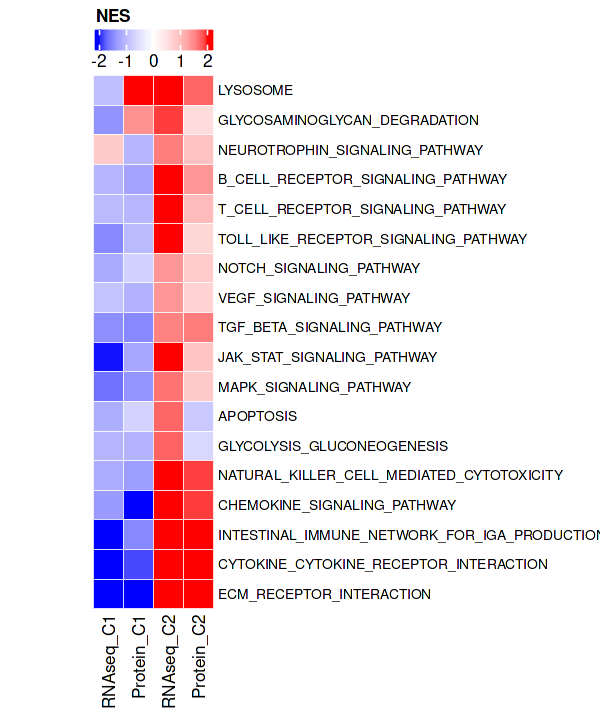

In [7]:
make.custom(5, 6)
plt = Heatmap(matrix =  mat2
              , column_title_gp = gpar(fontsize = 6)
                , show_row_dend = FALSE
#                 , column_title = paste('Protein',do,'GSEA')
                , rect_gp = gpar(col = COL_HEATMAP_BORDER, lwd=0.5)
                , name = SEL
                , column_names_gp = gpar(fontsize=10)
                , row_names_gp = gpar(fontsize=8)
        #         , top_annotation = HeatmapAnnotation(Group = anno_simple(x = colData$Group))
                , cluster_columns = FALSE
                , cluster_rows = TRUE
                , col = COL_HEATMAP_2_F
#                 , col = COL_HEATMAP_0_F
#                 , column_split = anno$Group
#                 , column_labels = anno$Cluster
               , heatmap_legend_param = list(direction = "horizontal")
              , width = unit(1, "inch")
            )
draw(plt, heatmap_legend_side = "top")

In [10]:
mat2 %>% as.data.frame %>% ysave('fig.3A.KEGG.C2.data',outputdir = OUTPUTROOT)


[1] "[ 2026-08-08 08:52:46 ]  write 1 xlsx at report_c3/fig.3A.KEGG.C2.data.xlsx"


### fig 3B immune scores

In [8]:
glx = db.importing('glx_86',frm=INPUTROOT)
glx
colData = glx %>%filter(Group!='pCR') %>% 
    select(Custom_Label = tsb, Group) %>%
    column_to_rownames('Custom_Label')
colData

[1] "[ 2026-08-03 11:44:08 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  export_c3"


tsb,Group,Response
<chr>,<chr>,<chr>
P72,C1,non.pCR
P10,C1,non.pCR
P14,C1,non.pCR
⋮,⋮,⋮
P78,pCR,pCR
P76,pCR,pCR
P79,pCR,pCR


,Group
,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [9]:
tsb.pcr = glx %>% filter(Response=='pCR') %>% pull("tsb")
tsb.pcr %>% length

[1] 9

In [10]:
timer2 = yload_dfx('export_big/estimation_matrix_frm_TPM.txt',frm=INPUTROOT) %>% 
    dplyr::select(!one_of(tsb.pcr))
# x = timer2$cell_type %>% str_split('_',simplify = TRUE)
# timer2 = timer2 %>% mutate(tool = x[,2],immune_cell=x[,1],.before = cell_type) %>% dplyr::select(!cell_type)
# timer2 %>% ydumpto('rna_timer2' ,outputdir = INPUTROOT)
timer2

[1] "[ 2026-08-03 11:44:08 ]  read [ estimation_matrix_frm_TPM.txt ] as ' estimation_matrix_frm_TPM ' from >  export_big"


tool,immune_cell,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,⋯,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TIMER,B cell,0.10047860,0.09452794,0.08935399,0.1137931,0.05830023,0.09182132,0.07142832,0.09951407,0.0750446,0.2005443,0.1077915,0.1233396,0.1242133,⋯,0.09141576,0.0812164,0.06598971,0.08126283,0.09612022,0.07962756,0.08803024,0.09200314,0.07301631,0.11874405,0.07816713,0.07890038,0.0908293,0.07992747,0.1144055
TIMER,T cell CD4+,0.09468192,0.13153552,0.15323243,0.1475723,0.11926657,0.11783247,0.12604510,0.12011638,0.1244208,0.1259290,0.1320701,0.1350576,0.1258830,⋯,0.09615568,0.1008351,0.10820859,0.07697116,0.13226824,0.08644969,0.07497028,0.09391142,0.11507615,0.07575681,0.12042994,0.14392527,0.1080741,0.13128030,0.1025655
TIMER,T cell CD8+,0.18707528,0.18348984,0.22543158,0.1853269,0.23975510,0.18647934,0.22237560,0.18424134,0.1828494,0.2085093,0.2101872,0.1816904,0.2055200,⋯,0.15526883,0.1921480,0.21960698,0.19164916,0.21909821,0.23215449,0.19299887,0.16164541,0.20239016,0.19437483,0.20329013,0.27000596,0.2160652,0.17479474,0.2004734
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ESTIMATE,immune score,1028.4165227,938.9236447,1036.1081467,1370.7872210,1630.9006928,1357.9479886,1221.8253437,889.3941420,965.3387450,1494.1774617,1084.0270926,1200.0204604,1314.493823,⋯,820.2181467,603.6068052,1244.3320771,488.5286728,2489.2164997,710.2914751,418.5464823,558.9447762,681.2545845,928.4049456,765.0579915,1312.7114237,900.3874494,1120.7720452,1263.3238379
ESTIMATE,tumor purity score,1856.5179859,1901.6296153,2114.9546774,2759.1638129,3082.2478470,2823.7589214,2145.1544829,1735.4410193,1974.7100986,2417.1564835,2065.9265941,2003.9510422,2091.382218,⋯,1897.8378099,1118.3136474,2285.4714151,1400.2634266,3989.1050659,1969.9761405,1075.6067868,672.7704753,1354.5389698,1696.1017830,1703.0315448,1933.5103056,1913.0671606,2187.2569822,2430.7780567
ESTIMATE,tumor purity fraction,0.6390741,0.6339669,0.6094434,0.5318603,0.4911164,0.5238071,0.6059228,0.6526422,0.6256345,0.5736857,0.6151333,0.6222803,0.612183,⋯,0.6343973,0.7185072,0.5894101,0.6891147,0.3711571,0.6261764,0.7228532,0.7624261,0.6939629,0.6570065,0.6562393,0.6303409,0.6326676,0.6009948,0.5720468


In [11]:
col='Group'

timer_longer = timer2 %>%
    pivot_longer(-c(tool,immune_cell)
                 , names_to = 'tsb'
                 , values_to = 'value') %>% 
    left_join(glx, by='tsb') 

timer_longer

tool,immune_cell,tsb,value,Group,Response
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
TIMER,B cell,P01,0.10047860,C3,non.pCR
TIMER,B cell,P02,0.09452794,C3,non.pCR
TIMER,B cell,P03,0.08935399,C3,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮
ESTIMATE,tumor purity fraction,P84,0.6326676,C1,non.pCR
ESTIMATE,tumor purity fraction,P85,0.6009948,C2,non.pCR
ESTIMATE,tumor purity fraction,P86,0.5720468,C2,non.pCR


In [12]:
chosen = db.importing('external_data/fig3_免疫浸润热图筛选.xlsx') 
chosen

[1] "[ 2026-08-03 11:44:08 ]  read [ fig3_免疫浸润热图筛选.xlsx ] as ' fig3_免疫浸润热图筛选 ' from >  external_data"


,id,cluster
,<chr>,<dbl>
1,XCELL immune score,1
2,CONSENSUS-TME immune score,1
3,XCELL Cancer associated fibroblast,1
⋮,⋮,⋮
36,QUANTISEQ T cell CD8+,5
37,CONSENSUS-TME T cell CD8+,5
38,CONSENSUS-TME T cell regulatory (Tregs),5


In [13]:
colData

,Group
,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [15]:
mat_heat = timer_longer %>% mutate(id = paste(tool, immune_cell)) %>% 
    select(-c(Group, Response, tool, immune_cell)) %>%
    pivot_wider(names_from = 'tsb', values_from = 'value',id_cols = 'id') %>% 
    column_to_rownames("id") %>% as.matrix

colData_heat = chosen %>% arrange(match(id, rownames(mat_heat)))

mat_heat = mat_heat[colData_heat$id,rownames(colData)] %>% yscale_rows()
dim(mat_heat)
mat_heat

[1] 38 77

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
TIMER Macrophage,-1.109269,0.4829636,-0.78583685,-1.3145303,-0.7909957,-0.6882379,1.23689298,-0.0869732,-0.1978044,0.03272058,0.3163265,-0.3738461,-0.2399499,-0.7502373,-0.6613727,⋯,-0.2417107,-0.38260524,0.5676419,-0.4553123,-0.6263648,0.2952771,-0.2964818,-0.5846497,0.3369942,-1.3529677,0.5457022,-0.04657441,-0.2081970,-0.5171814,-0.2300210
TIMER Myeloid dendritic cell,-2.152957,0.3136096,-2.40916611,-0.8893598,-0.2455716,-0.2521222,-0.23892580,-0.3777550,0.4284372,-0.65749332,-0.6047681,-0.3064951,0.7066937,-1.7383291,-0.1231800,⋯,-0.8248610,-0.08526778,0.5261946,-0.6332322,0.8983888,-0.5891634,-0.4813849,-1.3248291,-0.4616114,-0.6171042,0.8110915,0.11250373,-0.0282229,0.1293032,0.1459728
CIBERSORT NK cell activated,1.071493,-1.4081885,0.01205572,1.2616819,1.4566823,1.1939039,-0.05982405,1.1389941,1.6774786,-0.37957518,1.3662164,1.7436909,1.8603657,-1.0278018,-1.4081885,⋯,-0.9604006,0.13353733,0.0450774,0.1250638,-0.7305627,-0.4354538,0.2946683,-1.4081885,-0.1938025,-1.0387327,-0.1763221,-1.18463901,0.9225011,1.0075437,-1.4081885
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
CONSENSUS-TME Endothelial cell,-1.2593970,1.8898129,-2.719788,-0.813345,-0.4614336,-0.9135335,-0.3718144,-0.6262295,0.3421010,-0.3270534,-1.4476285,-0.7776958,0.29083085,-2.991145,-0.6854847,⋯,-1.0267862,0.008642701,-0.6866922,-0.9750692,-0.05966585,-0.352793861,-1.0928233,-1.259975,0.02287649,0.33014793,1.8472744,0.27140970,0.1038363,-0.4580554,0.02338902
CONSENSUS-TME Cancer associated fibroblast,-2.7171496,-0.8765925,-2.358988,-1.869365,-1.4834178,-0.8573856,-0.3032030,-0.1929078,1.1000423,-1.1533693,-1.4083988,0.1693194,-0.05110716,-3.493165,-2.3400930,⋯,0.2052867,-0.247661840,0.2238081,-0.5374725,0.97820872,-0.300893926,0.8385197,-1.046950,-0.02621861,0.91624262,0.5381080,-0.20353901,-0.5651144,1.0668500,0.84175430
CONSENSUS-TME immune score,-0.7089447,0.7687376,-2.817838,-1.205119,-1.1638174,-0.9918863,0.9986179,-0.4360830,-0.4704327,-1.2398469,0.2894112,-0.5259084,-0.35254175,-1.779534,2.5980821,⋯,-0.1796456,-0.110064063,-0.1335941,0.2123330,-0.30089008,-0.009436067,-0.8593031,-1.340332,0.76781712,-0.08590858,0.6736907,0.04043807,-0.2304454,-0.9257273,-0.02321027


In [16]:
stat_sel = timer_longer %>% mutate(ID = paste(tool, immune_cell)) %>% filter(ID %in% rownames(mat_heat)) %>%
    ggpubr::compare_means(formula = value~Group, group.by = "ID", method = 't.test') %>%
    rstatix::add_significance(p.col = "p.adj")
stat_sel

ID,.y.,group1,group2,p,p.adj,p.format,p.signif,method,p.adj.signif
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
TIMER Macrophage,value,C3,C2,0.013173094,0.80,0.01317,*,T-test,ns
TIMER Macrophage,value,C3,C1,0.391045096,1.00,0.39105,ns,T-test,ns
TIMER Macrophage,value,C2,C1,0.006217938,0.43,0.00622,**,T-test,ns
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
CONSENSUS-TME immune score,value,C3,C2,0.0002624369,0.026,0.00026,***,T-test,*
CONSENSUS-TME immune score,value,C3,C1,0.3861487584,1.000,0.38615,ns,T-test,ns
CONSENSUS-TME immune score,value,C2,C1,0.0006541907,0.060,0.00065,***,T-test,ns


In [17]:
SEL_COL = sym('p')
stat_mat = stat_sel %>% mutate(ig1 = c(C1=1,C2=2,C3=4)[group1], ig2 =  c(C1=1,C2=2,C3=4)[group2]) %>%
    mutate(cmp = ig1+ig2) %>%
    mutate(cmp_name = c('x','x','C1_vs_C2','x','C1_vs_C3','C2_vs_C3')[cmp]) %>%
    select(cmp_name, ID, !!SEL_COL) %>%
    pivot_wider(names_from = "cmp_name", values_from = as.character(SEL_COL)) %>%
    arrange(match(ID, rownames(mat_heat)))  %>%
    column_to_rownames("ID") %>%
    select('C1_vs_C2','C1_vs_C3','C2_vs_C3') 
x = stat_mat %>%apply(MARGIN = 1, FUN = rstatix::adjust_pvalue) %>% t 

cn = colnames(x)
for (i in cn){
  x = rstatix::add_significance(as.data.frame(x), p.col = i, cutpoints = c(0,0.05,1),symbols =c("*","ns") )   
}
va_left_mat_raw = x
pval_mat = x %>% select(C1_vs_C2,C1_vs_C3,C2_vs_C3)
signif_mat = x %>% select(C1_vs_C2 = C1_vs_C2.signif,
                        C1_vs_C3 = C1_vs_C3.signif,
                        C2_vs_C3 = C2_vs_C3.signif
                       )
signif_mat

,C1_vs_C2,C1_vs_C3,C2_vs_C3
,<chr>,<chr>,<chr>
TIMER Macrophage,*,ns,*
TIMER Myeloid dendritic cell,*,ns,*
CIBERSORT NK cell activated,*,ns,ns
⋮,⋮,⋮,⋮
CONSENSUS-TME Endothelial cell,*,*,*
CONSENSUS-TME Cancer associated fibroblast,*,*,ns
CONSENSUS-TME immune score,*,ns,*


In [18]:
pch = matrix(1:20, nc = 2)
pch[sample(length(pch), 10)] = NA
pch

1,11
NA,12
NA,13
⋮,⋮
NA,NA
NA,NA
10,NA


In [19]:
stopifnot(all(rownames(signif_mat) == rownames(mat_heat)))

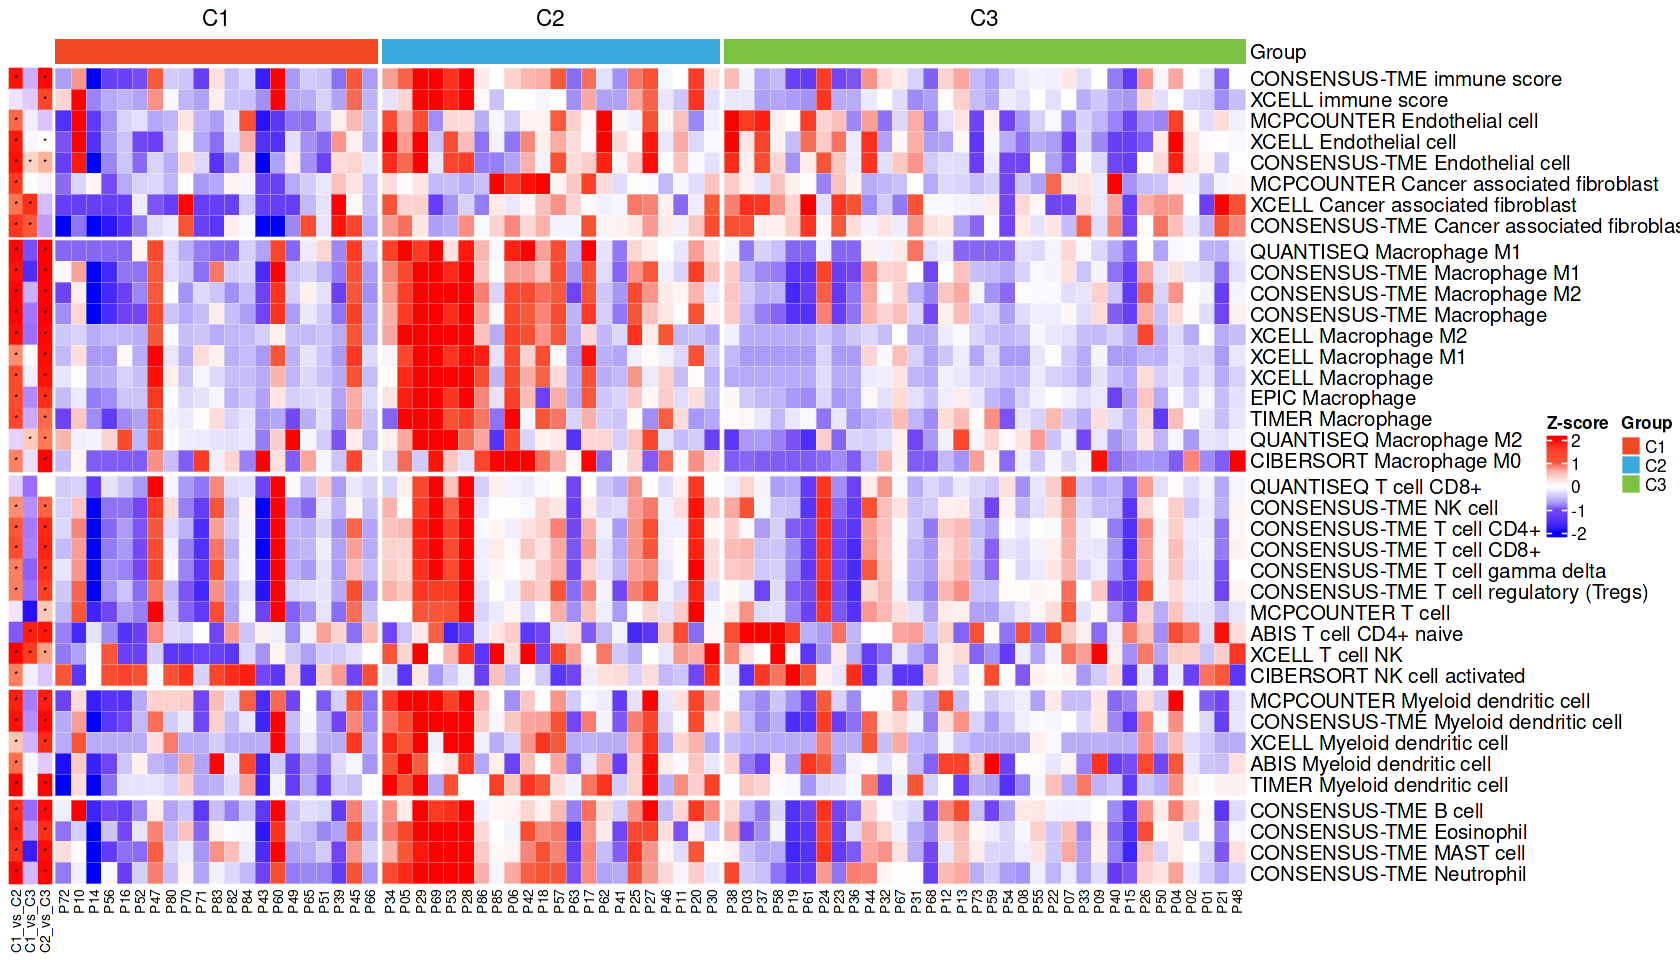

In [20]:
make.custom(14,8)
ha.top = HeatmapAnnotation(df = colData ,
                           which = 'column',
                           col=COL_ANNO,
                           na_col='white')

pch = signif_mat 
pch[pch=="ns"] = NA
pch = pch %>% as.matrix
pvalue_col_fun = circlize::colorRamp2(c(0, 0.05, 1), c("red",'white','blue')) 
va.left = HeatmapAnnotation(which = 'row', width = unit(0.35,'inch'), 
                            annotation_name_gp = gpar(fontsize=8)
                            , C1_vs_C2 = anno_simple(pval_mat$C1_vs_C2,col = pvalue_col_fun, pch= pch[,"C1_vs_C2"])
                            , C1_vs_C3 = anno_simple(pval_mat$C1_vs_C3,col = pvalue_col_fun, pch= pch[,"C1_vs_C3"])
                            , C2_vs_C3 = anno_simple(pval_mat$C2_vs_C3,col = pvalue_col_fun, pch= pch[,"C2_vs_C3"])
                           )
lgd_pvalue = Legend(title = "p-value", col_fun = pvalue_col_fun, at = c(0, 0.05, 1), 
    labels = c("0", "0.05", "1"))
gg.hm = Heatmap(mat_heat, name = 'Z-score'
                 , column_names_gp = gpar(fontsize=8)
                 , cluster_columns = FALSE
#                  , column_title = 
                 , row_title = NULL
                 , rect_gp = gpar(col = "white", lwd=0.2)
                 , col = COL_HEATMAP_F
                 , top_annotation = ha.top
                 , left_annotation = va.left
#                  , left_annotation = ha.left
#                  , cluster_rows = row_dend
                 , cluster_column_slices = FALSE
                 , clustering_method_columns = 'ward.D2'
                 , clustering_method_rows = 'ward.D2'
                 , row_split = colData_heat$cluster
                 , column_split = colData$Group
                 , show_column_names = TRUE
                 , show_row_names = TRUE, show_row_dend = FALSE)
gg.hm

In [21]:
gg.hm %>% ysave('fig.3B','immune_heatmap',outputdir = OUTPUTROOT)
mat_heat %>% as.data.frame %>% ysave('fig.3B','immune_heatmap',outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 11:45:30 ]  write 1 pdf at report_c3/fig.3B_immune_heatmap.pdf"
[1] "[ 2026-08-03 11:45:30 ]  write 1 xlsx at report_c3/fig.3B_immune_heatmap.xlsx"


### fig 3C gly heatmap

In [22]:
## The data file is generated by 
## GET_DATA_Glycosylation_Phosphorylation.ipynb

In [4]:
glx = db.importing('glx_86',frm=INPUTROOT)
colData = glx %>%filter(Group!='pCR') %>% 
    select(Custom_Label = tsb, Group) %>%
    column_to_rownames('Custom_Label')
colData

[1] "[ 2026-08-30 01:11:22 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  export_c3"


,Group
,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [5]:
a = c( 
#     c('Glycoprotein1','Protein_Name',11,9),
#     c('Glycosite2','Glycosite',11,9),
#     c('Glycans3','sGlycan',11,9),
    c('Glycopiptides4','GID',11,9)
  )

In [6]:
a

[1] "Glycopiptides4" "GID"            "11"             "9"

[1] "[ 2026-08-03 11:45:30 ]  read [ matGlycopiptides4.dfx ] as ' matGlycopiptides4 ' from >  external_data/Glycosylation/washed"
[1] "[ 2026-08-03 11:45:30 ]  read [ desGlycopiptides4.dfx ] as ' desGlycopiptides4 ' from >  external_data/Glycosylation/washed"


[1] "[ 2026-08-03 11:45:37 ]  write 1 pdf at report_c3/fig.3C_gly_filtered_Glycopiptides4.pdf"
[1] "[ 2026-08-03 11:45:37 ]  write 1 xlsx at report_c3/fig.3C_gly_filtered_Glycopiptides4.xlsx"


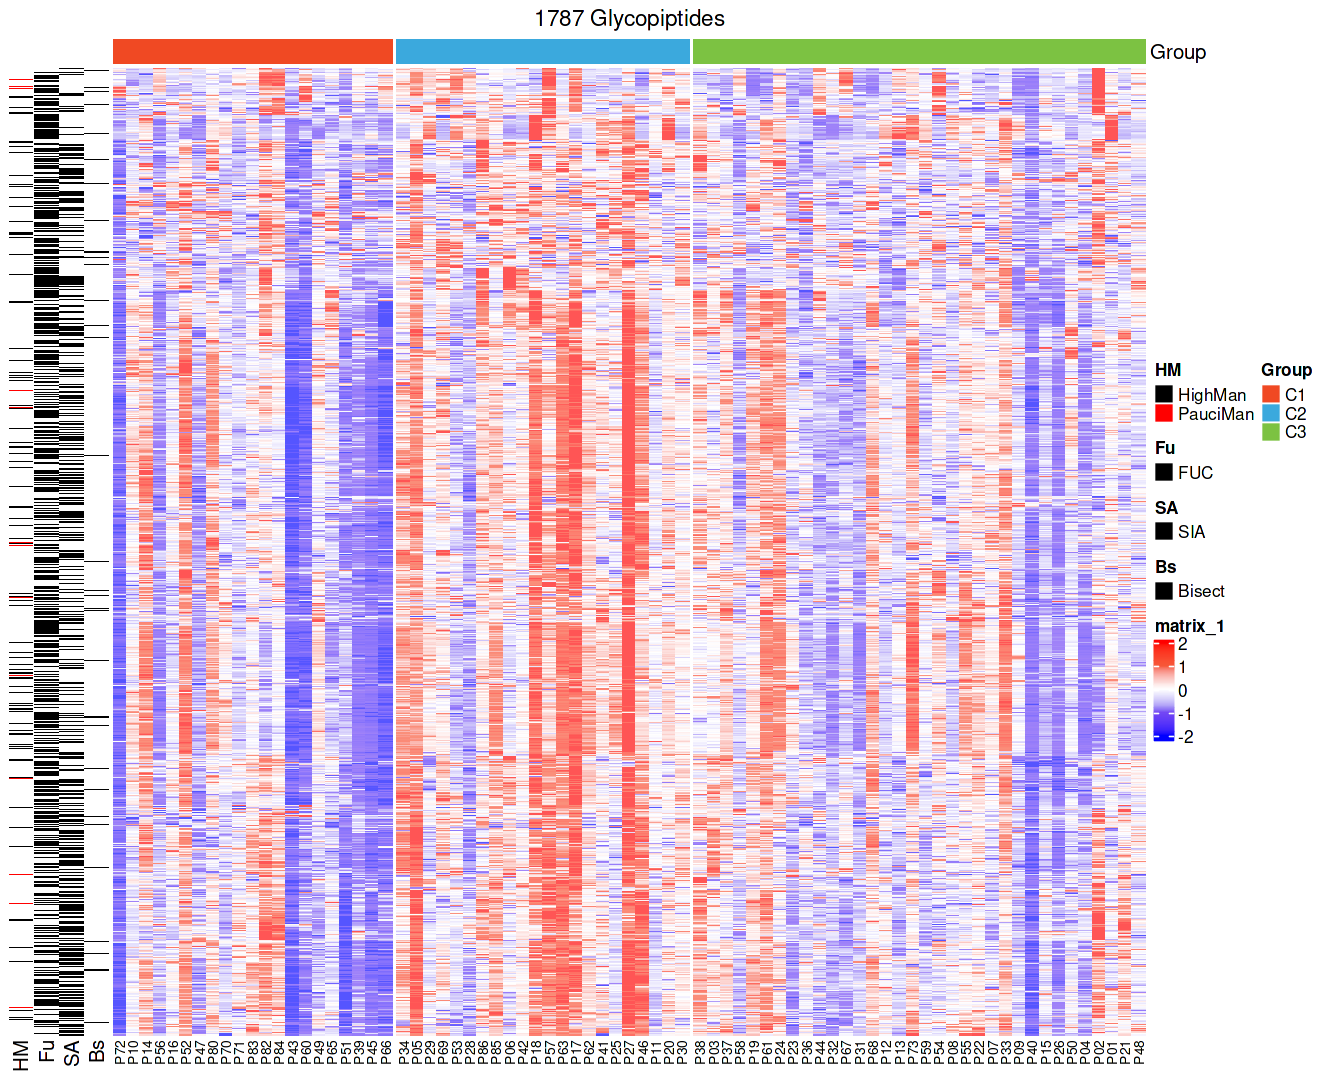

In [26]:
res.flt = list()
for (i in seq(1,length(a),by = 4)){
    vname   = a[i]
    colname = a[i+1]
    mat = db.importing(paste0('mat',vname),frm = 'external_data/Glycosylation/washed') %>% 
        column_to_rownames(colname) %>% as.matrix
    des = db.importing(paste0('des',vname),frm = 'external_data/Glycosylation/washed') %>% 
        column_to_rownames(colname) %>%
        dplyr::rename(HM = HighMannose,Fu = Fucose, SA=`Sialic Acid`,Bs = Bisect) %>%
        dplyr::select(HM,Fu,SA,Bs, everything())
    
    mat = mat[,rownames(colData)]
#     colData = colData[colnames(mat),]

    rowData = des %>% select(HM,Fu,SA,Bs) %>% mutate(across(everything(),as.factor))

    mat2 = mat %>% yscale_rows()


    make.custom(11,9)
    ha.left = HeatmapAnnotation(df = rowData, which = 'row', col = COL_ANNO,na_col='white')


    ha.top = HeatmapAnnotation(df = colData ,which = 'column',col=COL_ANNO,na_col='white')

#     rowmat = rowData %>% mutate(across(everything(), as.numeric)) %>% as.matrix %>% fill_na(0)
#     dist_matrix <- dist(rowmat, method = "euclidean")
#     row_dend <- as.dendrogram(hclust(dist_matrix))


    hm = Heatmap(mat2
                 , column_names_gp = gpar(fontsize=8)
                 , cluster_columns = FALSE
                 , column_title = paste0(nrow(mat),' ',vname %>% str_sub(1,-2),"s") %>% str_replace(fixed('ss'),'s')
                 , row_title = NULL
                 , rect_gp = gpar(col = "white", lwd=0.2)
                 , col = COL_HEATMAP_F
                 , top_annotation = ha.top
                 , left_annotation = ha.left
#                  , cluster_rows = row_dend
                 , cluster_column_slices = FALSE
                 , clustering_method_columns = 'ward.D2'
                 , clustering_method_rows = 'ward.D2'
#                  , row_split = 3
                 , column_split = colData$Group
                 , show_column_names = TRUE
                 , show_row_names = FALSE, show_row_dend = FALSE)
    View(hm)
    hm %>% ysave('fig.3C','gly','filtered',vname,outputdir =OUTPUTROOT)
    mat2 %>% as.data.frame %>% ysave('fig.3C','gly','filtered',vname,outputdir =OUTPUTROOT)
    res.flt[[vname]] = hm 
}

## fig S2J S2K S2L S2M data (glycopeptide / glycosite / glycan statistics)

In [27]:
gly_matraw = db.importing('external_data/Glycosylation/merged/gly_mat_na.dfx')
gly_raw = gly_matraw %>% pivot_longer(-GID, names_to = 'tsb', values_to = 'value') %>% filter(!is.na(value))
gly_raw

[1] "[ 2026-08-03 11:45:38 ]  read [ gly_mat_na.dfx ] as ' gly_mat_na ' from >  external_data/Glycosylation/merged"


GID,tsb,value
<chr>,<chr>,<dbl>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P10,1.4604336
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P16,0.8752324
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P19,1.1402829
⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P76,0.0000000
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P80,0.8265547
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P86,0.0000000


In [28]:
idmap = db.importing('external_data/Glycosylation/merged/255_Prt_ids_idmapping_2025_04_16.dfx') %>%
    pull(symbol,name="Protein_ID")
idmap %>% length

[1] "[ 2026-08-03 11:45:38 ]  read [ 255_Prt_ids_idmapping_2025_04_16.dfx ] as ' 255_Prt_ids_idmapping_2025_04_16 ' from >  external_data/Glycosylation/merged"


[1] 254

In [29]:
gly_des = db.importing('external_data/Glycosylation/merged/gly_mat_id_des_+class.dfx')
gly_des = gly_des %>% dplyr::select(GID,Protein_ID, Protein_Name, sProPos, sPeptide, sProPos, sGlycan, HighMannose, Fucose , `Sialic Acid`, Bisect) %>%
    mutate(sProteinNameID = paste(Protein_ID, Protein_Name, sep='_'),
           nProPos = str_count(sProPos,';') + 1,
           Glycosite = paste(sProteinNameID,sProPos,sep=':')
          )

x = gly_des$Protein_ID %>% str_split(fixed(';')) %>% sapply(function(i){
    x = idmap[i]
    x = x[!is.na(x)]
    str_flatten(unique(x),collapse = ';')
})
y = x = gly_des$Protein_ID %>% str_split(fixed(';')) %>% sapply(function(i){
    x = idmap[i]
    x = sort(x[!is.na(x)])
    ifelse(length(x) > 0, x[[1]], "")
})
gly_des$gene_symbols = x
gly_des$symbol = y
gly_des

x = gly_des[,c('HighMannose','Fucose','Sialic Acid','Bisect')] %>% as.matrix
x[is.na(x)] = ""
res = c()
for (i in 1:nrow(gly_des)){
    row = x[i,]
    row = row[row!=""]
    res = c(res, str_flatten(row,collapse = '/'))
}
gly_des$class = res
gly_data = gly_raw %>% left_join(gly_des, by='GID') %>% left_join(glx, by="tsb") 
gly_data

[1] "[ 2026-08-03 11:45:39 ]  read [ gly_mat_id_des_+class.dfx ] as ' gly_mat_id_des_+class ' from >  external_data/Glycosylation/merged"


GID,Protein_ID,Protein_Name,sProPos,sPeptide,sGlycan,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,nProPos,Glycosite,gene_symbols,symbol
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",Q9HDC9,APMAP,160,AGPNGTLFVADAYK,3 3 0 1,NA,FUC,NA,NA,Q9HDC9_APMAP,1,Q9HDC9_APMAP:160,APMAP,APMAP
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",P55083,MFAP4,111;87,FNGSVSFFR,3 2 0 0,PauciMan,NA,NA,NA,P55083_MFAP4,2,P55083_MFAP4:111;87,MFAP4,MFAP4
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",P01861,IGHG4,177,EEQFNSTYR,4 3 0 1,NA,FUC,NA,NA,P01861_IGHG4,1,P01861_IGHG4:177,IGHG4,IGHG4
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",P98160,PGBM,1755,NLHQSNTSR,3 3 0 1,NA,FUC,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2


GID,tsb,value,Protein_ID,Protein_Name,sProPos,sPeptide,sGlycan,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,nProPos,Glycosite,gene_symbols,symbol,class,Group,Response
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P10,1.4604336,Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47,HighMan,C1,non.pCR
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P16,0.8752324,Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47,HighMan,C1,non.pCR
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P19,1.1402829,Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47,HighMan,C3,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P76,0.0000000,P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,HighMan,pCR,pCR
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P80,0.8265547,P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,HighMan,C1,non.pCR
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P86,0.0000000,P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,HighMan,C2,non.pCR


In [30]:
stat_gly_data = gly_data %>% group_by(Group, tsb) %>% summarise(n=n()) %>% arrange(Group, n)
stat_gly_data

`summarise()` has grouped output by 'Group'. You can override using the `.groups` argument.


Group,tsb,n
<chr>,<chr>,<int>
C1,P39,643
C1,P45,643
C1,P66,643
⋮,⋮,⋮
pCR,P77,728
pCR,P79,728
pCR,P76,803


### fig S2J

In [31]:

gly_data = gly_data %>% mutate(tsb = factor(tsb, levels = stat_gly_data$tsb))
gly_data

GID,tsb,value,Protein_ID,Protein_Name,sProPos,sPeptide,sGlycan,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,nProPos,Glycosite,gene_symbols,symbol,class,Group,Response
<chr>,<fct>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P10,1.4604336,Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47,HighMan,C1,non.pCR
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P16,0.8752324,Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47,HighMan,C1,non.pCR
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",P19,1.1402829,Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47,HighMan,C3,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P76,0.0000000,P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,HighMan,pCR,pCR
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P80,0.8265547,P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,HighMan,C1,non.pCR
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P86,0.0000000,P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,HighMan,C2,non.pCR


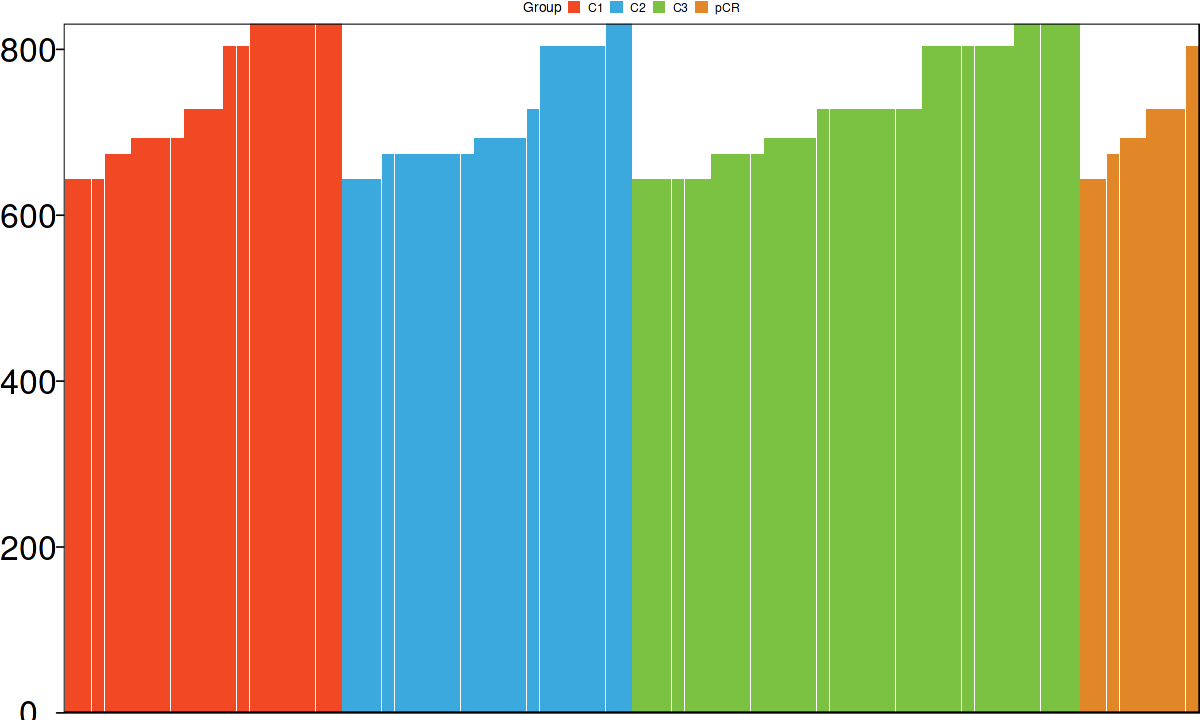

In [32]:
make.custom(10,6)
gg.basic = gly_data %>% ggplot(aes(x = tsb, fill = Group)) +
    geom_bar(stat = 'count') +
    theme_pc() +
    scale_fill_manual(breaks = names(COL_ANNO$Group4), values= COL_ANNO$Group4) +
    scale_y_continuous(expand = c(0,0)) +
    theme(axis.text.x = element_blank(), axis.ticks.x = element_blank()
         ) +
    ylab('Identified Number\n(per sample)')
    

gg.basic

In [33]:
make.custom(6,4)
gg.basic %>% ysave('fig.S2J','Identified_Number','bar', outputdir = OUTPUTROOT)
gly_data %>% ysave('fig.S2J','Identified_Number','bar', outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 11:45:40 ]  write 1 pdf at report_c3/fig.S2J_Identified_Number_bar.pdf"
[1] "[ 2026-08-03 11:45:45 ]  write 1 xlsx at report_c3/fig.S2J_Identified_Number_bar.xlsx"


### fig S2K

In [34]:
## gly_des is generated by fig S2J S2K S2L S2M data part

glycosites = gly_des %>% dplyr::select(Protein_ID,sProPos) %>% 
    separate_rows(sProPos, sep=fixed(';')) %>% 
    distinct() %>%
    group_by(Protein_ID) %>% summarise(n_glycosites = n())
glycans = gly_des %>% distinct(Protein_ID, sGlycan)%>% group_by(Protein_ID) %>% summarise(n_glycans = n())
gly_sites_cans = glycosites %>% left_join(glycans, by='Protein_ID') %>% 
    mutate(sites_cls = cut(n_glycosites, breaks = c(0,1.1,2.1,3.1,5.1,Inf),labels = c('1','2','3','4-5','>5')))
gly_sites_cans

Protein_ID,n_glycosites,n_glycans,sites_cls
<chr>,<int>,<int>,<fct>
A6NDX5,1,2,1
A8MVM7,2,4,2
C9J1S8,1,2,1
⋮,⋮,⋮,⋮
Q9Y5F3,1,1,1
Q9Y6C2,3,14,3
Q9Y6R4,1,1,1


Warning message:
“Removed 6 rows containing missing values (`geom_point()`).”


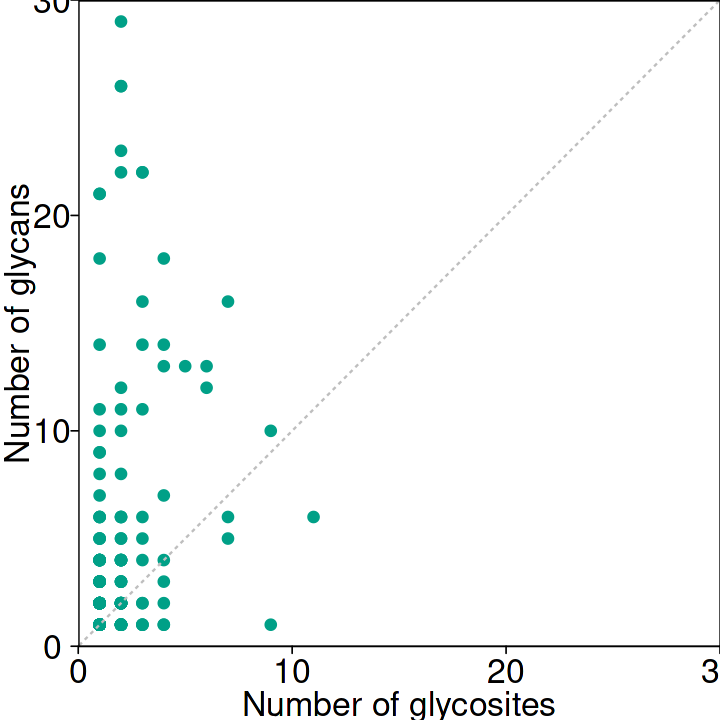

In [35]:
make.custom(6,6)
gg.sites.cans = gly_sites_cans %>% ggplot(aes(x=n_glycosites, y=n_glycans)) +
    geom_point(size =2.5, color = npg[3]) +
    geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "gray") +
#     geom_smooth(method = 'lm',color="gray",se = FALSE) +
    theme_pc() +
    scale_x_continuous(limits = c(0,30),expand = c(0,0)) +
    scale_y_continuous(limits = c(0,30),expand = c(0,0)) +
    theme(axis.title.x = element_text(), axis.title.y = element_text(angle = 90))+
    xlab("Number of glycosites") +
    ylab("Number of glycans")
    
gg.sites.cans


In [36]:
gg.sites.cans %>% ysave('fig.S2K.glycosylation_sites_scatter', outputdir = OUTPUTROOT)
gly_sites_cans %>% ysave('fig.S2K.glycosylation_sites_scatter', outputdir = OUTPUTROOT)

Warning message:
“Removed 6 rows containing missing values (`geom_point()`).”


[1] "[ 2026-08-03 11:45:46 ]  write 1 pdf at report_c3/fig.S2K.glycosylation_sites_scatter.pdf"
[1] "[ 2026-08-03 11:45:46 ]  write 1 xlsx at report_c3/fig.S2K.glycosylation_sites_scatter.xlsx"


#### fig S2L S2M pie plot

In [37]:
yplot_pie = function(input, label){
    site_colors = c(
      "1"   = "#8FCBAE",
      "2"   = "#0B8A8F",
      "3"   = "#D9D9D9",
      "4-5" = "#F5E642",
      ">5"  = "#AFD2E6"
    )
    T = 0.07
    df = input %>%
      arrange(sites_cls) %>%
      mutate(
        fraction = cnt / sum(cnt),
        pct_label = paste0(round(fraction * 100, 2), "%"),
        # cumulative positions for slice centers (pie starts at top, clockwise)
        ymax = cumsum(fraction),
        ymin = c(0, head(ymax, -1)),
        ypos = (ymin + ymax) / 2,
        csum = rev(cumsum(rev(fraction))),
        pos  = fraction / 2 + lead(csum, 1),
        pos  = if_else(is.na(pos), fraction / 2, pos)   # last slice
      )
    
    gg = ggplot(df, aes(x = "", y = fraction, fill = sites_cls)) +
      geom_col(width = 1, color = "white", linewidth = 0.6) +
      coord_polar(theta = "y", direction = -1) +
      scale_fill_manual(values = site_colors, name = label) +
      ggrepel::geom_label_repel(
          data = filter(df, fraction > T),
        aes(y = pos, label = pct_label),
        size = 4.2, nudge_x = 0.1,
        color = "black", fill = NA, label.size = NA,
        segment.color = NA, show.legend = FALSE
      ) +
      ggrepel::geom_label_repel(
          data = filter(df, fraction <= T),
        aes(y = pos, label = pct_label),
        size = 4.2, nudge_x = 0.55,
        color = "black", fill = NA, label.size = NA,
        segment.color = NA, show.legend = FALSE
      ) +
      theme_void() +
      theme(
        legend.position = "bottom",
        legend.title = element_text(face = "bold"),
        legend.text  = element_text(size = 11)
      )
    return(list(df=df, gg=gg))
}

In [38]:

# gly_sites_cans is generated by fig S2K part
sites.per.glycoprt = gly_sites_cans %>% group_by(sites_cls) %>% summarise(cnt = n())
sites.per.glycoprt


sites_cls,cnt
<fct>,<int>
1,175
2,45
3,16
4-5,13
>5,8


In [39]:
glycans.per.glycosite = gly_des %>% dplyr::select(Protein_ID,sProPos,sGlycan) %>% 
    separate_rows(sProPos, sep=fixed(';'))  %>% distinct() %>% 
    group_by(Protein_ID, sProPos) %>% summarise(n_glycans = n()) %>% 
    mutate(sites_cls = cut(n_glycans, breaks = c(0,1.1,2.1,3.1,5.1,Inf),labels = c('1','2','3','4-5','>5'))) %>%
    group_by(sites_cls) %>% summarise(cnt = n())
glycans.per.glycosite

`summarise()` has grouped output by 'Protein_ID'. You can override using the `.groups` argument.


sites_cls,cnt
<fct>,<int>
1,214
2,75
3,31
4-5,39
>5,70


**fig S2L**

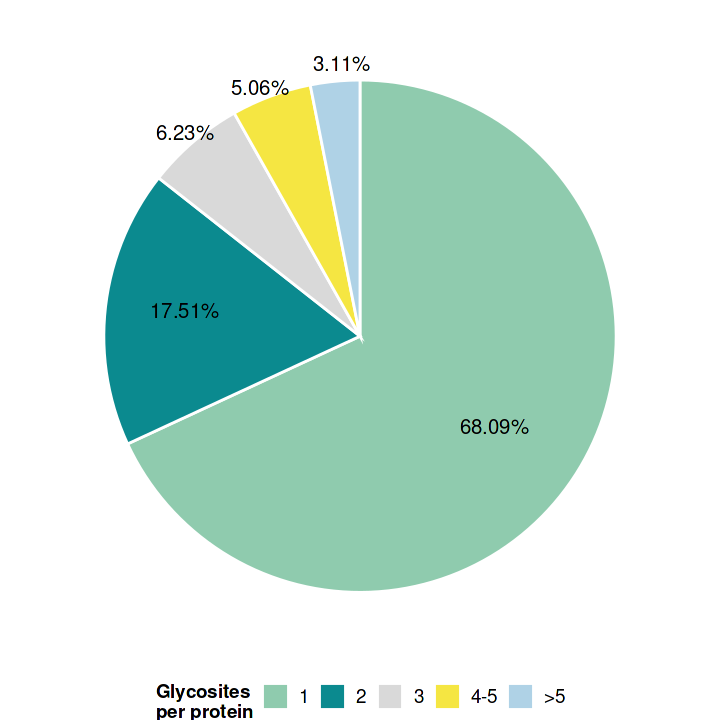

In [40]:
res.sites.per.glycoprt = yplot_pie(sites.per.glycoprt, label="Glycosites\nper protein")
res.sites.per.glycoprt$gg

In [41]:
res.sites.per.glycoprt$df %>% dplyr::rename(N_glycosite_per_glycoprotein=cnt)


sites_cls,N_glycosite_per_glycoprotein,fraction,pct_label,ymax,ymin,ypos,csum,pos
<fct>,<int>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,175,0.68093385,68.09%,0.6809339,0.0000000,0.3404669,1.00000000,0.65953307
2,45,0.17509728,17.51%,0.8560311,0.6809339,0.7684825,0.31906615,0.23151751
3,16,0.06225681,6.23%,0.9182879,0.8560311,0.8871595,0.14396887,0.11284047
4-5,13,0.05058366,5.06%,0.9688716,0.9182879,0.9435798,0.08171206,0.05642023
>5,8,0.03112840,3.11%,1.0000000,0.9688716,0.9844358,0.03112840,0.01556420


In [42]:
res.sites.per.glycoprt$gg %>% ysave("fig.S2L.glycosites_per_glycoprotein" ,outputdir = OUTPUTROOT)

res.sites.per.glycoprt$df %>% ysave("fig.S2L.data.glycosites_per_glycoprotein" ,outputdir = OUTPUTROOT)



[1] "[ 2026-08-03 11:45:47 ]  write 1 pdf at report_c3/fig.S2L.glycosites_per_glycoprotein.pdf"
[1] "[ 2026-08-03 11:45:47 ]  write 1 xlsx at report_c3/fig.S2L.data.glycosites_per_glycoprotein.xlsx"


**fig S2M**

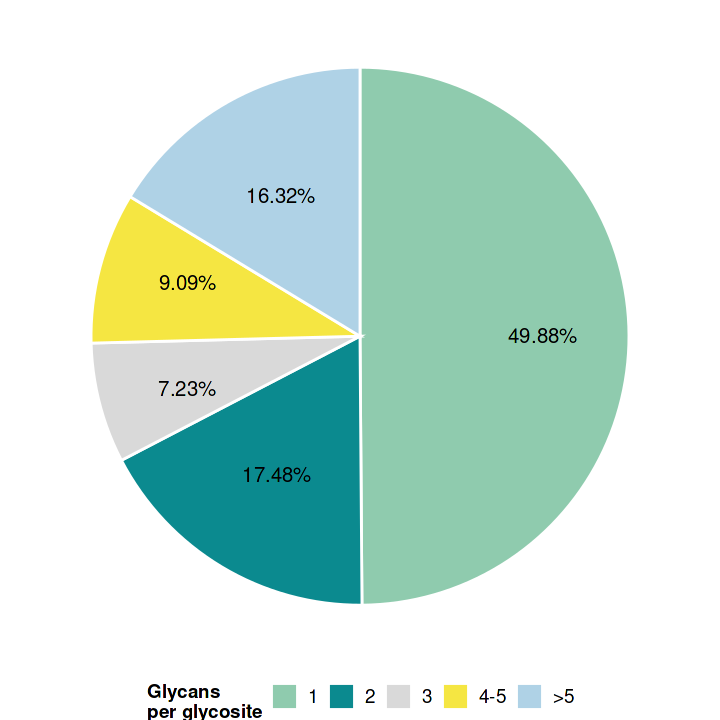

In [43]:
res.glycans.per.glycosite = yplot_pie(glycans.per.glycosite, label="Glycans\nper glycosite")
res.glycans.per.glycosite$gg

In [44]:
res.glycans.per.glycosite$df %>% dplyr::rename(N_glycans_per_glycosite=cnt)

sites_cls,N_glycans_per_glycosite,fraction,pct_label,ymax,ymin,ypos,csum,pos
<fct>,<int>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,214,0.49883450,49.88%,0.4988345,0.0000000,0.2494172,1.0000000,0.75058275
2,75,0.17482517,17.48%,0.6736597,0.4988345,0.5862471,0.5011655,0.41375291
3,31,0.07226107,7.23%,0.7459207,0.6736597,0.7097902,0.3263403,0.29020979
4-5,39,0.09090909,9.09%,0.8368298,0.7459207,0.7913753,0.2540793,0.20862471
>5,70,0.16317016,16.32%,1.0000000,0.8368298,0.9184149,0.1631702,0.08158508


In [45]:
res.glycans.per.glycosite$gg %>%  ysave('fig.S2M.glycans_per_glycosylation_site',outputdir = OUTPUTROOT)

res.glycans.per.glycosite$df %>% dplyr::rename(N_glycans_per_glycosite=cnt) %>%  ysave('fig.S2M.data.glycans_per_glycosylation_site',outputdir = OUTPUTROOT)


[1] "[ 2026-08-03 11:45:48 ]  write 1 pdf at report_c3/fig.S2M.glycans_per_glycosylation_site.pdf"
[1] "[ 2026-08-03 11:45:48 ]  write 1 xlsx at report_c3/fig.S2M.data.glycans_per_glycosylation_site.xlsx"


### fig 3D

##### calc data DE3

In [393]:
grp_new = db.importing('glx_86.dfx', frm = './export_c3/') %>% 
#     dplyr::rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification) %>% 
    filter(Group!='pCR') %>% dplyr::select(-Response)
grp_new

[1] "[ 2026-08-24 00:39:57 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  ./export_c3/"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [394]:
maty = db.importing('external_data/Glycosylation/merged/gly_mat_filled.dfx',row.names=1) %>% yscale_rows()
maty

[1] "[ 2026-08-24 00:39:58 ]  read [ gly_mat_filled.dfx ] as ' gly_mat_filled ' from >  external_data/Glycosylation/merged"


,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,⋯,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",2.5796537,-0.4160849,0.9407512,0.8060060,-1.3657456,-0.1980648,-0.01739536,0.0009654205,1.0453787,0.7505402,-0.6033523,1.995377,0.03283038,1.2395794,1.159312,⋯,0.28076227,-1.055442,0.2874709,-0.2317187,1.0393714,2.189473,0.8621541,1.4018766,0.6200423,0.9249467,-0.01380569,1.3717115,-0.65183221,1.040250830,0.5142378
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",0.1975441,-0.3950796,0.4338524,0.5244553,-1.3455132,-0.3276050,0.48051042,0.8386248251,0.4591146,0.1723064,-0.9104632,1.030980,0.89262527,1.2295211,1.135554,⋯,0.04818663,-1.373924,0.5095787,-0.6899711,1.9687727,1.710918,-0.1121070,1.0631414,-0.1143770,0.3856691,-0.03140322,1.4833241,-0.52556704,0.970571218,0.5965875
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",0.3093954,-0.6541082,0.7746147,0.3069450,-0.1009683,-0.9083038,1.05059888,0.5900086227,-0.5305705,1.1512195,0.7899250,1.793945,-0.01556450,0.3227278,1.112068,⋯,-0.56729394,-1.091907,-0.3122051,-0.8849561,0.7839359,2.294911,0.2233018,0.8961385,1.0903411,0.6347192,-0.10481092,0.8053779,-0.05848488,-0.006440703,1.2723779
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",-0.6723445,-0.3091528,-0.6719862,-0.1488892,-0.08930950,-0.4021948,0.48447620,0.04652967,-0.8644542,-0.4430628,-0.864454227,-0.1412631,-0.8644542,0.80704618,-0.8644542,⋯,-0.0435428,-0.647431,-0.7625375,-0.3005296,-0.3371291,0.3646241,-0.2273417,-0.4731636,-0.1052736,-0.5839305,-0.1755196,0.02392881,-0.27685352,-0.29272454,-0.3422808
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",-0.8338721,-0.9104908,0.6146286,1.4882079,-0.02377927,-0.2317637,-0.02769954,0.22930464,-0.5270410,-1.0139092,1.232035505,0.3880382,1.7630825,2.15219228,0.7955350,⋯,0.1906287,1.452219,-0.4364927,-0.7500925,-1.8890075,-0.1337339,-0.8335786,0.2104962,-1.1317229,0.0524531,0.4094244,-0.62240540,0.01062978,0.55589306,1.3672929
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",-0.1303630,0.5212724,0.4719965,0.2697509,0.15745608,-0.3693487,0.16090836,1.20489403,1.6377314,0.7741255,-0.005893712,0.7049622,2.5541673,0.02299814,0.6089213,⋯,0.7953326,-2.164403,-0.9196323,-0.5089444,-0.2842772,-2.1644030,-2.1644030,-2.1644030,-2.1644030,-0.3098489,-2.1644030,0.35557753,-2.16440300,-0.09854042,-2.1644030


In [395]:
idmap = db.importing('external_data/Glycosylation/merged/255_Prt_ids_idmapping_2025_04_16.dfx') %>%
    pull(symbol,name="Protein_ID")
idmap %>% length

gly_des = db.importing('external_data/Glycosylation/merged/gly_mat_id_des_+class.dfx')

gly_des = gly_des %>% dplyr::select(GID,Protein_ID, Protein_Name, sProPos, sPeptide, sProPos, sGlycan, HighMannose, Fucose , `Sialic Acid`, Bisect) %>%
    mutate(sProteinNameID = paste(Protein_ID, Protein_Name, sep='_'),
           nProPos = str_count(sProPos,';') + 1,
           Glycosite = paste(sProteinNameID,sProPos,sep=':')
          )

x = gly_des$Protein_ID %>% str_split(fixed(';')) %>% sapply(function(i){
    x = idmap[i]
    x = x[!is.na(x)]
    str_flatten(unique(x),collapse = ';')
})
y = x = gly_des$Protein_ID %>% str_split(fixed(';')) %>% sapply(function(i){
    x = idmap[i]
    x = sort(x[!is.na(x)])
    ifelse(length(x) > 0, x[[1]], "")
})
gly_des$gene_symbols = x
gly_des$symbol = y
gly_des


[1] "[ 2026-08-24 00:39:59 ]  read [ 255_Prt_ids_idmapping_2025_04_16.dfx ] as ' 255_Prt_ids_idmapping_2025_04_16 ' from >  external_data/Glycosylation/merged"


[1] 254

[1] "[ 2026-08-24 00:39:59 ]  read [ gly_mat_id_des_+class.dfx ] as ' gly_mat_id_des_+class ' from >  external_data/Glycosylation/merged"


GID,Protein_ID,Protein_Name,sProPos,sPeptide,sGlycan,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,nProPos,Glycosite,gene_symbols,symbol
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",Q08722,CD47,73,DIYTFDGALNK,5 2 0 0,HighMan,NA,NA,NA,Q08722_CD47,1,Q08722_CD47:73,CD47,CD47
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",Q9HDC9,APMAP,160,AGPNGTLFVADAYK,3 3 0 1,NA,FUC,NA,NA,Q9HDC9_APMAP,1,Q9HDC9_APMAP:160,APMAP,APMAP
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",P55083,MFAP4,111;87,FNGSVSFFR,3 2 0 0,PauciMan,NA,NA,NA,P55083_MFAP4,2,P55083_MFAP4:111;87,MFAP4,MFAP4
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",P01861,IGHG4,177,EEQFNSTYR,4 3 0 1,NA,FUC,NA,NA,P01861_IGHG4,1,P01861_IGHG4:177,IGHG4,IGHG4
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",P98160,PGBM,1755,NLHQSNTSR,3 3 0 1,NA,FUC,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",P98160,PGBM,1755,NLHQSNTSR,5 2 0 0,HighMan,NA,NA,NA,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2


In [398]:
DE3 = list()
clusters = c("C1",'C2',"C3")
for (cluster in clusters){
    colData = grp_new %>% mutate(Group = ifelse(Group==!!cluster,cluster,'Others')) 
    
    cat('  Running',cluster,'\n')
    omic_names = c(Glycosylation='maty')

    for (name in names(omic_names)){
        mat = get(omic_names[name], envir = .GlobalEnv)
        mat = mat[,colData$tsb]

        x = mat %>% apply(1, sd)
        mat = mat[x != 0,]
        cat(omic_names[name], dim(mat), nrow(colData),'\n')
        deg = ydo_numeric_DEG_limma(numeric.sorted = mat, 
                                    colData.sorted = colData, 
                                    col.id = 'tsb', 
                                    col.group = 'Group', 
                                    level_order = c('Others',cluster))
        deg = deg %>% rename(Delta_IonStrength=log2FoldChange, abs_Delta_IonS=abs_log2FC, Delta_Ins=FC_Ins)
        tag = paste(name, cluster, sep='_')
        DE3[[tag]] = deg %>% dplyr::rename(GID=symbol)%>% left_join(gly_des, by='GID')
    }
}

  Running C1 
maty 1787 77 77 
-------------------------------------------------------------
Comparing >  unpaired  <  C1 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
  Running C2 
maty 1787 77 77 
-------------------------------------------------------------
Comparing >  unpaired  <  C2 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
  Running C3 
maty 1787 77 77 
-------------------------------------------------------------
Comparing >  unpaired  <  C3 - Others , REF_GROUP =  Others 
-------------------------------------------------------------


In [400]:
saveRDS(DE3,file.path('export_c3/','fig3_de_glycopeptide.RDS'))

In [401]:
DE3$Glycosylation_C1

GID,Delta_IonStrength,baseMean,t,pvalue,padj,B,stat,abs_Delta_IonS,Delta_Ins,median_C1,median_Others,Protein_ID,Protein_Name,sProPos,sPeptide,sGlycan,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,nProPos,Glycosite,gene_symbols,symbol
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
"P01859:IGHG2:176:TKPREEQFNSTFR:1,IBT16[N-term];2,IBT16[K]:3 5 0 1:3",-0.9923579,0.01945826,-3.973976,7.071975e-05,0.02066028,1.387587,-3.973976,0.9923579,FALSE,-0.9889101,0.189297142,P01859,IGHG2,176,TKPREEQFNSTFR,3 5 0 1,NA,FUC,NA,Bisect,P01859_IGHG2,1,P01859_IGHG2:176,IGHG2,IGHG2
"P00734:THRB:121:GHVNITR:1,IBT16[N-term]:5 4 0 2:3",-0.9896261,-0.03750889,-3.963036,7.404085e-05,0.02066028,1.348060,-3.963036,0.9896261,FALSE,-1.0086962,0.231489465,P00734,THRB,121,GHVNITR,5 4 0 2,NA,FUC,NA,NA,P00734_THRB,1,P00734_THRB:121,F2,F2
"P01009:A1AT:271:YLGNATAIFFLPDEGK:1,IBT16[N-term];16,IBT16[K]:4 9 0 0:4",-0.9521726,-0.08004431,-3.813051,1.373233e-04,0.02066028,0.817118,-3.813051,0.9521726,FALSE,-1.0166029,-0.004663614,P01009,A1AT,271,YLGNATAIFFLPDEGK,4 9 0 0,NA,NA,NA,NA,P01009_A1AT,1,P01009_A1AT:271,SERPINA1,SERPINA1
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P21810:PGS1:281:MIENGSLSFLPTLR:1,IBT16[N-term];1,Oxidation[M]:4 4 0 0:4",0.0024561305,-0.031285021,0.009835769,0.9921523,0.9932640,-5.801682,0.009835769,0.0024561305,TRUE,-0.1667007,-0.13030535,P21810,PGS1,281,MIENGSLSFLPTLR,4 4 0 0,NA,NA,NA,NA,P21810_PGS1,1,P21810_PGS1:281,BGN,BGN
"Q9UN30:SCML1:148:ENNSPSNLPR:1,IBT16[N-term]:5 4 1 1:3",-0.0008147970,-0.006910292,-0.003262919,0.9973966,0.9979550,-5.801721,-0.003262919,0.0008147970,FALSE,0.3196549,0.07774919,Q9UN30,SCML1,148,ENNSPSNLPR,5 4 1 1,NA,FUC,SIA,NA,Q9UN30_SCML1,1,Q9UN30_SCML1:148,SCML1,SCML1
"P01857;P0DOX5:IGHG1;IGG1:299;180:EEQYNSTYR:1,IBT16[N-term]:3 3 0 1:3",0.0005823588,-0.021023046,0.002332102,0.9981393,0.9981393,-5.801724,0.002332102,0.0005823588,TRUE,-0.3025947,-0.19140745,P01857;P0DOX5,IGHG1;IGG1,299;180,EEQYNSTYR,3 3 0 1,NA,FUC,NA,NA,P01857;P0DOX5_IGHG1;IGG1,2,P01857;P0DOX5_IGHG1;IGG1:299;180,IGHG1,IGHG1


In [402]:
DE3 %>% ysave('fig.3D.data','DE_GLY_C1-C3', outputdir = OUTPUTROOT, table_title_lines = NULL)


[1] "[ 2026-08-24 00:41:04 ]  write 1 xlsx at report_c3/fig.3D.data_DE_GLY_C1-C3.xlsx"


##### plot bar plot using DE3

In [432]:
DE3 = readRDS(file.path('export_c3/','fig3_de_glycopeptide.RDS'))
DE3 %>% names


[1] "Glycosylation_C1" "Glycosylation_C2" "Glycosylation_C3"

In [404]:
## need the following var generated by fig.3D 1.4.3.1 calc data DE3 part
clusters = c("C1",'C2',"C3")
# gly_des

In [406]:
r = clusters %>% purrr::map_df(function(i){
    tag = paste0('Glycosylation_',i)
    gids = DE3[[tag]] %>% arrange(desc(Delta_IonStrength)) %>% filter(Delta_Ins) %>% head(100) %>% pull(GID)
    gly_des %>% filter(GID %in% !!gids) %>%mutate(Group=!!i)
})
r

GID,Protein_ID,Protein_Name,sProPos,sPeptide,sGlycan,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,nProPos,Glycosite,gene_symbols,symbol,Group
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3",P55083,MFAP4,111;87,FNGSVSFFR,4 2 0 0,HighMan,NA,NA,NA,P55083_MFAP4,2,P55083_MFAP4:111;87,MFAP4,MFAP4,C1
"P10253:LYAG:470:GVFITNETGQPLIGK:1,IBT16[N-term];15,IBT16[K]:4 2 0 0:4",P10253,LYAG,470,GVFITNETGQPLIGK,4 2 0 0,HighMan,NA,NA,NA,P10253_LYAG,1,P10253_LYAG:470,GAA,GAA,C1
"P01857;P0DOX5:IGHG1;IGG1:299;180:EEQYNSTYR:1,IBT16[N-term]:3 3 0 1:2",P01857;P0DOX5,IGHG1;IGG1,299;180,EEQYNSTYR,3 3 0 1,NA,FUC,NA,NA,P01857;P0DOX5_IGHG1;IGG1,2,P01857;P0DOX5_IGHG1;IGG1:299;180,IGHG1,IGHG1,C1
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 0 1:3",P12109,CO6A1,212,RNFTAADWGQSR,5 4 0 1,NA,FUC,NA,NA,P12109_CO6A1,1,P12109_CO6A1:212,COL6A1,COL6A1,C3
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:4 5 1 1:3",P98160,PGBM,1755,NLHQSNTSR,4 5 1 1,NA,FUC,SIA,Bisect,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,C3
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 5 1 1:3",P98160,PGBM,1755,NLHQSNTSR,5 5 1 1,NA,FUC,SIA,Bisect,P98160_PGBM,1,P98160_PGBM:1755,HSPG2,HSPG2,C3


In [407]:
r %>%group_by(Group) %>% summarise(n())

Group,n()
<chr>,<int>
C1,76
C2,100
C3,100


In [408]:
cols = c('HighMannose','Fucose','Sialic Acid','Bisect')
r2 = cols %>% purrr::map_df(function(i){
    r %>% mutate(!!sym(i):= fill_na(!!sym(i),paste('No',i))) %>%
        group_by(Group, !!sym(i)) %>% 
        summarise(type = !!i, 
                  mean = n()) %>% 
                            dplyr::select(Group,class = !!sym(i), 
                  type, mean)
})
r2 = r2 %>% 
    filter(Group!='pCR') %>% 
    mutate(class = ifelse(class =='No Sialic Acid','Others', class))
r2

`summarise()` has grouped output by 'Group'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'Group'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'Group'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'Group'. You can override using the `.groups` argument.


Group,class,type,mean
<chr>,<chr>,<chr>,<int>
C1,HighMan,HighMannose,17
C1,No HighMannose,HighMannose,57
C1,PauciMan,HighMannose,2
⋮,⋮,⋮,⋮
C2,No Bisect,Bisect,100
C3,Bisect,Bisect,7
C3,No Bisect,Bisect,93


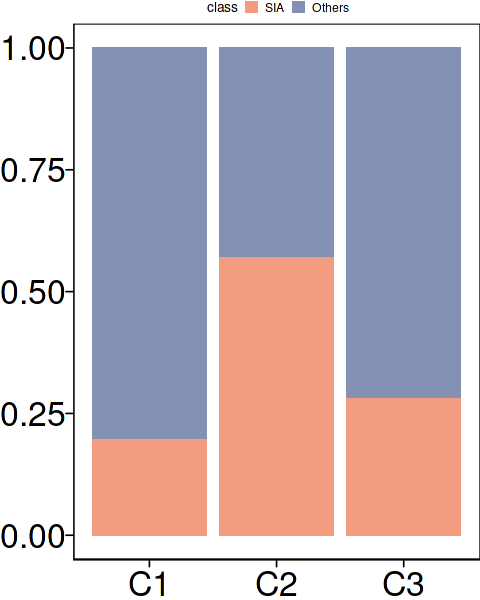

In [409]:
make.custom(4,5)
r2.sia = r2 %>% filter(type=='Sialic Acid')
gg.sa = r2.sia %>% 
    ggplot(aes(x = Group, y = mean, fill = class)) +
        geom_bar(stat = 'identity', position = 'fill')+
        theme_pc() +
        scale_fill_manual(breaks = names(COL_SIA), values = COL_SIA)
gg.sa

In [441]:
# Build contingency table first
contingency_table <- r2.sia %>%
  dplyr::select(Group, class, mean) %>%
  pivot_wider(names_from = Group, values_from = mean) %>%
  column_to_rownames("class") %>%
  as.matrix()

contingency_table

# Pairwise chi-square tests
chisq_C1_C2 <- chisq.test(contingency_table[, c("C1", "C2")])
chisq_C3_C2 <- chisq.test(contingency_table[, c("C3", "C2")])
chisq_C1_C3 <- chisq.test(contingency_table[, c("C1", "C3")])

# --- Or as a tidy summary table ---
pairwise_results <- tibble(
  comparison  = c("C1 vs C2", "C3 vs C2", "C1 vs C3"),
  chi_sq      = c(chisq_C1_C2$statistic, chisq_C3_C2$statistic, chisq_C1_C3$statistic),
  df          = c(chisq_C1_C2$parameter, chisq_C3_C2$parameter, chisq_C1_C3$parameter),
  p.value     = c(chisq_C1_C2$p.value,   chisq_C3_C2$p.value,   chisq_C1_C3$p.value)
) %>%
  mutate(
    p.adj      = p.adjust(p.value, method = "bonferroni"),  # adjust for 3 comparisons
    significance = case_when(
      p.adj < 0.001 ~ "***",
      p.adj < 0.01  ~ "**",
      p.adj < 0.05  ~ "*",
      TRUE          ~ "ns"
    )
  )

pairwise_results


,C1,C2,C3
Others,61,43,72
SIA,15,57,28


comparison,chi_sq,df,p.value,p.adj,significance
<chr>,<dbl>,<int>,<dbl>,<dbl>,<chr>
C1 vs C2,23.286352,1,1.395870e-06,4.187611e-06,***
C3 vs C2,16.040921,1,6.198815e-05,1.859645e-04,***
C1 vs C3,1.180773,1,2.771986e-01,8.315959e-01,ns


In [60]:
gg.sa %>% ysave("fig.3D.sialylated_glycopeptides_portion",outputdir = OUTPUTROOT)
r2.sia %>% ysave("fig.3D.sialylated_glycopeptides_portion",outputdir = OUTPUTROOT)

[1] "[ 2026-08-03 11:45:51 ]  write 1 pdf at report_c3/fig.3D.sialylated_glycopeptides_portion.pdf"
[1] "[ 2026-08-03 11:45:51 ]  write 1 xlsx at report_c3/fig.3D.sialylated_glycopeptides_portion.xlsx"


### fig S5G bar

In [61]:
# using @r2 generated by `fig.3D 1.4.3.1 calc data DE3`

In [442]:
COL_GLYCANS = c(Bisect=npg[7],
                CoreFUC=npg[7],FUC=npg[5],
                HighMan=npg[7],PauciMan=npg[5],
                SIA=npg[5],Others=npg[6])
r2 = r2 %>% mutate(class=ifelse(class%>% str_starts('No '), 'Others',class)) %>%
    dplyr::rename(Glycans=class)

r2$class %>% unique
COL_GLYCANS

Warning message:
“Unknown or uninitialised column: `class`.”


NULL

Bisect     CoreFUC         FUC     HighMan    PauciMan         SIA 
"#91D1C2FF" "#91D1C2FF" "#F39B7FFF" "#91D1C2FF" "#F39B7FFF" "#F39B7FFF" 
     Others 
"#8491B4FF"

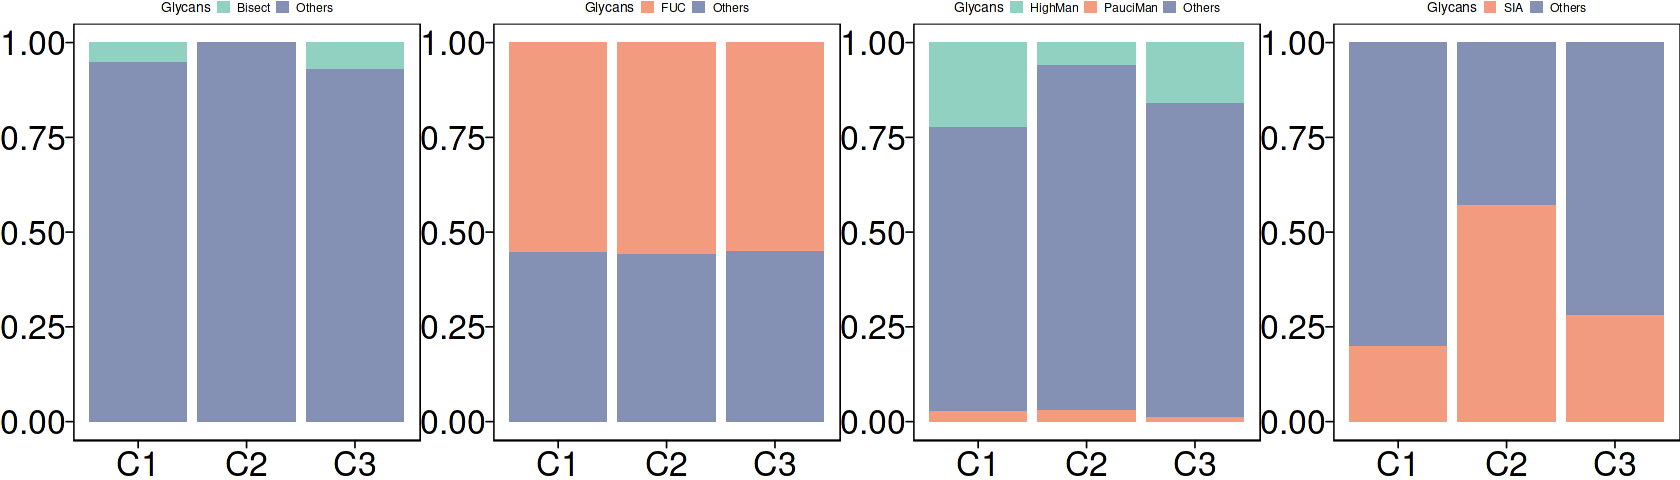

In [444]:
make.custom(14,4)

gg.list = r2 %>% group_by(type) %>% group_map(.keep = TRUE, function(df, cls){
    cls = as.character(cls)
#     df2 <<- df
#     stop("!")
    gg = df %>% ggplot(aes(x = Group, y = mean, fill = Glycans)) +
        geom_bar(stat = 'identity', position = 'fill') +
    #     facet_wrap(~type, nrow=1) +
        theme_pc() +
        scale_fill_manual(values = COL_GLYCANS, breaks=names(COL_GLYCANS))
    gg
})
gg = cowplot::plot_grid(plotlist = gg.list, nrow = 1)
# gg = r2 %>% ggplot(aes(x = Group, y = mean, fill = class)) +
#     geom_bar(stat = 'identity', position = 'fill')+
#     facet_wrap(~type, nrow=1) +
#     theme_pc() +
#     ggsci::scale_color_material()
gg

In [456]:
pairwise_results_all <- r2 %>%
  group_by(type) %>%
  group_modify(~ {
    ct <- .x %>%
      dplyr::select(Group, Glycans, mean) %>%
      pivot_wider(names_from = Group, values_from = mean, values_fill = 0) %>%
      column_to_rownames("Glycans") %>%
      as.matrix()

    # all Group pairs present in this type
    pairs <- combn(colnames(ct), 2, simplify = FALSE)

    purrr::map_df(pairs, function(p) {
      tst <- chisq.test(ct[, p])
      tibble(
        comparison = paste(p[1], "vs", p[2]),
        chi_sq     = unname(tst$statistic),
        df         = unname(tst$parameter),
        p.value    = tst$p.value
      )
    })
  }) %>%
  mutate(p.adj = p.adjust(p.value, method = "bonferroni")) %>%  # per-type (still grouped)
  ungroup() %>%
  mutate(significance = case_when(
    p.adj < 0.001 ~ "***",
    p.adj < 0.01  ~ "**",
    p.adj < 0.05  ~ "*",
    TRUE          ~ "ns"
  ))

pairwise_results_all

Warning message in chisq.test(ct[, p]):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(ct[, p]):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(ct[, p]):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(ct[, p]):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(ct[, p]):
“Chi-squared approximation may be incorrect”
Warning message in chisq.test(ct[, p]):
“Chi-squared approximation may be incorrect”


type,comparison,chi_sq,df,p.value,p.adj,significance
<chr>,<chr>,<dbl>,<int>,<dbl>,<dbl>,<chr>
Bisect,C1 vs C2,3.27657283,1,0.07027554,0.21082661,ns
Bisect,C1 vs C3,0.02470175,1,0.87511251,1.00000000,ns
Bisect,C2 vs C3,5.32938564,1,0.02096878,0.06290633,ns
⋮,⋮,⋮,⋮,⋮,⋮,⋮
Sialic Acid,C1 vs C2,23.286352,1,1.395870e-06,4.187611e-06,***
Sialic Acid,C1 vs C3,1.180773,1,2.771986e-01,8.315959e-01,ns
Sialic Acid,C2 vs C3,16.040921,1,6.198815e-05,1.859645e-04,***


In [458]:
gg %>% ysave("fig.S5G.glycan_portion_bar",outputdir = OUTPUTROOT)
pairwise_results_all %>% ysave("fig.S5G.glycan_stat_pairwise_results_portion_bar",outputdir = OUTPUTROOT)

[1] "[ 2026-08-09 08:48:52 ]  write 1 pdf at report_c3/fig.S5G.glycan_portion_bar.pdf"
[1] "[ 2026-08-09 08:48:52 ]  write 1 xlsx at report_c3/fig.S5G.glycan_stat_pairwise_results_portion_bar.xlsx"


## Gen matp, matr, matg

In [17]:
des = db.importing('external_data/Glycosylation/merged/gly_mat_id_des_x.dfx') %>% dplyr::select(!V1)
des

[1] "[ 2026-09-12 14:16:43 ]  read [ gly_mat_id_des_x.dfx ] as ' gly_mat_id_des_x ' from >  external_data/Glycosylation/merged"


GID,Protein_Name,Protein_ID,sPeptide,sProPos,sGlycan,sMod,sCharge,Spectrum_ID,batch,Rank,Peptide,Proteins,Charge,"Glycan(H,N,A,F)",Empty_Separator,GlyMass,Glytoucan_search,GlycanComposition,Supp_Info,repeat,tool
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<int>,<int>,<chr>,<chr>,<int>,<chr>,<lgl>,<dbl>,<chr>,<chr>,<lgl>,<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",CD47,Q08722,DIYTFDGALNK,73,5 2 0 0,"1,IBT16[N-term];11,IBT16[K]",3,27788.28,1,1,DIYTFDGALJK,sp|Q08722|CD47_HUMAN;sp|Q08722-2|CD47_HUMAN;sp|Q08722-3|CD47_HUMAN;sp|Q08722-4|CD47_HUMAN,3,5 2 0 0,NA,1216.4229,"5 hex, 2 hexnac, 0 neu5ac, 0 dhex",H(5)N(2),NA,E,pGlyco
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",APMAP,Q9HDC9,AGPNGTLFVADAYK,160,3 3 0 1,"1,IBT16[N-term];14,IBT16[K]",3,26727.27,1,1,AGPJGTLFVADAYK,sp|Q9HDC9|APMAP_HUMAN;sp|Q9HDC9-2|APMAP_HUMAN,3,3 3 0 1,NA,1241.4545,"3 hex, 3 hexnac, 0 neu5ac, 1 dhex",H(3)N(3)F(1),NA,E,pGlyco
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",MFAP4,P55083,FNGSVSFFR,111;87,3 2 0 0,"1,IBT16[N-term]",3,25538.26,1,1,FJGSVSFFR,sp|P55083|MFAP4_HUMAN;sp|P55083-2|MFAP4_HUMAN,3,3 2 0 0,NA,892.3172,"3 hex, 2 hexnac, 0 neu5ac, 0 dhex",H(3)N(2),NA,E,pGlyco
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P01009:A1AT:107:ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR:1,IBT16[N-term]:4 5 1 0:4",A1AT,P01009,ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR,107,4 5 1 0,"1,IBT16[N-term]",4,42233.42,6,2,K.[+277.18814].ADTHDEILEGLNFN[+2261.79390]LTEIPEAQIHEGFQELLR.T,>sp|P01009|A1AT_HUMAN Alpha-1-antitrypsin OS=Homo sapiens OX=9606 GN=SERPINA1 PE=1 SV=3,4,4 5 1 0,NA,2261.794,"4 hex, 5 hexnac, 1 neu5ac, 0 dhex",H(4)N(5)A(1),NA,5,byonic
"P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR:1,IBT16[N-term];19,Oxidation[M]:6 5 0 1:4",CO6A1,P12109,ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,6 5 0 1,"1,IBT16[N-term];19,Oxidation[M]",4,42394.42,6,3,R.[+277.18814].ASLQFLQN[+2133.77171]YTALASAVDAM[+15.99492]DFINDATDVNDALGYVTR.F,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) chain OS=Homo sapiens OX=9606 GN=COL6A1 PE=1 SV=3,4,6 5 0 1,NA,2133.772,"6 hex, 5 hexnac, 0 neu5ac, 1 dhex",H(6)N(5)F(1),NA,5,byonic
"P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR:1,IBT16[N-term];19,Oxidation[M]:5 4 2 1:4",CO6A1,P12109,ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,5 4 2 1,"1,IBT16[N-term];19,Oxidation[M]",4,42923.43,6,3,R.[+277.18814].ASLQFLQN[+2350.83035]YTALASAVDAM[+15.99492]DFINDATDVNDALGYVTR.F,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) chain OS=Homo sapiens OX=9606 GN=COL6A1 PE=1 SV=3,4,5 4 2 1,NA,2350.830,"5 hex, 4 hexnac, 2 neu5ac, 1 dhex",H(5)N(4)A(2)F(1),NA,5,byonic


In [57]:
# # library(org.Hs.eg.db)
# library(dplyr)

In [18]:
df_mat = db.importing('external_data/Glycosylation/merged/gly_mat_filled.dfx', row.names=1) 

df_raw = df_mat %>%
    rownames_to_column('GID') %>% 
    pivot_longer(-GID, names_to = 'tsb',values_to = 'Intensity') %>% 
    left_join(des %>% dplyr::select(GID, Protein_ID, Protein_Name), by="GID")

matg = df_raw %>% group_by(Protein_Name, tsb) %>% summarise(sum = sum(Intensity))  %>%  
    pivot_wider(id_cols = "Protein_Name", names_from = "tsb", values_from = 'sum') 
#     column_to_rownames('Protein_ID') %>% as.matrix

# 把Protein_ID 转换为symbol
# protein_name = AnnotationDbi::select(org.Hs.eg.db, keys = matg$Protein_ID, columns = c("SYMBOL", "UNIPROT"),
#                                      keytype = "UNIPROT") %>%
#     filter(!is.na(SYMBOL)) %>% dplyr::rename(Protein_ID = UNIPROT)


# protein_name = db.importing('external_data/Glycosylation/merged/255_Prt_ids_idmapping_2025_04_16.dfx') %>% 
#     dplyr::rename(SYMBOL=symbol)

# matg = matg %>% right_join(des, by='Protein_ID') %>%  ungroup()%>%
#     dplyr::select(-Protein_ID)

# 合并同SYMBOL的行,取mean
G = c()
matg = matg %>% group_by(Protein_Name) %>% group_map(.f = function(df, g){
        g = as.character(g)
        G <<- c(G,g)
        df %>% apply(2,mean)
    }) %>% bind_rows() %>% mutate(Protein_Name=!!G) %>%  
    arrange(Protein_Name) %>%
    column_to_rownames("Protein_Name")

matg


[1] "[ 2026-09-12 14:16:44 ]  read [ gly_mat_filled.dfx ] as ' gly_mat_filled ' from >  external_data/Glycosylation/merged"


`summarise()` has grouped output by 'Protein_Name'. You can override using the `.groups` argument.


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5HT3B,0.9427611,1.072619,1.001175,0.7677328,1.174516,0.9768532,0.8589365,1.126252,0.8662668,0.8609391,0.8995045,0.8586869,0.8311066,1.103682,0.8464158,⋯,0.6800192,0.733421,1.014267,0.7943603,0.9704764,2.124826,0.886061,0.8773423,0.9806683,1.359626,0.9659444,1.253134,1.044535,1.111634,1.061876
A1AG1,32.1182006,37.815996,33.737265,27.7773513,42.722913,30.6918426,30.5858317,30.718145,29.3967511,31.4151766,30.1071546,32.6474001,28.8297197,37.026966,30.1114187,⋯,21.6055238,36.073818,38.436053,30.0173543,29.2649452,37.475659,29.260497,34.8243163,35.4805262,35.891174,37.1842613,33.581278,36.505879,39.501304,36.638354
A1AG2,14.6806259,16.997550,15.117448,12.7337357,21.198226,14.3697177,13.7870224,13.786840,13.8669409,14.0645197,13.7651804,13.9107561,13.9047581,17.715424,13.7370927,⋯,9.9092720,16.959813,17.244021,13.8553775,14.3870446,17.175342,13.283888,15.9691346,15.6334488,16.747613,15.6687504,15.081188,16.204608,17.925900,16.409754
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZN677,7.371112,18.135736,3.760243,5.9026223,5.426816,4.1243412,3.4431322,2.957363,2.8196126,3.1989874,4.220275,4.2651293,4.3680342,1.7415288,3.3925220,⋯,3.1549203,3.8791899,4.828748,4.3464400,3.7419952,2.5665166,4.5411834,4.2044482,5.181029,4.314456,6.227921,3.703647,13.102328,4.1690233,2.558025
ZN768,1.016427,1.056391,0.999396,0.8585066,1.256243,0.9723437,0.9423018,1.247302,0.8736714,0.9789671,0.891598,0.9814135,0.8842529,0.9970733,0.8905375,⋯,0.6589647,0.8551263,1.056126,0.8645761,0.9591846,0.9794371,0.8912004,0.9132357,1.103133,1.118525,1.175231,1.174824,1.102704,0.9853962,1.070934
ZN840,2.216223,1.834592,1.889331,1.5467558,2.275965,1.6683323,1.9803035,1.891689,1.7735531,1.9587775,1.885846,1.7096580,1.7432708,2.1447169,1.6523031,⋯,1.2547889,2.3129449,2.076270,1.4440489,1.8670182,2.4924755,1.8153401,2.2422927,2.242097,2.177262,1.877623,1.951180,1.921761,2.1923836,2.344198


In [19]:
matp = db.importing('export_by2_86_pCR_nonpCR/prt_ori_7717.dfx') %>%
    mutate(SYMBOL = V1 %>% str_split(fixed('_'),simplify = TRUE) %>% .[,2],.before = V1) %>% 
    dplyr::select(-V1) %>%
    filter(!is.na(SYMBOL), SYMBOL!='') 
# # 把Protein_ID 转换为symbol
# protein_name = AnnotationDbi::select(org.Hs.eg.db, keys = matp$Protein_ID, columns = c("SYMBOL", "UNIPROT"), keytype = "UNIPROT") %>%
#     filter(!is.na(SYMBOL)) %>% dplyr::rename(Protein_ID = UNIPROT)

# matp = matp %>% right_join(protein_name, by='Protein_ID') %>%  ungroup() %>%
#     dplyr::select(-c(Protein_ID,V1)) 
# 合并同SYMBOL的行,取mean

G = c()
matp = matp %>%group_by(SYMBOL) %>% group_map(.f = function(df, g){
        g = as.character(g)
        G <<- c(G,g)
        df %>% apply(2,mean)
    }) %>% bind_rows() %>% mutate(SYMBOL=!!G) %>% column_to_rownames("SYMBOL")
matp


[1] "[ 2026-09-12 14:16:46 ]  read [ prt_ori_7717.dfx ] as ' prt_ori_7717 ' from >  export_by2_86_pCR_nonpCR"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A1BG,0.287177300,0.29390690,-0.09063044,0.002907455,0.18728578,0.07865670,-0.20969057,0.09307132,-0.1886792,-0.1763565,0.08286262,0.17281162,-0.12209438,-0.16746413,0.10716068,⋯,-0.4503532,0.05239038,0.2241172,-0.523893528,-0.265570669,0.09135753,-0.006072252,-0.05176097,0.28097609,0.02787205,0.254332178,-0.06081656,0.19313675,0.03145473,0.26076921
A2M,0.002229604,0.40949272,-0.19584423,0.030336738,0.46296640,0.10997647,-0.33696029,-0.29084987,-0.2506439,-0.3843764,-0.14070869,0.21562212,0.07690258,-0.79121189,0.07218912,⋯,-0.7344648,0.30101487,-0.1285149,-0.452844322,-0.352604640,-0.13174759,0.351870409,-0.14086773,0.47887702,0.19585129,-0.006584813,-0.26987836,0.08291092,-0.04138966,0.39348872
A2ML1,0.031144226,0.03097516,0.14972985,0.077196184,0.05446711,-0.07193728,0.01280069,0.07631581,0.1010848,0.8354285,0.09477984,0.04705464,0.04534778,0.07112704,0.03400684,⋯,-0.2183816,0.01465712,0.3012167,-0.000768417,-0.008244648,0.16600994,0.136608386,0.26408413,0.03197809,0.08288329,0.002185288,0.09844876,0.04343470,0.41213970,0.00144103
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZW10,-0.11838103,-0.16871671,0.13970314,0.09490378,0.38133442,0.06141076,-0.1070741,-0.08336358,0.345599218,-0.30575727,-0.12747604,0.12629951,0.13134905,0.29683334,0.06099903,⋯,0.3600186,-0.01271307,-0.36480390,0.2046983,0.12043018,-0.09634764,0.08602399,-0.2613900,-0.07850965,-0.02176496,-0.08385131,0.07570481,-0.029910890,0.03446025,0.007575537
ZYX,0.08280290,0.04467548,-0.10568550,0.04297400,0.02115404,0.19635621,0.2567838,-0.02720237,0.074913364,-0.06164833,0.02194941,-0.12066240,0.01481594,0.14196252,-0.17352581,⋯,-0.3332296,0.10865833,0.08732791,-0.1403510,-0.06097884,0.09671852,-0.06143445,0.3325291,0.03397953,0.04315007,0.01456042,-0.05030559,0.076737545,0.19304824,-0.000189000
ZZEF1,0.05072931,-0.08923470,-0.05780324,0.02408223,0.09865997,-0.20545070,0.2579489,0.04819420,0.009175969,-0.22980756,0.07964739,0.04600561,0.16960007,0.06325141,0.02148478,⋯,-0.1704422,-0.11579661,0.08034038,0.1068597,0.09978189,0.41389129,-0.13046108,0.6904367,-0.23797004,0.18969732,-0.12998914,-0.05462257,0.009096785,-0.02235842,-0.040485843


In [60]:
matr = db.importing('export_by2_86_pCR_nonpCR/rna_tpm.dfx',row.names=1)
matr

[1] "[ 2026-08-24 06:20:12 ]  read [ rna_tpm.dfx ] as ' rna_tpm ' from >  export_by2_86_pCR_nonpCR"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A1BG,0.1355118,2.404104e-01,0.4765682,2.055026e-01,2.028608e-01,5.582880e-02,4.181107e-01,0.1219538,0.2358445,4.359822e-02,4.943243e-02,4.023588e-01,0.2162112,0.1722203,0.1685619,⋯,0.06006258,3.073350e-01,2.779970e-01,0.07865178,0.2741439,0.07710179,0.2302473,0.5267300,0.000,1.930337e-01,6.530493e-02,0.07462624,0.1022558,1.990977e-01,8.809047e-02
A1CF,0.1372878,6.685995e-02,0.0000000,5.143664e-02,7.052139e-02,7.763205e-02,7.928164e-03,0.1248735,0.0000000,9.093746e-03,1.134171e-01,4.475961e-02,0.0000000,0.5029054,0.1406350,⋯,0.01670386,1.831547e-02,3.568296e-02,0.12303930,0.0571811,0.05628679,0.0640335,0.1586949,0.000,5.032887e-02,6.810673e-03,0.15565591,0.0000000,5.190992e-02,1.653657e-01
A2M,1142.7175658,2.740556e+03,5550.1086778,5.663384e+03,3.103539e+03,2.457513e+03,1.427432e+03,1891.1226534,1369.3582029,1.807813e+03,3.143296e+03,2.684244e+03,1856.1670236,199.4688876,1403.9862316,⋯,391.33160696,1.422978e+03,1.927066e+03,840.00101711,3796.2807804,895.74167061,4464.1286641,577.0990523,2049.298,2.168346e+03,2.275240e+03,695.57397131,1605.3863261,1.335088e+03,1.717549e+03
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZYX,52.65124,81.17898,77.41801,103.72112,116.11099,115.89301,93.49502,71.68382,90.93386,93.62222,91.33552,74.80611,76.56930,51.81292,49.62144,⋯,20.15454,74.83381,82.93498,48.95398,57.79692,81.87444,47.74029,55.71803,28.61660,76.31328,68.93412,63.82008,68.18654,124.43664,58.24922
ZZEF1,39.47905,50.25288,61.44141,50.22522,57.80953,51.73149,51.06138,43.26092,49.97880,42.23365,50.00545,57.71446,50.82061,30.90993,38.59943,⋯,21.62435,47.13893,46.70133,52.91336,39.65382,51.80251,37.92058,64.48280,29.50957,55.32567,41.59868,47.14559,50.37001,41.21545,37.51600
ZZZ3,26.07719,27.30770,32.05342,27.06980,32.40236,28.58525,26.48806,31.35756,30.33239,16.60652,26.55593,24.50221,25.41050,27.62951,32.58041,⋯,30.56604,35.83860,48.07292,74.62490,49.43698,45.13209,52.00508,71.88724,34.20030,48.60981,40.47022,46.83858,37.35299,27.14917,44.55202


In [61]:
save(matp, matr, matg, file = 'export_c3/fig3_4grps_mat_prt_rna_gly.Rdata')

## fig 3E

### generate res.cor, res2

In [137]:
library(dplyr)

In [138]:
gly_levels = c( c('Glycoprotein1','Protein_Name',11,9),
        c('Glycosite2','Glycosite',11,9),
        c('Glycans3','sGlycan',11,9),
        c('Glycopiptides4','GID',11,9)
  )


In [139]:
glx = db.importing('glx_86',frm=INPUTROOT)
colData = glx %>%filter(Group!='pCR') %>% 
    dplyr::select(Custom_Label = tsb, Group) %>%
    column_to_rownames('Custom_Label')
colData

[1] "[ 2026-08-08 10:01:02 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  export_c3"


,Group
,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [140]:
# also in Section 'Gen matp, matr, matg' of this notebook
## load matp, matr, matg
load('export_c3/fig3_4grps_mat_prt_rna_gly.Rdata')

In [141]:
# mats 是snv的突变矩阵 只保留了至少在C1\C2\C3中有一个分组的NA数小于80%的数据
mats = db.importing('export_c3/wes_mat_snv_f.dfx', row.names=1) %>% as.matrix
# matc 是cnv的拷贝数矩阵 只保留了至少在C1\C2\C3中有一个分组的NA数小于50%的数据
matc = db.importing('export_c3/wes_mat_cnv_f.dfx', row.names=1) %>% as.matrix


[1] "[ 2026-08-08 10:01:02 ]  read [ wes_mat_snv_f.dfx ] as ' wes_mat_snv_f ' from >  export_c3"
[1] "[ 2026-08-08 10:01:02 ]  read [ wes_mat_cnv_f.dfx ] as ' wes_mat_cnv_f ' from >  export_c3"


In [142]:
# calc prt <-> rna correlation
## GEN res.cor
options(warn = -1)
res.cor = list()
for (i in seq(1,length(gly_levels),by = 4)){
    vname   = gly_levels[i]
    colname = gly_levels[i+1]
    mat = db.importing(paste0('mat',vname),frm = 'external_data/Glycosylation/washed/') %>% 
        column_to_rownames(colname) %>% as.matrix
    des = db.importing(paste0('des',vname),frm = 'external_data/Glycosylation/washed/') %>% 
        column_to_rownames(colname) %>%
        dplyr::rename(HM = HighMannose,Fu = Fucose, SA=`Sialic Acid`,Bs = Bisect) %>%
        dplyr::select(HM,Fu,SA,Bs, everything())
    
    mat = mat[,rownames(colData)]
#     colData = colData[colnames(mat),]

    rowData = des %>% dplyr::select(HM,Fu,SA,Bs) %>% mutate(across(everything(),as.factor))

    mat2 = mat %>% yscale_rows()
    for (omic in c('s','c','r','p')){
        omic_name = c(s='SNV',c='CNV',r='RNA',p='PRT')[omic]
        mat_omic = get(paste0('mat',omic),.GlobalEnv)
        
        for(g in c('C1','C2','C3','all')){
            if (g=='all'){
                tsb = rownames(colData)
            }else{
                tsb = rownames(colData %>% filter(Group==!!g))
            }
            mat_gly = mat2[,tsb]
            mat_other = mat_omic[,tsb]
            
            message(paste('==', vname, omic_name, g,'=='))
            rho_raw = cor(mat_gly %>% t, mat_other %>% t, method = 'spearman')
            
            # filter
            rho = rho_raw
            y = is.na(rho) %>% not %>%apply(1,sum)
            v = y!=0
            if (sum(!v) != 0){
                message(paste('- exclude all NA rows:',str_flatten_comma(rownames(rho)[!v])))
                rho = rho[v,]
            }
            x = is.na(rho) %>% not %>%apply(2,sum)
            v = x!=0
            if (sum(!v) != 0){
                message(paste('- exclude all NA columns:',str_flatten_comma(colnames(rho)[!v])))
                rho = rho[,v]
            }
            res.cor[[paste(vname, omic_name, g,sep='_')]] = rho
        }
    }
}
options(warn = 0)

[1] "[ 2026-08-08 10:01:02 ]  read [ matGlycoprotein1.dfx ] as ' matGlycoprotein1 ' from >  external_data/Glycosylation/washed/"
[1] "[ 2026-08-08 10:01:02 ]  read [ desGlycoprotein1.dfx ] as ' desGlycoprotein1 ' from >  external_data/Glycosylation/washed/"


== Glycoprotein1 SNV C1 ==

- exclude all NA columns: ATXN2

== Glycoprotein1 SNV C2 ==

- exclude all NA columns: DNAH5, SGK223

== Glycoprotein1 SNV C3 ==

- exclude all NA columns: SGK223

== Glycoprotein1 SNV all ==

== Glycoprotein1 CNV C1 ==

== Glycoprotein1 CNV C2 ==

== Glycoprotein1 CNV C3 ==

== Glycoprotein1 CNV all ==

== Glycoprotein1 RNA C1 ==

- exclude all NA columns: AADACL3, ACTRT2, ADORA3, AKAP17A, AMIGO3, AMY1A, AMY1C, ANKRD20A1, ANKRD20A3, ANXA8L1, AQP12B, ARHGAP11B, ARL6IP4, ASMT, ASMTL, BECN2, BHLHA9, BHLHE23, BIRC8, BMP15, BOD1L2, BOLA2, BOP1, BPY2, BPY2B, BPY2C, BSPH1, C10orf120, C10orf126, C10orf142, C13orf46, C14orf177, C16orf82, C1QTNF5, C1orf232, C2orf81, C3orf56, C4B_2, C6orf47, CASR, CASTOR2, CCDC140, CCDC187, CCDC195, CCDC7, CCL4L2, CD24, CD300H, CD68, CDK3, CDRT15L2, CDY1, CENPS, CENPVL1, CENPVL3, CFHR2, CGB1, CHD2, CMC4, CNPY1, CNTNAP3C, CPLX3, CRCT1, CRLF2, CRYAA, CRYAA2, CRYGA, CSF2RA, CSNK2B, CSNKA2IP, CST8, CST9L, CT45A1, CT45A2, CT45A3, CT45A5, C

[1] "[ 2026-08-08 10:01:08 ]  read [ matGlycosite2.dfx ] as ' matGlycosite2 ' from >  external_data/Glycosylation/washed/"
[1] "[ 2026-08-08 10:01:08 ]  read [ desGlycosite2.dfx ] as ' desGlycosite2 ' from >  external_data/Glycosylation/washed/"


== Glycosite2 SNV C1 ==

- exclude all NA columns: ATXN2

== Glycosite2 SNV C2 ==

- exclude all NA columns: DNAH5, SGK223

== Glycosite2 SNV C3 ==

- exclude all NA columns: SGK223

== Glycosite2 SNV all ==

== Glycosite2 CNV C1 ==

== Glycosite2 CNV C2 ==

== Glycosite2 CNV C3 ==

== Glycosite2 CNV all ==

== Glycosite2 RNA C1 ==

- exclude all NA columns: AADACL3, ACTRT2, ADORA3, AKAP17A, AMIGO3, AMY1A, AMY1C, ANKRD20A1, ANKRD20A3, ANXA8L1, AQP12B, ARHGAP11B, ARL6IP4, ASMT, ASMTL, BECN2, BHLHA9, BHLHE23, BIRC8, BMP15, BOD1L2, BOLA2, BOP1, BPY2, BPY2B, BPY2C, BSPH1, C10orf120, C10orf126, C10orf142, C13orf46, C14orf177, C16orf82, C1QTNF5, C1orf232, C2orf81, C3orf56, C4B_2, C6orf47, CASR, CASTOR2, CCDC140, CCDC187, CCDC195, CCDC7, CCL4L2, CD24, CD300H, CD68, CDK3, CDRT15L2, CDY1, CENPS, CENPVL1, CENPVL3, CFHR2, CGB1, CHD2, CMC4, CNPY1, CNTNAP3C, CPLX3, CRCT1, CRLF2, CRYAA, CRYAA2, CRYGA, CSF2RA, CSNK2B, CSNKA2IP, CST8, CST9L, CT45A1, CT45A2, CT45A3, CT45A5, CT45A6, CT45A7, CT45A8, CT45

[1] "[ 2026-08-08 10:01:16 ]  read [ matGlycans3.dfx ] as ' matGlycans3 ' from >  external_data/Glycosylation/washed/"
[1] "[ 2026-08-08 10:01:16 ]  read [ desGlycans3.dfx ] as ' desGlycans3 ' from >  external_data/Glycosylation/washed/"


== Glycans3 SNV C1 ==

- exclude all NA columns: ATXN2

== Glycans3 SNV C2 ==

- exclude all NA columns: DNAH5, SGK223

== Glycans3 SNV C3 ==

- exclude all NA columns: SGK223

== Glycans3 SNV all ==

== Glycans3 CNV C1 ==

== Glycans3 CNV C2 ==

== Glycans3 CNV C3 ==

== Glycans3 CNV all ==

== Glycans3 RNA C1 ==

- exclude all NA columns: AADACL3, ACTRT2, ADORA3, AKAP17A, AMIGO3, AMY1A, AMY1C, ANKRD20A1, ANKRD20A3, ANXA8L1, AQP12B, ARHGAP11B, ARL6IP4, ASMT, ASMTL, BECN2, BHLHA9, BHLHE23, BIRC8, BMP15, BOD1L2, BOLA2, BOP1, BPY2, BPY2B, BPY2C, BSPH1, C10orf120, C10orf126, C10orf142, C13orf46, C14orf177, C16orf82, C1QTNF5, C1orf232, C2orf81, C3orf56, C4B_2, C6orf47, CASR, CASTOR2, CCDC140, CCDC187, CCDC195, CCDC7, CCL4L2, CD24, CD300H, CD68, CDK3, CDRT15L2, CDY1, CENPS, CENPVL1, CENPVL3, CFHR2, CGB1, CHD2, CMC4, CNPY1, CNTNAP3C, CPLX3, CRCT1, CRLF2, CRYAA, CRYAA2, CRYGA, CSF2RA, CSNK2B, CSNKA2IP, CST8, CST9L, CT45A1, CT45A2, CT45A3, CT45A5, CT45A6, CT45A7, CT45A8, CT45A9, CT47A1, CT47A1

[1] "[ 2026-08-08 10:01:21 ]  read [ matGlycopiptides4.dfx ] as ' matGlycopiptides4 ' from >  external_data/Glycosylation/washed/"
[1] "[ 2026-08-08 10:01:21 ]  read [ desGlycopiptides4.dfx ] as ' desGlycopiptides4 ' from >  external_data/Glycosylation/washed/"


== Glycopiptides4 SNV C1 ==

- exclude all NA columns: ATXN2

== Glycopiptides4 SNV C2 ==

- exclude all NA columns: DNAH5, SGK223

== Glycopiptides4 SNV C3 ==

- exclude all NA columns: SGK223

== Glycopiptides4 SNV all ==

== Glycopiptides4 CNV C1 ==

== Glycopiptides4 CNV C2 ==

== Glycopiptides4 CNV C3 ==

== Glycopiptides4 CNV all ==

== Glycopiptides4 RNA C1 ==

- exclude all NA columns: AADACL3, ACTRT2, ADORA3, AKAP17A, AMIGO3, AMY1A, AMY1C, ANKRD20A1, ANKRD20A3, ANXA8L1, AQP12B, ARHGAP11B, ARL6IP4, ASMT, ASMTL, BECN2, BHLHA9, BHLHE23, BIRC8, BMP15, BOD1L2, BOLA2, BOP1, BPY2, BPY2B, BPY2C, BSPH1, C10orf120, C10orf126, C10orf142, C13orf46, C14orf177, C16orf82, C1QTNF5, C1orf232, C2orf81, C3orf56, C4B_2, C6orf47, CASR, CASTOR2, CCDC140, CCDC187, CCDC195, CCDC7, CCL4L2, CD24, CD300H, CD68, CDK3, CDRT15L2, CDY1, CENPS, CENPVL1, CENPVL3, CFHR2, CGB1, CHD2, CMC4, CNPY1, CNTNAP3C, CPLX3, CRCT1, CRLF2, CRYAA, CRYAA2, CRYGA, CSF2RA, CSNK2B, CSNKA2IP, CST8, CST9L, CT45A1, CT45A2, CT45A3, 

In [143]:
res = list()
i = 0
for (name in names(res.cor)){
    message(paste('doing',name))
    mat = res.cor[[name]]
    df = mat %>% as.data.frame() %>% 
        rownames_to_column('AffectedGly') %>% 
        pivot_longer(-AffectedGly, names_to = 'ByOmicFeature', values_to = 'rho') %>% 
        mutate(abs_rho = abs(rho)) %>% 
#         filter(abs_rho > 0.4) %>%
        mutate(rel = ifelse(rho>0,'Positive','Negative'), omic = !!name)
    x = name %>% str_split(fixed('_')) %>% .[[1]]
    gly_level = x[1]
    omic_level = x[2]
    Group = x[3]
    if (gly_level == 'Glycoprotein1') AffectedGlyGene =df$AffectedGly
    else if (gly_level == 'Glycosite2') AffectedGlyGene =df$AffectedGly %>% str_split(fixed(':')) %>% .[[1]] %>% .[1] %>% str_split(fixed('_')) %>% .[[1]] %>% .[2]
    else if (gly_level == 'Glycans3') AffectedGlyGene = ""
    else if (gly_level == 'Glycopiptides4') AffectedGlyGene =df$AffectedGly %>% str_split(fixed(':')) %>% .[[1]]  %>% .[2]
    df = df %>% mutate(
        gly_level=!!gly_level
        , omic_level=!!omic_level
        , Group=!!Group
        , AffectedGlyGene=!!AffectedGlyGene
    )
    res[[length(res) + 1]] = df
}
res2 = bind_rows(Filter(function(x)nrow(x)>0, res))
x = res2$omic %>%str_split(fixed('_'),simplify = TRUE)

res2

doing Glycoprotein1_SNV_C1

doing Glycoprotein1_SNV_C2

doing Glycoprotein1_SNV_C3

doing Glycoprotein1_SNV_all

doing Glycoprotein1_CNV_C1

doing Glycoprotein1_CNV_C2

doing Glycoprotein1_CNV_C3

doing Glycoprotein1_CNV_all

doing Glycoprotein1_RNA_C1

doing Glycoprotein1_RNA_C2

doing Glycoprotein1_RNA_C3

doing Glycoprotein1_RNA_all

doing Glycoprotein1_PRT_C1

doing Glycoprotein1_PRT_C2

doing Glycoprotein1_PRT_C3

doing Glycoprotein1_PRT_all

doing Glycosite2_SNV_C1

doing Glycosite2_SNV_C2

doing Glycosite2_SNV_C3

doing Glycosite2_SNV_all

doing Glycosite2_CNV_C1

doing Glycosite2_CNV_C2

doing Glycosite2_CNV_C3

doing Glycosite2_CNV_all

doing Glycosite2_RNA_C1

doing Glycosite2_RNA_C2

doing Glycosite2_RNA_C3

doing Glycosite2_RNA_all

doing Glycosite2_PRT_C1

doing Glycosite2_PRT_C2

doing Glycosite2_PRT_C3

doing Glycosite2_PRT_all

doing Glycans3_SNV_C1

doing Glycans3_SNV_C2

doing Glycans3_SNV_C3

doing Glycans3_SNV_all

doing Glycans3_CNV_C1

doing Glycans3_CNV_C2

doing

AffectedGly,ByOmicFeature,rho,abs_rho,rel,omic,gly_level,omic_level,Group,AffectedGlyGene
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CD47,ARHGAP5,-0.08036996,0.08036996,Negative,Glycoprotein1_SNV_C1,Glycoprotein1,SNV,C1,CD47
CD47,CDC27,0.08703883,0.08703883,Positive,Glycoprotein1_SNV_C1,Glycoprotein1,SNV,C1,CD47
CD47,DNAH5,-0.53964073,0.53964073,Negative,Glycoprotein1_SNV_C1,Glycoprotein1,SNV,C1,CD47
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZW10,-0.3707684,0.3707684,Negative,Glycopiptides4_PRT_all,Glycopiptides4,PRT,all,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZYX,0.1877187,0.1877187,Positive,Glycopiptides4_PRT_all,Glycopiptides4,PRT,all,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZZEF1,-0.2680906,0.2680906,Negative,Glycopiptides4_PRT_all,Glycopiptides4,PRT,all,CD47


In [422]:
res.cor %>% names


[1] "Glycoprotein1_SNV_C1"   "Glycoprotein1_SNV_C2"   "Glycoprotein1_SNV_C3"  
 [4] "Glycoprotein1_SNV_all"  "Glycoprotein1_CNV_C1"   "Glycoprotein1_CNV_C2"  
 [7] "Glycoprotein1_CNV_C3"   "Glycoprotein1_CNV_all"  "Glycoprotein1_RNA_C1"  
[10] "Glycoprotein1_RNA_C2"   "Glycoprotein1_RNA_C3"   "Glycoprotein1_RNA_all" 
[13] "Glycoprotein1_PRT_C1"   "Glycoprotein1_PRT_C2"   "Glycoprotein1_PRT_C3"  
[16] "Glycoprotein1_PRT_all"  "Glycosite2_SNV_C1"      "Glycosite2_SNV_C2"     
[19] "Glycosite2_SNV_C3"      "Glycosite2_SNV_all"     "Glycosite2_CNV_C1"     
[22] "Glycosite2_CNV_C2"      "Glycosite2_CNV_C3"      "Glycosite2_CNV_all"    
[25] "Glycosite2_RNA_C1"      "Glycosite2_RNA_C2"      "Glycosite2_RNA_C3"     
[28] "Glycosite2_RNA_all"     "Glycosite2_PRT_C1"      "Glycosite2_PRT_C2"     
[31] "Glycosite2_PRT_C3"      "Glycosite2_PRT_all"     "Glycans3_SNV_C1"       
[34] "Glycans3_SNV_C2"        "Glycans3_SNV_C3"        "Glycans3_SNV_all"      
[37] "Glycans3_CNV_C1"        "Glycans3_CNV_C2"        "Glycans3_CNV_C3"       
[40] "Glycans3_CNV_all"       "Glycans3_RNA_C1"        "Glycans3_RNA_C2"       
[43] "Glycans3_RNA_C3"        "Glycans3_RNA_all"       "Glycans3_PRT_C1"       
[46] "Glycans3_PRT_C2"        "Glycans3_PRT_C3"        "Glycans3_PRT_all"      
[49] "Glycopiptides4_SNV_C1"  "Glycopiptides4_SNV_C2"  "Glycopiptides4_SNV_C3" 
[52] "Glycopiptides4_SNV_all" "Glycopiptides4_CNV_C1"  "Glycopiptides4_CNV_C2" 
[55] "Glycopiptides4_CNV_C3"  "Glycopiptides4_CNV_all" "Glycopiptides4_RNA_C1" 
[58] "Glycopiptides4_RNA_C2"  "Glycopiptides4_RNA_C3"  "Glycopiptides4_RNA_all"
[61] "Glycopiptides4_PRT_C1"  "Glycopiptides4_PRT_C2"  "Glycopiptides4_PRT_C3" 
[64] "Glycopiptides4_PRT_all"

In [144]:
save(res2, res.cor, file = 'export_c3/fig3_gly_omics_rho.Rdata')

In [426]:
res2

AffectedGly,ByOmicFeature,rho,abs_rho,rel,omic,gly_level,omic_level,Group,AffectedGlyGene
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CD47,ARHGAP5,-0.08036996,0.08036996,Negative,Glycoprotein1_SNV_C1,Glycoprotein1,SNV,C1,CD47
CD47,CDC27,0.08703883,0.08703883,Positive,Glycoprotein1_SNV_C1,Glycoprotein1,SNV,C1,CD47
CD47,DNAH5,-0.53964073,0.53964073,Negative,Glycoprotein1_SNV_C1,Glycoprotein1,SNV,C1,CD47
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZW10,-0.3707684,0.3707684,Negative,Glycopiptides4_PRT_all,Glycopiptides4,PRT,all,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZYX,0.1877187,0.1877187,Positive,Glycopiptides4_PRT_all,Glycopiptides4,PRT,all,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZZEF1,-0.2680906,0.2680906,Negative,Glycopiptides4_PRT_all,Glycopiptides4,PRT,all,CD47


In [427]:
. = res2 %>% filter(gly_level=='Glycopiptides4', Group=='C2')
.

AffectedGly,ByOmicFeature,rho,abs_rho,rel,omic,gly_level,omic_level,Group,AffectedGlyGene
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",ARHGAP5,0.1203859,0.1203859,Positive,Glycopiptides4_SNV_C2,Glycopiptides4,SNV,C2,CD47
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",ATXN2,-0.1857594,0.1857594,Negative,Glycopiptides4_SNV_C2,Glycopiptides4,SNV,C2,CD47
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",CDC27,0.2786391,0.2786391,Positive,Glycopiptides4_SNV_C2,Glycopiptides4,SNV,C2,CD47
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZW10,-0.0130017,0.0130017,Negative,Glycopiptides4_PRT_C2,Glycopiptides4,PRT,C2,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZYX,0.5285475,0.5285475,Positive,Glycopiptides4_PRT_C2,Glycopiptides4,PRT,C2,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",ZZEF1,-0.0197852,0.0197852,Negative,Glycopiptides4_PRT_C2,Glycopiptides4,PRT,C2,CD47


In [428]:
.$omic_level %>% unique()

[1] "SNV" "CNV" "RNA" "PRT"

### plot heatmap

In [322]:
# about 774M
# load(file='export_c3/fig3_gly_omics_rho.Rdata')
class(res2)
class(res.cor)

[1] "tbl_df"     "tbl"        "data.frame"

[1] "list"

In [323]:
gly_transferase = db.importing('external_data/Glycosylation/N糖基化酶-整理.xlsx')
gly_transferase

[1] "[ 2026-08-09 00:57:28 ]  read [ N糖基化酶-整理.xlsx ] as ' N糖基化酶-整理 ' from >  external_data/Glycosylation"


,stage,GT_name,substrate,anno
,<chr>,<chr>,<chr>,<chr>
1,Precusor,ALG7,GlcNAc,NA
2,Precusor,ALG13,GlcNAc,NA
3,Precusor,ALG14,GlcNAc,NA
⋮,⋮,⋮,⋮,⋮
76,Capping,POFUT1,Fucose,NA
77,Capping,POFUT2,Fucose,NA
78,Capping,RFNG,Fucose,NA


In [324]:
res3 = res2 %>%filter(gly_level=='Glycopiptides4', 
                      ByOmicFeature %in% gly_transferase$GT_name)
rho = res3 %>% filter(Group == 'C2')
rho


AffectedGly,ByOmicFeature,rho,abs_rho,rel,omic,gly_level,omic_level,Group,AffectedGlyGene
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",ALG1,0.1823828,0.1823828,Positive,Glycopiptides4_RNA_C2,Glycopiptides4,RNA,C2,CD47
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",ALG10,-0.3619424,0.3619424,Negative,Glycopiptides4_RNA_C2,Glycopiptides4,RNA,C2,CD47
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",ALG11,-0.0525127,0.0525127,Negative,Glycopiptides4_RNA_C2,Glycopiptides4,RNA,C2,CD47
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",STT3A,-0.4618431,0.4618431,Negative,Glycopiptides4_PRT_C2,Glycopiptides4,PRT,C2,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",STT3B,-0.1124930,0.1124930,Negative,Glycopiptides4_PRT_C2,Glycopiptides4,PRT,C2,CD47
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",TUSC3,-0.1271906,0.1271906,Negative,Glycopiptides4_PRT_C2,Glycopiptides4,PRT,C2,CD47


In [ ]:
rho

In [325]:
rowData = gly_transferase %>% dplyr::select(-anno) %>% 
    distinct(GT_name, .keep_all = TRUE) %>%  
    column_to_rownames('GT_name')
rowData


,stage,substrate
,<chr>,<chr>
ALG7,Precusor,GlcNAc
ALG13,Precusor,GlcNAc
ALG14,Precusor,GlcNAc
⋮,⋮,⋮
POFUT1,Capping,Fucose
POFUT2,Capping,Fucose
RFNG,Capping,Fucose


In [374]:
colDataGly = gly_des %>%
        dplyr::select(GID, HM = HighMannose,Fu = Fucose, SA=`Sialic Acid`,Bs = Bisect) %>%
        mutate(across(!any_of('GID'), as.factor)) %>% column_to_rownames("GID")
colDataGly


,HM,Fu,SA,Bs
,<fct>,<fct>,<fct>,<fct>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",HighMan,NA,NA,NA
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",NA,FUC,NA,NA
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",PauciMan,NA,NA,NA
⋮,⋮,⋮,⋮,⋮
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",NA,FUC,NA,NA
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",NA,FUC,NA,NA
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",HighMan,NA,NA,NA


In [321]:
mat1 = rho %>%  filter(omic_level=="RNA") %>%
    pivot_wider(id_cols = 'AffectedGly', names_from = 'ByOmicFeature', values_from = 'rho', values_fn = mean,values_fill = 0) %>%
    column_to_rownames('AffectedGly') %>% as.matrix %>%t
mat1
mat2 = rho %>% filter(omic_level=="PRT") %>%
    pivot_wider(id_cols = 'AffectedGly', names_from = 'ByOmicFeature', values_from = 'rho', values_fn = mean,values_fill = 0) %>%
    column_to_rownames('AffectedGly') %>% as.matrix %>%t
mat2

,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3","Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3","P14625:ENPL:62:TDDEVVQREEEAIQLDGLNASQIR:1,IBT16[N-term]:3 2 0 1:4","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:2","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:5 2 0 0:3","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:3","P10253:LYAG:470:GVFITNETGQPLIGK:1,IBT16[N-term];15,IBT16[K]:4 2 0 0:4","P21810:PGS1:270:MIENGSLSFLPTLR:1,IBT16[N-term];1,Oxidation[M]:4 3 0 1:2","P14625:ENPL:217:HNNDTQHIWESDSNEFSVIADPR:1,IBT16[N-term]:3 3 0 1:4",⋯,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 5 1 1:3","P04004:VTNC:242:NISDGFDGIPDNVDAALALPAHSYSGR:1,IBT16[N-term]:5 4 1 0:5","Q15063:POSTN:599:EVNDTLLVNELK:1,IBT16[N-term];12,IBT16[K]:5 4 1 1:4","P02748:CO9:415:AVNITSENLIDDVVSLIR:1,IBT16[N-term]:5 4 2 0:4","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:5 2 0 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 1 1:3","P26006:ITA3:935:VWNSTFIEDYRDFDR:1,IBT16[N-term]:9 2 0 0:3","P01008:ANT3:187:SLTFNETYQDISELVYGAK:1,IBT16[N-term];19,IBT16[K]:4 3 1 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:4 4 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:3 5 0 1:3","P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3"
ALG1,0.1823828,-0.06380576,-0.01750423,0.0513834,-0.09994353,0.08639187,0.02202146,-0.06267645,0.24336533,0.1948052,0.1688312,0.11010728,-0.10220215,0.16544325,0.04686618,⋯,0.10457892,0.1541502,0.081874647,0.096555618,-0.08133296,0.01637493,0.15753811,0.1733483907,0.08639187,-0.19254658,0.1823828,-0.224167137,-0.05054028,0.05025409,0.33634843
ALG10,-0.3619424,-0.37888199,-0.28402033,-0.3495200,-0.02428007,-0.29531338,-0.18577075,-0.10333145,-0.22303783,-0.4319593,-0.1270469,-0.24901186,-0.12027103,-0.36307171,-0.53359684,⋯,-0.09327310,-0.4884246,-0.228684359,0.002823264,0.02485174,-0.32354602,-0.25127047,-0.3020892151,-0.52004517,0.10784867,-0.4116318,-0.083003953,-0.37649670,0.15527950,0.02996045
ALG11,-0.0525127,-0.29757199,-0.15866742,-0.1948052,-0.07622812,-0.05815923,-0.02540937,-0.11010728,-0.06380576,-0.3879164,0.1688312,-0.01637493,0.04347826,0.04234896,-0.43083004,⋯,0.05144153,-0.1180124,0.008469791,0.123658950,-0.08189777,-0.04460757,-0.02089215,-0.0005646527,-0.18012422,0.03557312,-0.2140034,0.003952569,-0.45826974,0.20045172,0.23572655
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
STT3B,-0.20722756,-0.1948052,-0.10220215,-0.1247883,0.007340486,-0.07848673,0.09542631,0.057029927,-0.20609825,-0.23320158,0.024280068,-0.07961604,-0.06719368,-0.1812535,-0.4816488,⋯,-0.05483327,-0.208356861,-0.14059853,0.1880294,0.0186388,-0.168831169,-0.14624506,0.04234896,-0.38452851,0.2241671,-0.2851496,0.01298701,-0.2152221,0.23884811,-0.21989839
TMEM258,0.00621118,-0.1643139,-0.01637493,0.0513834,-0.080745342,0.10897798,0.21626200,0.002823264,-0.08639187,-0.05477132,0.049124788,0.09316770,0.06606437,0.2038396,-0.3822699,⋯,0.10344834,0.090909091,0.09655562,0.3935630,-0.1829992,-0.007340486,0.07509881,0.21061547,-0.03105590,0.0310559,-0.2501412,-0.02879729,-0.2209008,0.07961604,0.21085372
TUSC3,0.09994353,-0.1552795,-0.07396951,-0.0513834,-0.354037267,0.04686618,0.13156409,0.220779221,0.13833992,-0.05364201,-0.002823264,0.13833992,0.23884811,0.3675889,-0.2298137,⋯,0.19728673,0.001693958,0.32128741,0.2580463,0.2174527,0.023150762,0.16431395,0.14059853,-0.04912479,0.07284

,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3","Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3","P14625:ENPL:62:TDDEVVQREEEAIQLDGLNASQIR:1,IBT16[N-term]:3 2 0 1:4","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:2","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:5 2 0 0:3","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:3","P10253:LYAG:470:GVFITNETGQPLIGK:1,IBT16[N-term];15,IBT16[K]:4 2 0 0:4","P21810:PGS1:270:MIENGSLSFLPTLR:1,IBT16[N-term];1,Oxidation[M]:4 3 0 1:2","P14625:ENPL:217:HNNDTQHIWESDSNEFSVIADPR:1,IBT16[N-term]:3 3 0 1:4",⋯,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 5 1 1:3","P04004:VTNC:242:NISDGFDGIPDNVDAALALPAHSYSGR:1,IBT16[N-term]:5 4 1 0:5","Q15063:POSTN:599:EVNDTLLVNELK:1,IBT16[N-term];12,IBT16[K]:5 4 1 1:4","P02748:CO9:415:AVNITSENLIDDVVSLIR:1,IBT16[N-term]:5 4 2 0:4","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:5 2 0 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 1 1:3","P26006:ITA3:935:VWNSTFIEDYRDFDR:1,IBT16[N-term]:9 2 0 0:3","P01008:ANT3:187:SLTFNETYQDISELVYGAK:1,IBT16[N-term];19,IBT16[K]:4 3 1 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:4 4 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:3 5 0 1:3","P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3"
ALG1,-0.1789949,0.088650480,-0.098814229,-0.07171090,-0.09090909,-0.07848673,0.0005646527,-0.1869001,-0.1089780,0.06154715,-0.1948052,-0.2117448,-0.1857708,-0.1518916,-0.20383964,⋯,-0.44601498,-0.08187465,-0.08413326,0.05251270,-0.3942389,-0.2151327,-0.2546584,-0.03557312,0.06945229,-0.1643139469,0.01750423,-0.07848673,0.4162475,-0.34726143,-0.34313193
ALG11,0.6126482,0.347261434,0.352907962,0.26482213,0.18238283,0.29870130,0.2230378317,0.3201581,0.2478826,0.17673631,0.3212874,0.5042349,0.4635799,0.3506494,0.60700169,⋯,0.05596386,0.46583851,0.42405421,-0.03896104,0.5286642,0.4172784,0.5527950,0.01072840,0.34274421,-0.0005646527,0.42857143,0.36984754,-0.3992114,0.05025409,0.13736583
ALG12,-0.2636928,0.005081875,-0.007340486,-0.05928854,0.37436477,-0.23884811,-0.0355731225,-0.1383399,-0.4906832,0.02879729,-0.2603049,-0.2512705,-0.2038396,-0.3811406,0.08187465,⋯,0.27755812,-0.26821005,-0.49858837,-0.07735743,-0.1536289,-0.2591756,-0.3766234,-0.30208922,-0.21400339,-0.1936758893,-0.14624506,-0.27046866,0.3299315,0.16205534,0.04239686
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
STT3A,0.1665726,0.12478826,0.20948617,0.3800113,0.2828910,0.26821005,0.43873518,0.024280068,0.08865048,0.3009599,0.02428007,0.2128741,-0.05815923,0.15189159,-0.1428571,⋯,-0.29564745,0.3901750,-0.1259176,0.12027103,-0.23439707,-0.02653868,0.07396951,0.2693394,-0.02879729,-0.16205534,0.1293055,-0.04573687,0.31630266,-0.24110672,-0.4618431
STT3B,0.2377188,0.17673631,0.21852061,0.3540373,0.2772445,0.32467532,0.39130435,0.068322981,-0.12140034,0.1518916,0.13269339,0.3054771,0.14285714,0.20383964,0.1405985,⋯,-0.27642754,0.4568041,0.1564088,0.33370977,-0.04236092,0.14285714,0.16092603,0.1180124,0.15640881,-0.21739130,0.1880294,0.08977979,0.03350423,-0.24336533,-0.1124930
TUSC3,0.2298137,0.02428007,0.09542631,-0.1496330,-0.3280632,-0.07848673,0.01750423,0.008469791,0.40598532,0.2275551,0.26030491,0.1564088,-0.18915867,0.07961604,0.1033315,⋯,-0.02430753,0.1349520,0.1812535,-0.06041784,0.06269416,0.12027103,0.22529644,0.2625635,0.10107284,0.03331451,0.1191417,-0.04009034,-0.09710548,0.03444382,-0.1271

In [229]:
sel = db.importing('external_data/Glycosylation/GID-糖基化酶相关性分析.xlsx')
sel

[1] "[ 2026-08-08 14:40:11 ]  read [ GID-糖基化酶相关性分析.xlsx ] as ' GID-糖基化酶相关性分析 ' from >  external_data/Glycosylation"


,RNA,Protein
,<chr>,<chr>
1,ALG3,DAD1
2,ALG12,RPN2
3,ALG1,STT3B
⋮,⋮,⋮
24,MGAT4B,GANAB
25,MAN2A2,NA
26,MOGS,NA


In [230]:
cls = colDataGly[colnames(mat1),]  %>% 
    dplyr::select(SA) %>% 
    mutate(SA = ifelse(is.na(SA),'Others',"SA")) %>% 
    rownames_to_column("GID")
cls

GID,SA
<chr>,<chr>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",Others
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",Others
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",Others
⋮,⋮
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",Others
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",Others
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",Others


In [231]:
df.r = mat1[sel$RNA,] %>% as.data.frame %>% rownames_to_column("symbol") %>% 
    pivot_longer(-symbol,names_to = 'GID',values_to = 'rho') %>% left_join(cls,by='GID') %>%
    as.data.frame()
df.r

symbol,GID,rho,SA
<chr>,<chr>,<dbl>,<chr>
ALG3,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",0.06493506,Others
ALG3,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",-0.05364201,Others
ALG3,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",-0.16092603,Others
⋮,⋮,⋮,⋮
MOGS,"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.27995909,Others
MOGS,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",-0.13156409,Others
MOGS,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",-0.04918036,Others


In [232]:
df.p = mat2[sel %>% drop_na %>% .$Protein,] %>% as.data.frame %>% rownames_to_column("symbol") %>% 
    pivot_longer(-symbol,names_to = 'GID',values_to = 'rho') %>% left_join(cls,by='GID') %>%
    as.data.frame()
df.p

symbol,GID,rho,SA
<chr>,<chr>,<dbl>,<chr>
DAD1,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",0.7651045,Others
DAD1,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",0.7538114,Others
DAD1,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",0.5189159,Others
⋮,⋮,⋮,⋮
GANAB,"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.2254437,Others
GANAB,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",-0.1180124,Others
GANAB,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",-0.2097231,Others


In [335]:
stat.rna = ggpubr::compare_means(rho~SA,data=df.r, group.by = 'symbol') %>% arrange(p)
sig.stat.rna = stat.rna %>% filter(p<0.05) %>% mutate(omic= 'RNA')
sig.stat.rna

symbol,.y.,group1,group2,p,p.adj,p.format,p.signif,method,omic
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
ST8SIA2,rho,Others,SA,9.982102e-20,2.6e-18,< 2e-16,****,Wilcoxon,RNA
FUT2,rho,Others,SA,1.838836e-19,4.6e-18,< 2e-16,****,Wilcoxon,RNA
ST8SIA5,rho,Others,SA,2.372276e-16,5.7e-15,2.4e-16,****,Wilcoxon,RNA
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
POFUT1,rho,Others,SA,0.0000741755,0.00052,7.4e-05,****,Wilcoxon,RNA
ST3GAL2,rho,Others,SA,0.0137579623,0.08300,0.014,*,Wilcoxon,RNA
GANAB,rho,Others,SA,0.0348664675,0.17000,0.035,*,Wilcoxon,RNA


In [336]:
stat.prt = ggpubr::compare_means(rho~SA,data=df.p, group.by = 'symbol') %>% arrange(p)
sig.stat.prt = stat.prt %>% filter(p<0.05) %>% mutate(omic='Prt')
sig.stat.prt

symbol,.y.,group1,group2,p,p.adj,p.format,p.signif,method,omic
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
FUT8,rho,Others,SA,9.670876e-20,2.3e-18,< 2e-16,****,Wilcoxon,Prt
RPN2,rho,Others,SA,2.503053e-15,5.8e-14,2.5e-15,****,Wilcoxon,Prt
LFNG,rho,Others,SA,1.419374e-11,3.1e-10,1.4e-11,****,Wilcoxon,Prt
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MAN1A1,rho,Others,SA,0.002807852,0.036,0.00281,**,Wilcoxon,Prt
ALG9,rho,Others,SA,0.003549289,0.039,0.00355,**,Wilcoxon,Prt
FUT11,rho,Others,SA,0.004448503,0.044,0.00445,**,Wilcoxon,Prt


In [346]:
sig.stat = rbind(sig.stat.rna,sig.stat.prt)
sig.stat

symbol,.y.,group1,group2,p,p.adj,p.format,p.signif,method,omic
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
ST8SIA2,rho,Others,SA,9.982102e-20,2.6e-18,< 2e-16,****,Wilcoxon,RNA
FUT2,rho,Others,SA,1.838836e-19,4.6e-18,< 2e-16,****,Wilcoxon,RNA
ST8SIA5,rho,Others,SA,2.372276e-16,5.7e-15,2.4e-16,****,Wilcoxon,RNA
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MAN1A1,rho,Others,SA,0.002807852,0.036,0.00281,**,Wilcoxon,Prt
ALG9,rho,Others,SA,0.003549289,0.039,0.00355,**,Wilcoxon,Prt
FUT11,rho,Others,SA,0.004448503,0.044,0.00445,**,Wilcoxon,Prt


In [359]:
mat1.s = mat1[sig.stat.rna$symbol,]
mat1.s
mat2.s = mat2[sig.stat.prt$symbol,]
mat2.s

,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3","Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3","P14625:ENPL:62:TDDEVVQREEEAIQLDGLNASQIR:1,IBT16[N-term]:3 2 0 1:4","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:2","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:5 2 0 0:3","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:3","P10253:LYAG:470:GVFITNETGQPLIGK:1,IBT16[N-term];15,IBT16[K]:4 2 0 0:4","P21810:PGS1:270:MIENGSLSFLPTLR:1,IBT16[N-term];1,Oxidation[M]:4 3 0 1:2","P14625:ENPL:217:HNNDTQHIWESDSNEFSVIADPR:1,IBT16[N-term]:3 3 0 1:4",⋯,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 5 1 1:3","P04004:VTNC:242:NISDGFDGIPDNVDAALALPAHSYSGR:1,IBT16[N-term]:5 4 1 0:5","Q15063:POSTN:599:EVNDTLLVNELK:1,IBT16[N-term];12,IBT16[K]:5 4 1 1:4","P02748:CO9:415:AVNITSENLIDDVVSLIR:1,IBT16[N-term]:5 4 2 0:4","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:5 2 0 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 1 1:3","P26006:ITA3:935:VWNSTFIEDYRDFDR:1,IBT16[N-term]:9 2 0 0:3","P01008:ANT3:187:SLTFNETYQDISELVYGAK:1,IBT16[N-term];19,IBT16[K]:4 3 1 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:4 4 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:3 5 0 1:3","P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3"
ST8SIA2,0.02926367,-0.12107127,0.07516747,0.2014029,0.17156545,0.2553399,0.06024874,-0.06139633,-0.06369152,0.1268092,-0.2404212,0.08664342,0.13025203,0.2748490,-0.09926697,⋯,0.3751136,0.1359900,0.26911103,0.1922222,0.16931807,-0.04647760,0.2174693,0.1887794,0.02811608,-0.04073962,0.07287228,-0.12107127,0.1760049,-0.34829509,0.07180582
FUT2,0.11010728,0.06832298,0.20722756,0.3359684,0.09881423,0.2930548,0.40598532,0.13043478,0.09881423,0.3856578,0.1564088,0.20496894,-0.02428007,0.3269339,-0.13269339,⋯,0.1305823,0.3235460,0.04234896,0.2027103,-0.18299916,-0.01411632,0.0931677,0.4872953,0.04686618,0.01524562,0.10897798,-0.08413326,0.3787682,0.06267645,-0.28208045
ST8SIA5,0.20948617,0.21287408,0.44889893,0.3224167,0.47035573,0.4251835,0.55505364,0.37549407,0.12252964,0.2953134,0.2444946,0.50310559,0.43195935,0.4952005,-0.16544325,⋯,-0.1430187,0.2659514,0.44212309,0.1202710,0.04574979,0.17334839,0.3359684,0.1191417,0.01750423,0.08526256,0.06945229,0.39808018,-0.1220917,-0.01976285,-0.04578861
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
POFUT1,0.3585545,0.11236589,0.1044608,0.2625635,-0.17447770,0.2761152,0.2648221,0.31677019,0.2930548,0.3156409,0.20948617,0.30660644,0.22190853,0.4726143,0.0310559,⋯,0.2572076,0.3325805,0.29305477,0.23997741,0.09884214,0.15866742,0.30999435,0.28514963,0.2207792,-0.06493506,0.11236589,0.11688312,-0.08801959,0.09090909,0.08309785
ST3GAL2,0.1936759,0.15076228,0.1101073,0.2896669,-0.07396951,0.1315641,0.0728402,0.04009034,0.1823828,0.4037267,-0.15302089,0.04234896,0.14737436,0.3788820,0.2140034,⋯,0.2617300,0.2049689,0.07848673,0.06267645,-0.12086982,-0.02879729,0.05590062,-0.03670243,0.4466403,-0.21061547,0.17334839,-0.12027103,0.43896222,-0.13721062,0.14867166
GANAB,0.2727273,0.07961604,0.1089780,0.1767363,-0.22416714,0.1473744,0.1846414,0.16092603,0.1891587,0.3946923,0.02766798,0.22416714,0.02766798,0.2987013,0.1293055,⋯,0.2809499,0.2874082,0.22981366,0.30434783,0.05535160,0.09542631,0.25465839,0.24110672,0.2399774,-0.14850367,0.06267645,-0.05815923,0.08006943,-0.07058159,0.12492942


,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3","Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3","P14625:ENPL:62:TDDEVVQREEEAIQLDGLNASQIR:1,IBT16[N-term]:3 2 0 1:4","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:2","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:5 2 0 0:3","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:3","P10253:LYAG:470:GVFITNETGQPLIGK:1,IBT16[N-term];15,IBT16[K]:4 2 0 0:4","P21810:PGS1:270:MIENGSLSFLPTLR:1,IBT16[N-term];1,Oxidation[M]:4 3 0 1:2","P14625:ENPL:217:HNNDTQHIWESDSNEFSVIADPR:1,IBT16[N-term]:3 3 0 1:4",⋯,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 5 1 1:3","P04004:VTNC:242:NISDGFDGIPDNVDAALALPAHSYSGR:1,IBT16[N-term]:5 4 1 0:5","Q15063:POSTN:599:EVNDTLLVNELK:1,IBT16[N-term];12,IBT16[K]:5 4 1 1:4","P02748:CO9:415:AVNITSENLIDDVVSLIR:1,IBT16[N-term]:5 4 2 0:4","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:5 2 0 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 1 1:3","P26006:ITA3:935:VWNSTFIEDYRDFDR:1,IBT16[N-term]:9 2 0 0:3","P01008:ANT3:187:SLTFNETYQDISELVYGAK:1,IBT16[N-term];19,IBT16[K]:4 3 1 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:4 4 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:3 5 0 1:3","P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3"
FUT8,-0.1620553,-0.1778656,-0.4760023,-0.1146245,-0.4048560,-0.2207792,-0.3009599,-0.2185206,0.02879729,-0.3348391,-0.3630717,-0.3483907,-0.1993224,-0.2761152,-0.1869001,⋯,-0.4720184,-0.1293055,-0.3348391,-0.03105590,-0.2332674,-0.2004517,-0.3020892,-0.2456239,-0.07622812,-0.2704687,-0.1801242,-0.1315641,0.05281175,-0.43308865,-0.2131149
RPN2,0.5448899,0.4872953,0.4263128,0.4263128,0.2772445,0.5516657,0.4771316,0.2693394,0.37097685,0.3224167,0.3766234,0.5166573,0.2264257,0.3811406,0.3472614,⋯,-0.1893726,0.6668549,0.3258046,0.02653868,0.2146286,0.4929418,0.5302089,0.6182947,0.24675325,0.1564088,0.5832863,0.3393563,0.01646818,-0.05364201,-0.3306955
LFNG,0.3156409,0.4025974,0.6736307,0.4590627,0.3562959,0.4297007,0.6804065,0.4195370,0.18690006,0.7108978,0.1744777,0.5957086,0.2038396,0.3461321,0.1134952,⋯,-0.1893726,0.4443817,0.3630717,0.30660644,0.1123976,0.2072276,0.4421231,0.3427442,0.16092603,0.2557877,0.2027103,0.2896669,0.23452962,0.12365895,-0.1418882
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MAN1A1,0.3133823,0.5279503,0.1654433,0.2953134,0.1022021,0.3190288,0.27159797,0.3280632,0.2557877,0.3224167,0.0717109,0.2343309,0.2670807,0.1428571,0.3856578,⋯,-0.32617319,0.3088650,0.2060982,0.13946923,0.1395086,0.1869001,0.3427442,0.0513834,0.2523998,0.07058159,0.2738566,0.2670807,-0.1357205,-0.07735743,0.05483327
ALG9,0.4793902,0.4127612,0.4579334,0.4376059,0.1112366,0.5573123,0.29531338,0.4059853,0.3043478,0.4240542,0.3393563,0.5042349,0.4522868,0.5968379,0.0717109,⋯,0.12606000,0.5031056,0.6804065,0.14850367,0.2677210,0.5731225,0.5945793,0.4138905,0.4748730,0.32128741,0.2828910,0.6228120,-0.1198202,0.05477132,0.02656870
FUT11,0.4872953,0.4353473,0.0728402,0.1970638,-0.3472614,0.3529080,-0.04912479,0.1970638,0.4613213,0.1191417,0.2140034,0.2422360,0.4251835,0.5268210,0.4488989,⋯,-0.04465803,0.4342180,0.5923207,0.05702993,0.2129342,0.5177866,0.4059853,0.1326934,0.7300960,-0.02766798,0.4601920,0.4635799,-0.1334491,-0.22416714,0.21085372


In [348]:
gt_names.r = mat1.s%>% rownames()
gt_names.p = mat2.s %>% rownames()
gt_names.r
gt_names.p

[1] "ST8SIA2"    "FUT2"       "ST8SIA5"    "ST6GALNAC2" "FUT3"      
 [6] "POFUT2"     "ALG12"      "MGAT4B"     "ST3GAL4"    "FUT6"      
[11] "FUT9"       "RFNG"       "MAN2A2"     "ST6GALNAC6" "ALG3"      
[16] "MOGS"       "ST6GALNAC1" "FUT10"      "MGAT3"      "POFUT1"    
[21] "ST3GAL2"    "GANAB"

[1] "FUT8"   "RPN2"   "LFNG"   "RPN1"   "DDOST"  "STT3A"  "MAGT1"  "DPM1"  
 [9] "ALG11"  "ALG2"   "DAD1"   "MAN1B1" "MAN1A1" "ALG9"   "FUT11"

In [340]:
# saved by the 'Gen matp, matr, matg' section of this notebook
## load matp, matr, matg, mato
load('export_c3/fig3_4grps_mat_prt_rna_gly.Rdata')

In [349]:
matr

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A1BG,0.1355118,2.404104e-01,0.4765682,2.055026e-01,2.028608e-01,5.582880e-02,4.181107e-01,0.1219538,0.2358445,4.359822e-02,4.943243e-02,4.023588e-01,0.2162112,0.1722203,0.1685619,⋯,0.06006258,3.073350e-01,2.779970e-01,0.07865178,0.2741439,0.07710179,0.2302473,0.5267300,0.000,1.930337e-01,6.530493e-02,0.07462624,0.1022558,1.990977e-01,8.809047e-02
A1CF,0.1372878,6.685995e-02,0.0000000,5.143664e-02,7.052139e-02,7.763205e-02,7.928164e-03,0.1248735,0.0000000,9.093746e-03,1.134171e-01,4.475961e-02,0.0000000,0.5029054,0.1406350,⋯,0.01670386,1.831547e-02,3.568296e-02,0.12303930,0.0571811,0.05628679,0.0640335,0.1586949,0.000,5.032887e-02,6.810673e-03,0.15565591,0.0000000,5.190992e-02,1.653657e-01
A2M,1142.7175658,2.740556e+03,5550.1086778,5.663384e+03,3.103539e+03,2.457513e+03,1.427432e+03,1891.1226534,1369.3582029,1.807813e+03,3.143296e+03,2.684244e+03,1856.1670236,199.4688876,1403.9862316,⋯,391.33160696,1.422978e+03,1.927066e+03,840.00101711,3796.2807804,895.74167061,4464.1286641,577.0990523,2049.298,2.168346e+03,2.275240e+03,695.57397131,1605.3863261,1.335088e+03,1.717549e+03
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZYX,52.65124,81.17898,77.41801,103.72112,116.11099,115.89301,93.49502,71.68382,90.93386,93.62222,91.33552,74.80611,76.56930,51.81292,49.62144,⋯,20.15454,74.83381,82.93498,48.95398,57.79692,81.87444,47.74029,55.71803,28.61660,76.31328,68.93412,63.82008,68.18654,124.43664,58.24922
ZZEF1,39.47905,50.25288,61.44141,50.22522,57.80953,51.73149,51.06138,43.26092,49.97880,42.23365,50.00545,57.71446,50.82061,30.90993,38.59943,⋯,21.62435,47.13893,46.70133,52.91336,39.65382,51.80251,37.92058,64.48280,29.50957,55.32567,41.59868,47.14559,50.37001,41.21545,37.51600
ZZZ3,26.07719,27.30770,32.05342,27.06980,32.40236,28.58525,26.48806,31.35756,30.33239,16.60652,26.55593,24.50221,25.41050,27.62951,32.58041,⋯,30.56604,35.83860,48.07292,74.62490,49.43698,45.13209,52.00508,71.88724,34.20030,48.60981,40.47022,46.83858,37.35299,27.14917,44.55202


In [341]:
gt_rna_data_details = matr[gt_names.r, glx %>% filter(Group!='pCR') %>% pull(tsb)]%>% 
    as.data.frame %>% rownames_to_column('GID') %>% 
    pivot_longer(-GID, names_to = 'tsb',values_to = 'Abundance') %>%
    left_join(glx, by="tsb") 
gt_rna_data = gt_rna_data_details %>%  group_by(GID, Group) %>% summarise(mean=mean(Abundance)) %>% 
    pivot_wider(values_from = 'mean', names_from = 'Group',id_cols = "GID") %>% column_to_rownames('GID') %>%
    yscale_rows()
colnames(gt_rna_data) = paste('Expr',colnames(gt_rna_data),sep='_')
gt_rna_data

`summarise()` has grouped output by 'GID'. You can override using the `.groups` argument.


,Expr_C1,Expr_C2,Expr_C3
,<dbl>,<dbl>,<dbl>
ALG12,-0.2147861,-0.8751547,1.0899409
ALG3,1.0794700,-0.8947820,-0.1846879
FUT10,-1.0916384,0.2198681,0.8717703
⋮,⋮,⋮,⋮
ST6GALNAC6,-1.1229531,0.7943548,0.3285982
ST8SIA2,1.1383048,-0.7370710,-0.4012338
ST8SIA5,0.2937045,-1.1139630,0.8202585


In [358]:
mat1.s

,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3","Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3","P14625:ENPL:62:TDDEVVQREEEAIQLDGLNASQIR:1,IBT16[N-term]:3 2 0 1:4","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:2","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:5 2 0 0:3","P11047:LAMC1:650:LLNNLTSIK:1,IBT16[N-term];9,IBT16[K]:4 2 0 0:3","P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3","P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:3","P10253:LYAG:470:GVFITNETGQPLIGK:1,IBT16[N-term];15,IBT16[K]:4 2 0 0:4","P21810:PGS1:270:MIENGSLSFLPTLR:1,IBT16[N-term];1,Oxidation[M]:4 3 0 1:2","P14625:ENPL:217:HNNDTQHIWESDSNEFSVIADPR:1,IBT16[N-term]:3 3 0 1:4",⋯,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 5 1 1:3","P04004:VTNC:242:NISDGFDGIPDNVDAALALPAHSYSGR:1,IBT16[N-term]:5 4 1 0:5","Q15063:POSTN:599:EVNDTLLVNELK:1,IBT16[N-term];12,IBT16[K]:5 4 1 1:4","P02748:CO9:415:AVNITSENLIDDVVSLIR:1,IBT16[N-term]:5 4 2 0:4","P11047:LAMC1:576:QVLSYGQNLSFSFR:1,IBT16[N-term]:5 2 0 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 1 1:3","P26006:ITA3:935:VWNSTFIEDYRDFDR:1,IBT16[N-term]:9 2 0 0:3","P01008:ANT3:187:SLTFNETYQDISELVYGAK:1,IBT16[N-term];19,IBT16[K]:4 3 1 0:3","P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:4 4 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:3 5 0 1:3","P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3","P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3","P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3"
ST8SIA2,0.02926367,-0.12107127,0.07516747,0.2014029,0.17156545,0.2553399,0.06024874,-0.06139633,-0.06369152,0.1268092,-0.2404212,0.08664342,0.13025203,0.2748490,-0.09926697,⋯,0.3751136,0.1359900,0.26911103,0.1922222,0.16931807,-0.04647760,0.2174693,0.1887794,0.02811608,-0.04073962,0.07287228,-0.12107127,0.1760049,-0.34829509,0.07180582
FUT2,0.11010728,0.06832298,0.20722756,0.3359684,0.09881423,0.2930548,0.40598532,0.13043478,0.09881423,0.3856578,0.1564088,0.20496894,-0.02428007,0.3269339,-0.13269339,⋯,0.1305823,0.3235460,0.04234896,0.2027103,-0.18299916,-0.01411632,0.0931677,0.4872953,0.04686618,0.01524562,0.10897798,-0.08413326,0.3787682,0.06267645,-0.28208045
ST8SIA5,0.20948617,0.21287408,0.44889893,0.3224167,0.47035573,0.4251835,0.55505364,0.37549407,0.12252964,0.2953134,0.2444946,0.50310559,0.43195935,0.4952005,-0.16544325,⋯,-0.1430187,0.2659514,0.44212309,0.1202710,0.04574979,0.17334839,0.3359684,0.1191417,0.01750423,0.08526256,0.06945229,0.39808018,-0.1220917,-0.01976285,-0.04578861
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
POFUT1,0.3585545,0.11236589,0.1044608,0.2625635,-0.17447770,0.2761152,0.2648221,0.31677019,0.2930548,0.3156409,0.20948617,0.30660644,0.22190853,0.4726143,0.0310559,⋯,0.2572076,0.3325805,0.29305477,0.23997741,0.09884214,0.15866742,0.30999435,0.28514963,0.2207792,-0.06493506,0.11236589,0.11688312,-0.08801959,0.09090909,0.08309785
ST3GAL2,0.1936759,0.15076228,0.1101073,0.2896669,-0.07396951,0.1315641,0.0728402,0.04009034,0.1823828,0.4037267,-0.15302089,0.04234896,0.14737436,0.3788820,0.2140034,⋯,0.2617300,0.2049689,0.07848673,0.06267645,-0.12086982,-0.02879729,0.05590062,-0.03670243,0.4466403,-0.21061547,0.17334839,-0.12027103,0.43896222,-0.13721062,0.14867166
GANAB,0.2727273,0.07961604,0.1089780,0.1767363,-0.22416714,0.1473744,0.1846414,0.16092603,0.1891587,0.3946923,0.02766798,0.22416714,0.02766798,0.2987013,0.1293055,⋯,0.2809499,0.2874082,0.22981366,0.30434783,0.05535160,0.09542631,0.25465839,0.24110672,0.2399774,-0.14850367,0.06267645,-0.05815923,0.08006943,-0.07058159,0.12492942


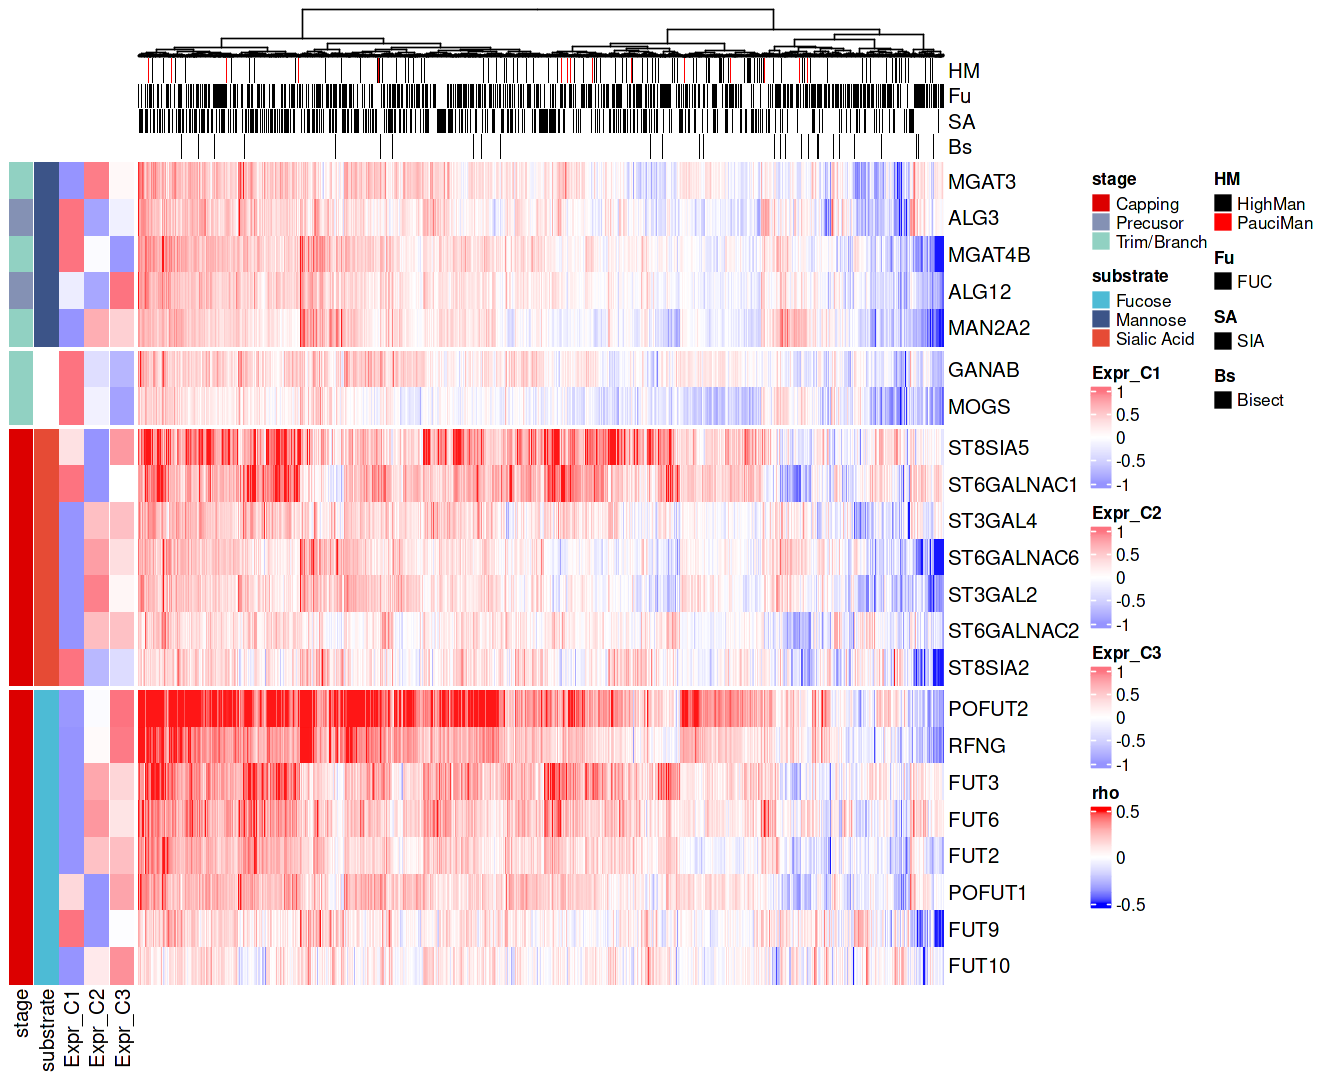

In [373]:

make.custom(11,9)
ha_left_data = cbind(rowData[rownames(mat1.s),],gt_rna_data[rownames(mat1.s),])
# ha_top_data = cbind(colDataGly[colnames(mat1.s),],gid_data[colnames(mat1.s),])
# ha_top_data = ha_top_data[,c("SA","C1",'C2','C3')]
ha_top_data = colDataGly[colnames(mat1.s),]

ha.left = HeatmapAnnotation(df = ha_left_data, which = 'row', col = COL_HM,na_col='white')
ha.top = HeatmapAnnotation(df = ha_top_data ,which = 'column',col=COL_HM,na_col='white')

hm1.s = Heatmap(mat1.s, name = 'rho'
                 , column_names_gp = gpar(fontsize=8)
                 , cluster_columns = TRUE
                  , cluster_rows = TRUE
#                  , column_title = paste0(nrow(mat),' ',vname %>% str_sub(1,-2),"s") %>% str_replace(fixed('ss'),'s')
                 , row_title = NULL
                 , rect_gp = gpar(col = "white", lwd=0.05)
                 , col = COL_HEATMAP_05_F
                 , top_annotation = ha.top
                 , left_annotation = ha.left
                 , cluster_column_slices = FALSE
                 , clustering_method_columns = 'ward.D2'
                 , clustering_method_rows = 'ward.D2'
                 , row_split = rowData[rownames(mat1.s),]$substrate
                 , column_split = NULL #colDataGly[colnames(mat2),]$SA
                 , show_column_names = FALSE
                 , show_row_names = TRUE, show_row_dend = FALSE)
hm1.s


In [242]:
sel.mrna.genes = ha_left_data %>% 
    filter(substrate == 'Sialic Acid') %>% 
    rownames(.)
sel.mrna.genes

[1] "ST8SIA2"    "ST8SIA5"    "ST6GALNAC2" "ST3GAL4"    "ST6GALNAC6"
[6] "ST6GALNAC1" "ST3GAL2"

### fig 3E

In [304]:
ha_top_data_sa = ha_top_data %>% dplyr::select('SA')
ha_top_data_sa

,SA
,<fct>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",NA
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",NA
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",NA
⋮,⋮
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",NA
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",NA
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",NA


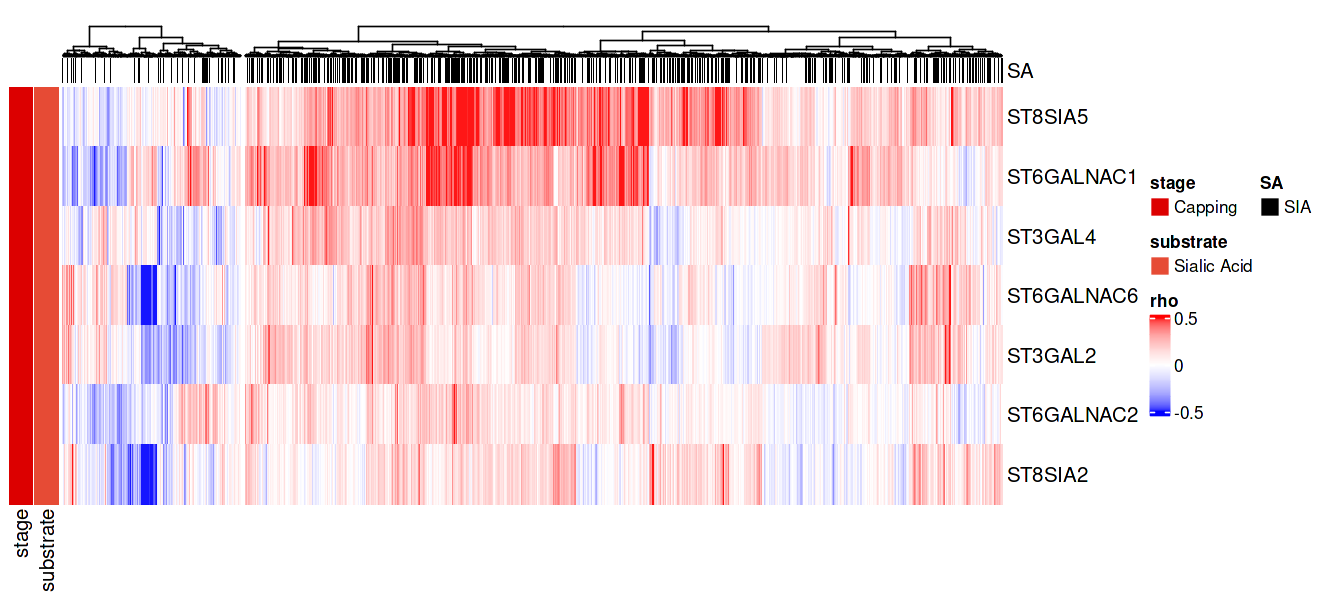

In [386]:
## select to plot SIA related mRNA - Gly rho

make.custom(11,5)

sel.ha_left_data = ha_left_data[sel.mrna.genes,c('stage','substrate')]
sel.mat1.s = mat1.s[sel.mrna.genes, ]

ha.left = HeatmapAnnotation(df = sel.ha_left_data, which = 'row', col = COL_HM,na_col='white')
ha.top = HeatmapAnnotation(df = ha_top_data_sa ,which = 'column',col=COL_HM, na_col='white')

hm1.s.sel = Heatmap(sel.mat1.s
                , name = 'rho'
                 , column_names_gp = gpar(fontsize=8)
                 , cluster_columns = TRUE
                  , cluster_rows = TRUE
#                  , column_title = paste0(nrow(mat),' ',vname %>% str_sub(1,-2),"s") %>% str_replace(fixed('ss'),'s')
                 , row_title = NULL
                 , rect_gp = gpar(col = "white", lwd=0.05)
                 , col = COL_HEATMAP_05_F
                 , top_annotation = ha.top
                 , left_annotation = ha.left
                 , cluster_column_slices = FALSE
                 , clustering_method_columns = 'ward.D2'
                 , clustering_method_rows = 'ward.D2'
                 , row_split = rowData[rownames(sel.mat1.s),]$substrate
                 , column_split = 2 #colDataGly[colnames(mat2),]$SA
                 , column_title = NULL
                 , show_column_names = FALSE
                 , show_row_names = TRUE
                 , show_row_dend = FALSE)
hm1.s.sel


In [387]:
hm1.s.sel %>% ysave('fig.3E.rho_SIA_heatmap',outputdir = OUTPUTROOT)
sel.mat1.s %>% as.data.frame %>% ysave('fig.3E.rho_SIA_heatmap',outputdir = OUTPUTROOT)

[1] "[ 2026-08-09 02:55:56 ]  write 1 pdf at report_c3/fig.3E.rho_SIA_heatmap.pdf"
[1] "[ 2026-08-09 02:55:56 ]  write 1 xlsx at report_c3/fig.3E.rho_SIA_heatmap.xlsx"


In [388]:
ha_top_data %>% ysave('fig.3E.rho_SIA_heatmap.top_anno', outputdir = OUTPUTROOT)

[1] "[ 2026-08-09 02:55:56 ]  write 1 xlsx at report_c3/fig.3E.rho_SIA_heatmap.top_anno.xlsx"


### fig S5H

In [409]:
# 1. Compute stats (grouped by symbol, comparing SA levels)
stat.test <- df.r %>%
  filter(symbol %in% sel.mrna.genes) %>%
  group_by(symbol) %>%
  rstatix::wilcox_test(rho ~ SA) %>%
  rstatix::adjust_pvalue(method = "holm") %>%
  rstatix::add_significance("p.adj") %>%
  rstatix::add_xy_position(x = "symbol", dodge = 0.8) %>%  # dodge must match boxplot width
  mutate(p.adj.fmt = rstatix::p_format(p.adj, accuracy = 0.0001, add.p = FALSE))
stat.test


symbol,.y.,group1,group2,n1,n2,statistic,p,p.adj,p.adj.signif,y.position,groups,x,xmin,xmax,p.adj.fmt
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<named list>,<dbl>,<dbl>,<dbl>,<chr>
ST3GAL2,rho,Others,SA,1059,728,359072.0,1.38e-02,1.380e-02,*,0.63252,"Others, SA",1,0.8,1.2,0.014
ST3GAL4,rho,Others,SA,1059,728,304240.5,3.47e-14,1.388e-13,****,0.53252,"Others, SA",2,1.8,2.2,<0.0001
ST6GALNAC1,rho,Others,SA,1059,728,332765.0,8.74e-07,1.748e-06,****,0.78452,"Others, SA",3,2.8,3.2,<0.0001
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ST6GALNAC6,rho,Others,SA,1059,728,327528.0,6.42e-08,1.926e-07,****,0.79352,"Others, SA",5,4.8,5.2,<0.0001
ST8SIA2,rho,Others,SA,1059,728,288060.0,9.98e-20,6.986e-19,****,0.63852,"Others, SA",6,5.8,6.2,<0.0001
ST8SIA5,rho,Others,SA,1059,728,297572.5,2.37e-16,1.422e-15,****,0.75352,"Others, SA",7,6.8,7.2,<0.0001


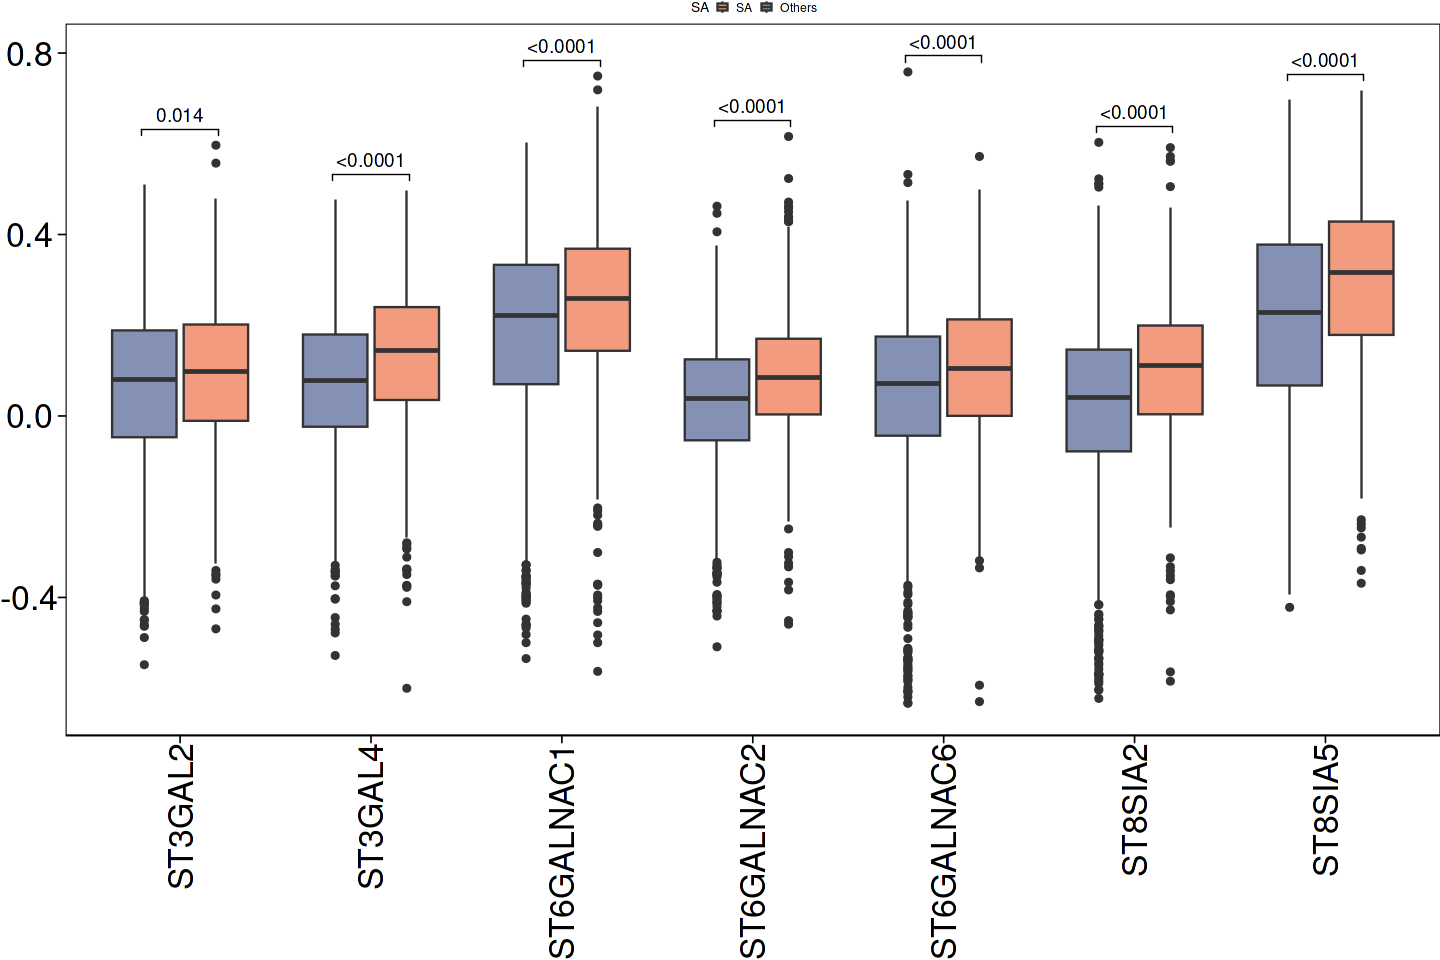

In [410]:
make.custom(12,8)
# 2. Build the plot
gg.rna = df.r %>% 
    filter(symbol %in% !!sel.mrna.genes) %>%
    ggplot(aes(x = symbol, y = rho,fill=SA))+
    geom_boxplot()+
    theme_pc() +
    scale_fill_manual(breaks = names(COL_SIA), values = COL_SIA) +
    ggpubr::stat_pvalue_manual(
        stat.test,
        label       = "p.adj.fmt",   # or "p.adj" for numeric values
        tip.length  = 0.01,
        hide.ns     = TRUE,             # drop non-significant brackets
        inherit.aes = FALSE 
        ) +
    theme(axis.text.x=element_text(angle = 90,hjust = 1))
gg.rna

In [411]:
gg.rna %>% ysave('fig.S5H.DE.ST.enzymes.boxplot',outputdir = OUTPUTROOT)

list(statistics =stat.test, raw_data = df.r %>% filter(symbol %in% !!sel.mrna.genes)) %>% ysave('fig.S5H.data.DE.ST.enzymes.boxplot',outputdir = OUTPUTROOT)

[1] "[ 2026-08-09 03:08:49 ]  write 1 pdf at report_c3/fig.S5H.DE.ST.enzymes.boxplot.pdf"
[1] "[ 2026-08-09 03:08:49 ]  write 1 xlsx at report_c3/fig.S5H.data.DE.ST.enzymes.boxplot.xlsx"


## fig 3F

### calc DE

In [51]:
grp_new = db.importing('wes_glx',outputdir = 'export_c3/')  %>%
    dplyr::rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification) %>% 
    dplyr::filter(Group!='pCR')
grp_new

[1] "[ 2026-08-24 06:18:38 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [52]:
# also in Section 'Gen matp, matr, matg' of this notebook
## load matp, matr, matg
load('export_c3/fig3_4grps_mat_prt_rna_gly.Rdata')

In [70]:
# calc dep, deg
# 

DE = list()

for (cluster in c('C1','C2','C3')){
    colData = grp_new %>% mutate(Group = ifelse(Group==!!cluster,cluster,'Others')) 
    cat('  Running',cluster,'\n')
    omic_names = c(Glycosylation='matg')
    for (name in names(omic_names)){
        mat = get(omic_names[name], envir = .GlobalEnv)
        mat = mat[,colData$tsb]
        x = mat %>% apply(1, sd)
        mat = mat[x != 0,]

        deg = ydo_numeric_DEG_limma(numeric.sorted = mat, 
                                    colData.sorted = colData, 
                                    col.id = 'tsb', 
                                    col.group = 'Group', 
                                    level_order = c('Others',cluster))
        tag = paste(name, cluster,sep='_')
#         deg = deg %>% rename(Delta_IonStrength=log2FoldChange, abs_Delta_IonS=abs_log2FC, Delta_Ins=FC_Ins)
        deg = deg %>% rename(Delta_IonStrength=DeltaValue, abs_Delta_IonS=abs_DeltaValue)
        deg$log2FC = log2(deg[[paste0("mean_",cluster)]] / deg$mean_Others)
        deg = deg %>% mutate(abs_log2FC = abs(log2FC))
            
        DE[[tag]] = deg
    }
}

  Running C1 
-------------------------------------------------------------
Comparing >  unpaired  <  C1 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
  Running C2 
-------------------------------------------------------------
Comparing >  unpaired  <  C2 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
  Running C3 
-------------------------------------------------------------
Comparing >  unpaired  <  C3 - Others , REF_GROUP =  Others 
-------------------------------------------------------------


In [74]:
DE$Glycosylation_C2 %>% arrange(desc(Delta_IonStrength))

symbol,Delta_IonStrength,baseMean,t,pvalue,padj,B,stat,abs_Delta_IonS,Delta_Ins,median_C2,mean_C2,median_Others,mean_Others,log2FC,abs_log2FC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MFAP4,15.84754,109.50343,3.466154,8.719760e-04,0.0017645498,-1.0702592,3.466154,15.84754,TRUE,118.1103,120.8231,104.34009,104.97557,0.2028428,0.2028428
A1AT,15.48286,106.14370,4.131960,9.165115e-05,0.0004381215,1.0360700,4.131960,15.48286,TRUE,112.6698,117.2029,101.11963,101.72003,0.2044043,0.2044043
PGS2,13.34871,96.16373,3.956749,1.694522e-04,0.0005942500,0.4580123,3.956749,13.34871,TRUE,102.5622,105.6985,93.55087,92.34981,0.1947743,0.1947743
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ARLY,-0.01947755,1.1067516,-0.2532467,0.8007617,0.8070422,-6.581251,-0.2532467,0.01947755,FALSE,1.0446428,1.0928390,1.0275630,1.1123166,-0.02548654,0.02548654
DPP4,-0.20091980,0.9217711,-1.1864702,0.2391346,0.2478129,-5.919154,-1.1864702,0.20091980,FALSE,0.8190577,0.7782569,0.8292035,0.9791767,-0.33132276,0.33132276
ZN677,-0.43661060,4.8911297,-0.6556312,0.5140425,0.5242417,-6.399857,-0.6556312,0.43661060,FALSE,4.1946492,4.5792650,3.8615269,5.0158756,-0.13138551,0.13138551


In [25]:
c2 = matg['MFAP4',grp_new %>% filter(Group=='C2') %>% pull(tsb)] %>% apply(1, mean)
o = matg['MFAP4',grp_new %>% filter(Group!='C2') %>%pull(tsb)] %>% apply(1, mean)
c2 - o

MFAP4 
15.84754

In [26]:
DE$Glycosylation_C2 %>% filter(symbol=='MFAP4')

symbol,Delta_IonStrength,baseMean,t,pvalue,padj,B,stat,abs_Delta_IonS,Delta_Ins,median_C2,mean_C2,median_Others,mean_Others,log2FC,abs_log2FC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MFAP4,15.84754,109.5034,3.466154,0.000871976,0.00176455,-1.070259,3.466154,15.84754,TRUE,118.1103,120.8231,104.3401,104.9756,0.2028428,0.2028428


In [27]:
saveRDS(DE,'export_c3/fig3_de_glycoprotein.RDS')

In [44]:
DE %>% ysave('fig.3F.glyco_protein_DE', outputdir = 'report_c3/')

[1] "[ 2026-08-24 06:15:00 ]  write 1 xlsx at report_c3/fig.3F.glyco_protein_DE.xlsx"


In [29]:
deg

symbol,Delta_IonStrength,baseMean,t,pvalue,padj,B,stat,abs_Delta_IonS,Delta_Ins,median_C3,mean_C3,median_Others,mean_Others,log2FC,abs_log2FC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
YD021,-0.6889923,3.930741,-3.976352,0.0001583154,0.04068706,0.7461191,-3.976352,0.6889923,FALSE,3.395877,3.545979,4.119417,4.234971,-0.2561682,0.2561682
MAGB6,-0.1826596,1.912246,-3.168397,0.0022089073,0.28384459,-1.4755024,-3.168397,0.1826596,FALSE,1.815145,1.810241,1.975298,1.992901,-0.1386880,0.1386880
ULK1,-0.6674347,3.802716,-2.917354,0.0046404164,0.39752901,-2.0912510,-2.917354,0.6674347,FALSE,3.339348,3.429993,3.788494,4.097428,-0.2565129,0.2565129
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
CE162,0.0002978354,0.9466225,0.006909513,0.9945052,0.997569,-5.762994,0.006909513,0.0002978354,TRUE,0.8988118,0.9467888,0.9408606,0.946491,0.0004539061,0.0004539061
ARLY,-0.0004049184,1.1067516,-0.005781685,0.9954021,0.997569,-5.763001,-0.005781685,0.0004049184,FALSE,1.0356765,1.1065255,1.0310388,1.106930,-0.0005278386,0.0005278386
COEA1,-0.0029470303,25.9281533,-0.003056801,0.9975690,0.997569,-5.763012,-0.003056801,0.0029470303,FALSE,25.0166207,25.9265075,25.9384961,25.929455,-0.0001639798,0.0001639798


### plot

In [5]:
DE = readRDS('export_c3/fig3_de_glycoprotein.RDS')
DE %>%names

[1] "Glycosylation_C1" "Glycosylation_C2" "Glycosylation_C3"

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Warning message:
“Removed 1 rows containing missing values (`geom_point()`).”
Warning message:
“Removed 244 rows containing missing values (`geom_text_repel()`).”
Warning message:
“Removed 1 rows containing missing values (`geom_vline()`).”


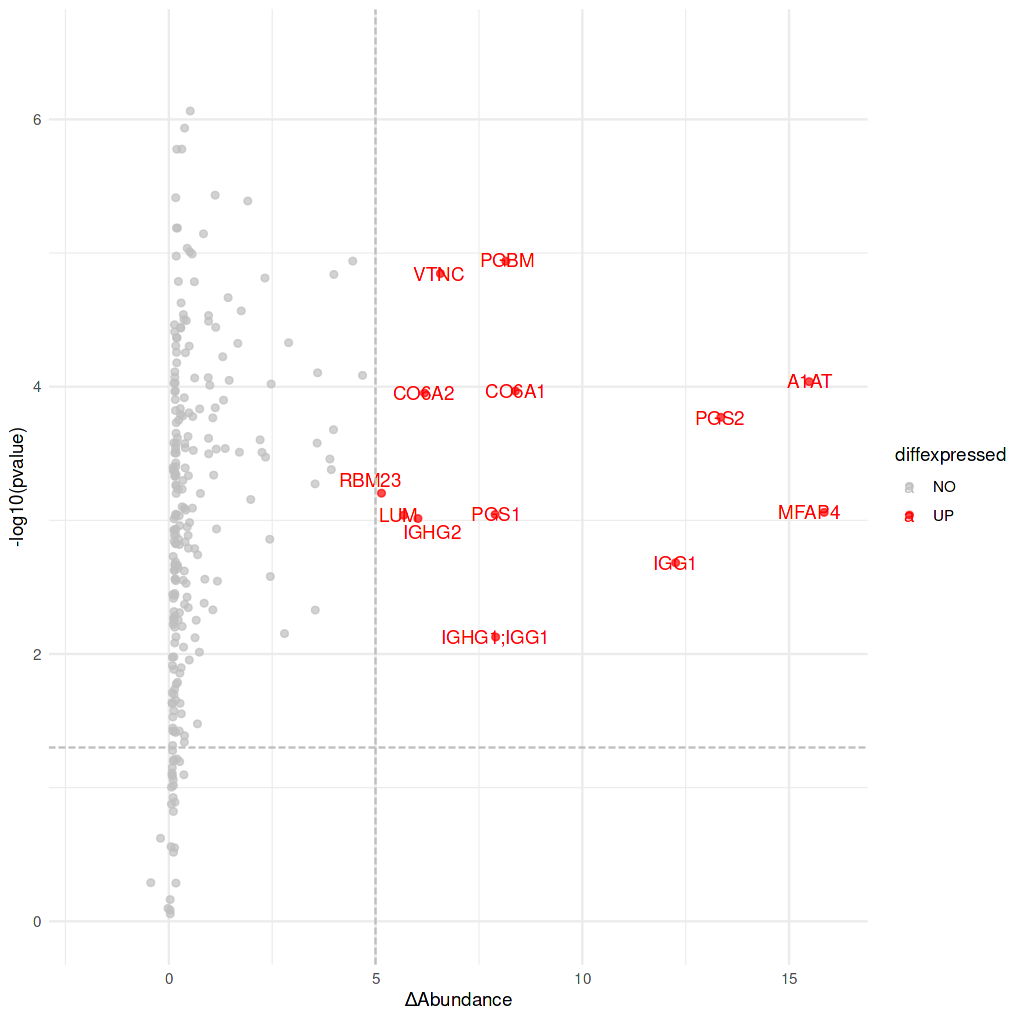

In [15]:
make.custom(8.5,8.5)
gg2 = yplot_volcano_using_de(DE$Glycosylation_C2 %>% 
                                 column_to_rownames('symbol') %>% 
                                 mutate(log2FoldChange = Delta_IonStrength)
                             , add_label = TRUE
                             , value_var = 'pvalue'
                             , logFC_threshold = c(-5,5))

g3f = gg2$gg + 
    scale_x_continuous(limits = c(-2,16)) +
    scale_y_continuous(limits = c(0,6.5)) +
    scale_color_manual(values = c("blue", "gray", "red"),breaks = c('DOWN','NO','UP')) +
    xlab('ΔAbundance')
g3f


In [20]:
 DE$Glycosylation_C2

symbol,Delta_IonStrength,baseMean,t,pvalue,padj,B,stat,abs_Delta_IonS,Delta_Ins,median_C2,mean_C2,median_Others,mean_Others,log2FC,abs_log2FC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SAP,0.4472407,1.904159,5.620439,3.005736e-07,7.724742e-05,6.486192,5.620439,0.4472407,TRUE,2.122407,2.223617,1.780872,1.776376,0.3239711,0.3239711
GYS2,0.5171452,2.862694,5.359313,8.654826e-07,8.595727e-05,5.471950,5.359313,0.5171452,TRUE,3.230193,3.232083,2.689391,2.714938,0.2515451,0.2515451
AKAP3,0.3815512,1.880844,5.285811,1.161494e-06,8.595727e-05,5.190217,5.285811,0.3815512,TRUE,2.074400,2.153381,1.780877,1.771829,0.2813636,0.2813636
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ARLY,-0.01947755,1.106752,-0.2532467,0.8007617,0.8070422,-6.581251,-0.2532467,0.01947755,FALSE,1.044643,1.092839,1.0275630,1.1123166,-0.02548654,0.02548654
IGA2,0.03349633,1.029834,0.2227354,0.8243393,0.8275594,-6.588472,0.2227354,0.03349633,TRUE,1.020459,1.053760,0.9631582,1.0202637,0.04660428,0.04660428
SEMG2,0.03380186,1.006258,0.1526873,0.8790498,0.8790498,-6.601552,0.1526873,0.03380186,TRUE,1.046702,1.030402,0.9168096,0.9966005,0.04812060,0.04812060


In [19]:
for (i in DE$Glycosylation_C2$symbol){
    cat(i,'\n')
}

SAP 
GYS2 
AKAP3 
CO6 
AA3R 
THRB 
WDTC1 
LIN54 
PRLD1 
VWF 
KLKB1 
CATD 
IGHM 
ITIH1 
MYH11 
FIBG 
PGBM 
VTNC 
LAMA4 
A1AG2 
HXC10 
IGJ 
COCA1 
KNL1 
CLUS 
ITA3 
OLFL3 
CO9 
AACT 
CO4A 
ERCC5 
PEDF 
RBM19 
HG2A 
DYH11 
CTR9 
K0513 
PRELP 
A2MG 
CAC1B 
CBG 
HPT;HPTR 
PRDX2 
CERU 
ITIH5 
SCML2 
CO6A3 
A1AG1 
TR10D 
ENPL 
CD83 
MIME 
A1AT 
FBN1 
ITPI2 
LAMC1 
LAMB2 
5HT3B 
CO6A1 
MUC2 
CO6A2 
PTPRQ 
CBPD 
APOH 
CO3 
TR49D 
RYR1 
COMA1 
TASO2 
ZN840 
NISCH 
EPS8 
PGS2 
POSTN 
PLRG1 
CA2D1 
HPT 
SENP6 
CO4A;CO4B 
S45A2 
ITIH2 
SODE 
FOLH1 
ABCAD 
ANT3 
ITIH4 
GBF1 
ZN131 
FETUA 
LAMA5 
DC8L2 
STT3B 
PCYOX 
A1AG2;A1AG1 
MAGI3 
SRPK3;SRPK2;SRPK1 
IC1 
EMIL1 
IGHG4 
SE1L1 
TMOD1 
APOF 
LYN 
CO3A1 
SCRB2 
BCL9 
APMAP 
PTPRH 
FIBB 
SON 
PTPRF 
DAAF1 
FA12 
AOC3 
FMOD 
PCDB1 
VANG1 
FL2D 
RBM23 
NRX2A 
HJURP 
IGHG3 
USP9X 
ASPN 
FIZ1 
KNG1 
MFAP4 
TBCD5 
CHP1 
PGS1 
LUM 
ELP5 
HNRL1 
IGHG2 
MCCA 
NID2 
MRT4 
FGL2 
PIN1 
SFRP4 
BMPR2 
ITA6 
ALDOB 
AMPN 
CD47 
LAMP1 
PNKD 
KI26B 
GGT5 
ACE 
ATOH8 

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Warning message:
“Removed 116 rows containing missing values (`geom_text_repel()`).”
Warning message:
“ggrepel: 135 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


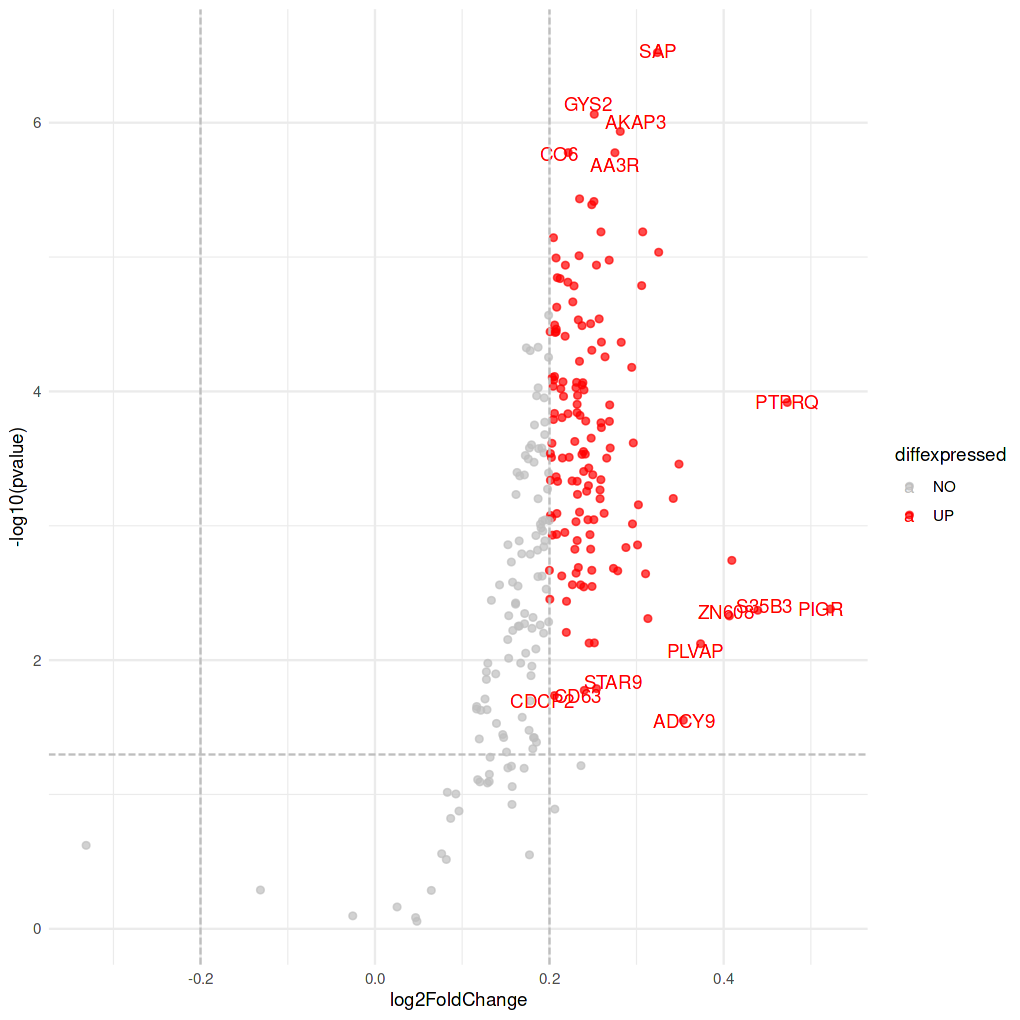

In [36]:
make.custom(8.5,8.5)
gg32 = yplot_volcano_using_de(DE$Glycosylation_C2 %>% 
                                 column_to_rownames('symbol') %>% 
                                 mutate(log2FoldChange = log2FC)
                             , add_label = TRUE
                             , value_var = 'pvalue'
                             , logFC_threshold = c(-0.2,0.2))

g3f2 = gg32$gg + 
#     scale_x_continuous(limits = c(-2,16)) +
#     scale_y_continuous(limits = c(0,6.5)) +
    scale_color_manual(values = c("blue", "gray", "red"),breaks = c('DOWN','NO','UP'))
g3f2

In [47]:
gg32$de['MFAP4',]

,Delta_IonStrength,baseMean,t,pvalue,padj,B,stat,abs_Delta_IonS,Delta_Ins,median_C2,mean_C2,median_Others,mean_Others,log2FC,abs_log2FC,log2FoldChange,diffexpressed,y,delabel,gene_symbol
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<chr>,<chr>
MFAP4,15.84754,109.5034,3.466154,0.000871976,0.00176455,-1.070259,3.466154,15.84754,TRUE,118.1103,120.8231,104.3401,104.9756,0.2028428,0.2028428,0.2028428,UP,3.059495,MFAP4,MFAP4


In [428]:
DE %>% names

[1] "Glycosylation_C1" "Glycosylation_C2" "Glycosylation_C3"

In [49]:
g3f %>% ysave('fig.3F.DE_Gly_volcano',outputdir = OUTPUTROOT)
# DE$Glycosylation_C2 %>% ysave('fig.3F.DE_Gly_volcano',outputdir = OUTPUTROOT)
g3f2 %>% ysave('fig.3F.2nd.DE_Gly_volcano_log2',outputdir = OUTPUTROOT)

Warning message:
“Removed 27 rows containing missing values (`geom_text_repel()`).”
Warning message:
“ggrepel: 219 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


[1] "[ 2026-08-24 06:17:42 ]  write 1 pdf at report_c3/fig.3F.DE_Gly_volcano.pdf"


Warning message:
“Removed 116 rows containing missing values (`geom_text_repel()`).”
Warning message:
“ggrepel: 127 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


[1] "[ 2026-08-24 06:17:43 ]  write 1 pdf at report_c3/fig.3F.2nd.DE_Gly_volcano_log2.pdf"


## fig S5I

In [3]:
grp_new = db.importing('wes_glx',outputdir = 'export_c3/')  %>%
    dplyr::rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification) %>% 
    dplyr::filter(Group!='pCR')
grp_new

[1] "[ 2026-09-12 14:12:32 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [9]:
sig.c2 = DE$Glycosylation_C2 %>% dplyr::filter(padj<0.05, abs_Delta_IonS>0.2) %>% arrange(desc(abs_Delta_IonS))
sig.c2

symbol,Delta_IonStrength,baseMean,t,pvalue,padj,B,stat,abs_Delta_IonS,Delta_Ins,median_C2,mean_C2,median_Others,mean_Others,log2FC,abs_log2FC
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MFAP4,15.84754,109.50343,3.466154,8.719760e-04,0.0017645498,-1.0702592,3.466154,15.84754,TRUE,118.1103,120.8231,104.34009,104.97557,0.2028428,0.2028428
A1AT,15.48286,106.14370,4.131960,9.165115e-05,0.0004381215,1.0360700,4.131960,15.48286,TRUE,112.6698,117.2029,101.11963,101.72003,0.2044043,0.2044043
PGS2,13.34871,96.16373,3.956749,1.694522e-04,0.0005942500,0.4580123,3.956749,13.34871,TRUE,102.5622,105.6985,93.55087,92.34981,0.1947743,0.1947743
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
RN213,0.2105167,1.0489626,3.174753,2.166646e-03,0.0034585586,-1.9088701,3.174753,0.2105167,TRUE,1.141186,1.199332,0.9819034,0.9888149,0.2784583,0.2784583
PRLD1,0.2091144,0.9411354,4.846754,6.494490e-06,0.0001670531,3.5458726,4.846754,0.2091144,TRUE,1.047250,1.090503,0.8874549,0.8813884,0.3071437,0.3071437
S45A2,0.2070868,0.9674353,3.853407,2.417842e-04,0.0007721071,0.1247103,3.853407,0.2070868,TRUE,1.080560,1.115354,0.8927769,0.9082677,0.2963128,0.2963128


In [10]:
sig.c2 %>% ydumpto('fig3_c2_sig_de_glycoprotein.dfx',outputdir = INPUTROOT)

[1] "[ 2026-09-12 14:15:49 ]  write 1 < dfx > at export_c3/fig3_c2_sig_de_glycoprotein.dfx"


[1] "export_c3/fig3_c2_sig_de_glycoprotein.dfx"

In [20]:
# also in Section 'Gen matp, matr, matg' of this notebook
## load matp, matr, matg
load('export_c3/fig3_4grps_mat_prt_rna_gly.Rdata')

In [21]:
xsigc2 = sig.c2$symbol %>% intersect(rownames(matp)) %>% intersect(rownames(matg))
xsigc2

[1] "MFAP4" "PGS1"  "IGHG2" "LUM"   "LAMA4" "IGHG4" "AOC3"  "PRELP" "LAMC1"
[10] "LAMP1" "IGHG3" "APOH"  "AMBP"  "PIN1"  "LAMA5" "LRP1"  "POSTN" "LAMB2"
[19] "ITIH2" "VWA1"  "PIGR"  "KLKB1" "RYR1"  "BCAM"  "MTUS1" "PLVAP" "STT3B"
[28] "EPS8"  "ITIH1" "IGHM"  "NID2"  "SON"   "SUN2"  "CD47"  "FGL2"  "KNG1" 
[37] "PRDX2" "LYN"   "GGT5"  "ITIH4" "STT3A" "ASPN"  "NISCH" "USP9X" "RBM19"
[46] "UACA"  "TAF5"  "ELP5"  "PLRG1" "PNKD"  "PRDX1"

In [22]:
sig.matp = matp[xsigc2,grp_new$tsb] %>% rownames_to_column("symbol") %>% 
    pivot_longer(!symbol, names_to = 'tsb', values_to = 'abundant') %>%
    mutate(omics='protein')

sig.matg = matg[xsigc2,grp_new$tsb] %>% rownames_to_column("symbol") %>% 
    pivot_longer(!symbol, names_to = 'tsb', values_to = 'abundant') %>%
    mutate(omics='glyco')
sig.mat = rbind(sig.matp, sig.matg) %>% left_join(grp_new)
sig.mat

Joining with `by = join_by(tsb)`


symbol,tsb,abundant,omics,Group
<chr>,<chr>,<dbl>,<chr>,<chr>
MFAP4,P72,-1.0776294,protein,C1
MFAP4,P10,-0.1480449,protein,C1
MFAP4,P14,-1.1792305,protein,C1
⋮,⋮,⋮,⋮,⋮
PRDX1,P01,1.912223,glyco,C3
PRDX1,P21,1.838940,glyco,C3
PRDX1,P48,1.687674,glyco,C3


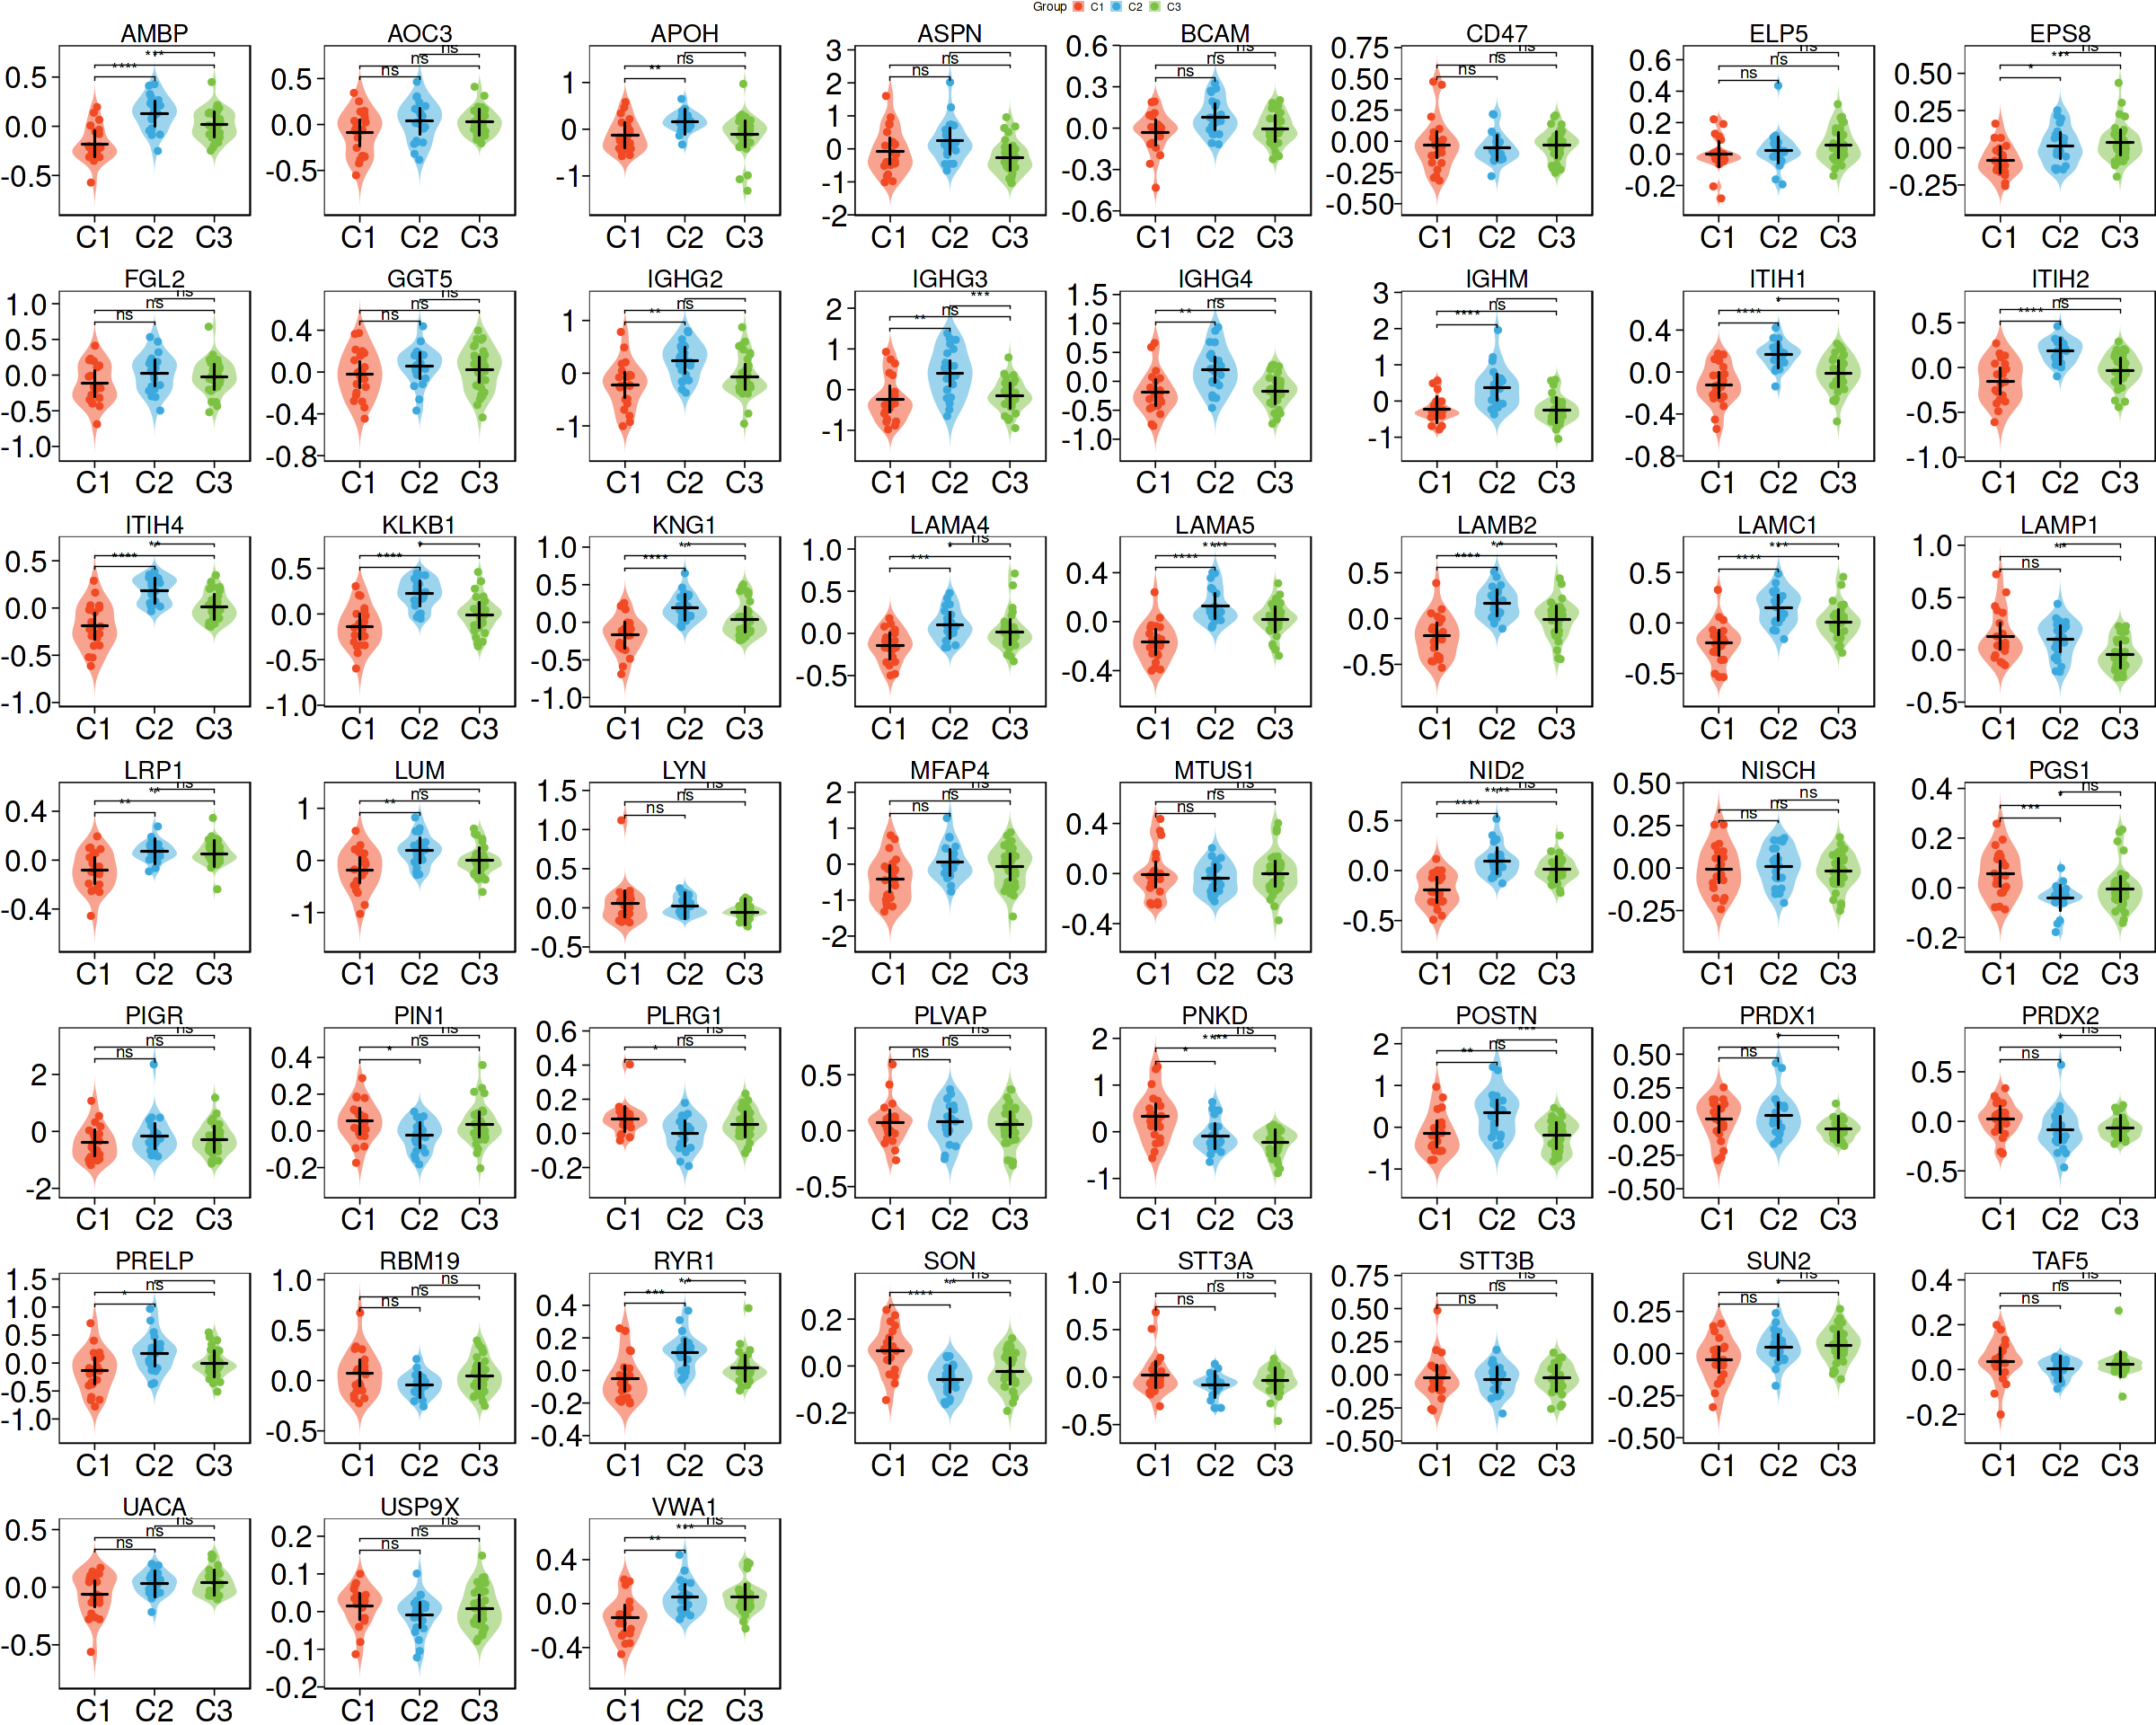

In [23]:
make.custom(20,16)
gg.rate.prt = sig.mat %>% dplyr::filter(omics=='protein') %>% 
    ggplot(aes(x = Group, y = abundant, fill = Group)) +
    geom_violin(alpha=0.5, color=NA, trim = FALSE, width=0.75, scale = 'width')+
    geom_point(aes(color=Group)
               ,show.legend = TRUE
#            ,size=0.2
#            ,alpha = 0.5
           ,position=position_jitterdodge(jitter.width = 0.2
                                          ,dodge.width = 0.75)
          ) +
    facet_wrap(~symbol, scales = 'free') +
    stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1, show.legend = FALSE) +
    scale_color_manual(values = COL_ANNO$Group, breaks = names(COL_ANNO$Group)) +
    scale_fill_manual(values = COL_ANNO$Group, breaks = names(COL_ANNO$Group))+
    theme_pc() +
    ggpubr::stat_pwc(aes(label = ypvalue_add_asterisks(after_stat(p.adj))), hide.ns = FALSE)

gg.rate.prt

In [24]:
gg.rate.prt %>% ysave('fig.S5I.prt_abundance.violin.selected',outputdir = OUTPUTROOT)

[1] "[ 2026-09-12 14:18:00 ]  write 1 pdf at report_c3/fig.S5I.prt_abundance.violin.selected.pdf"


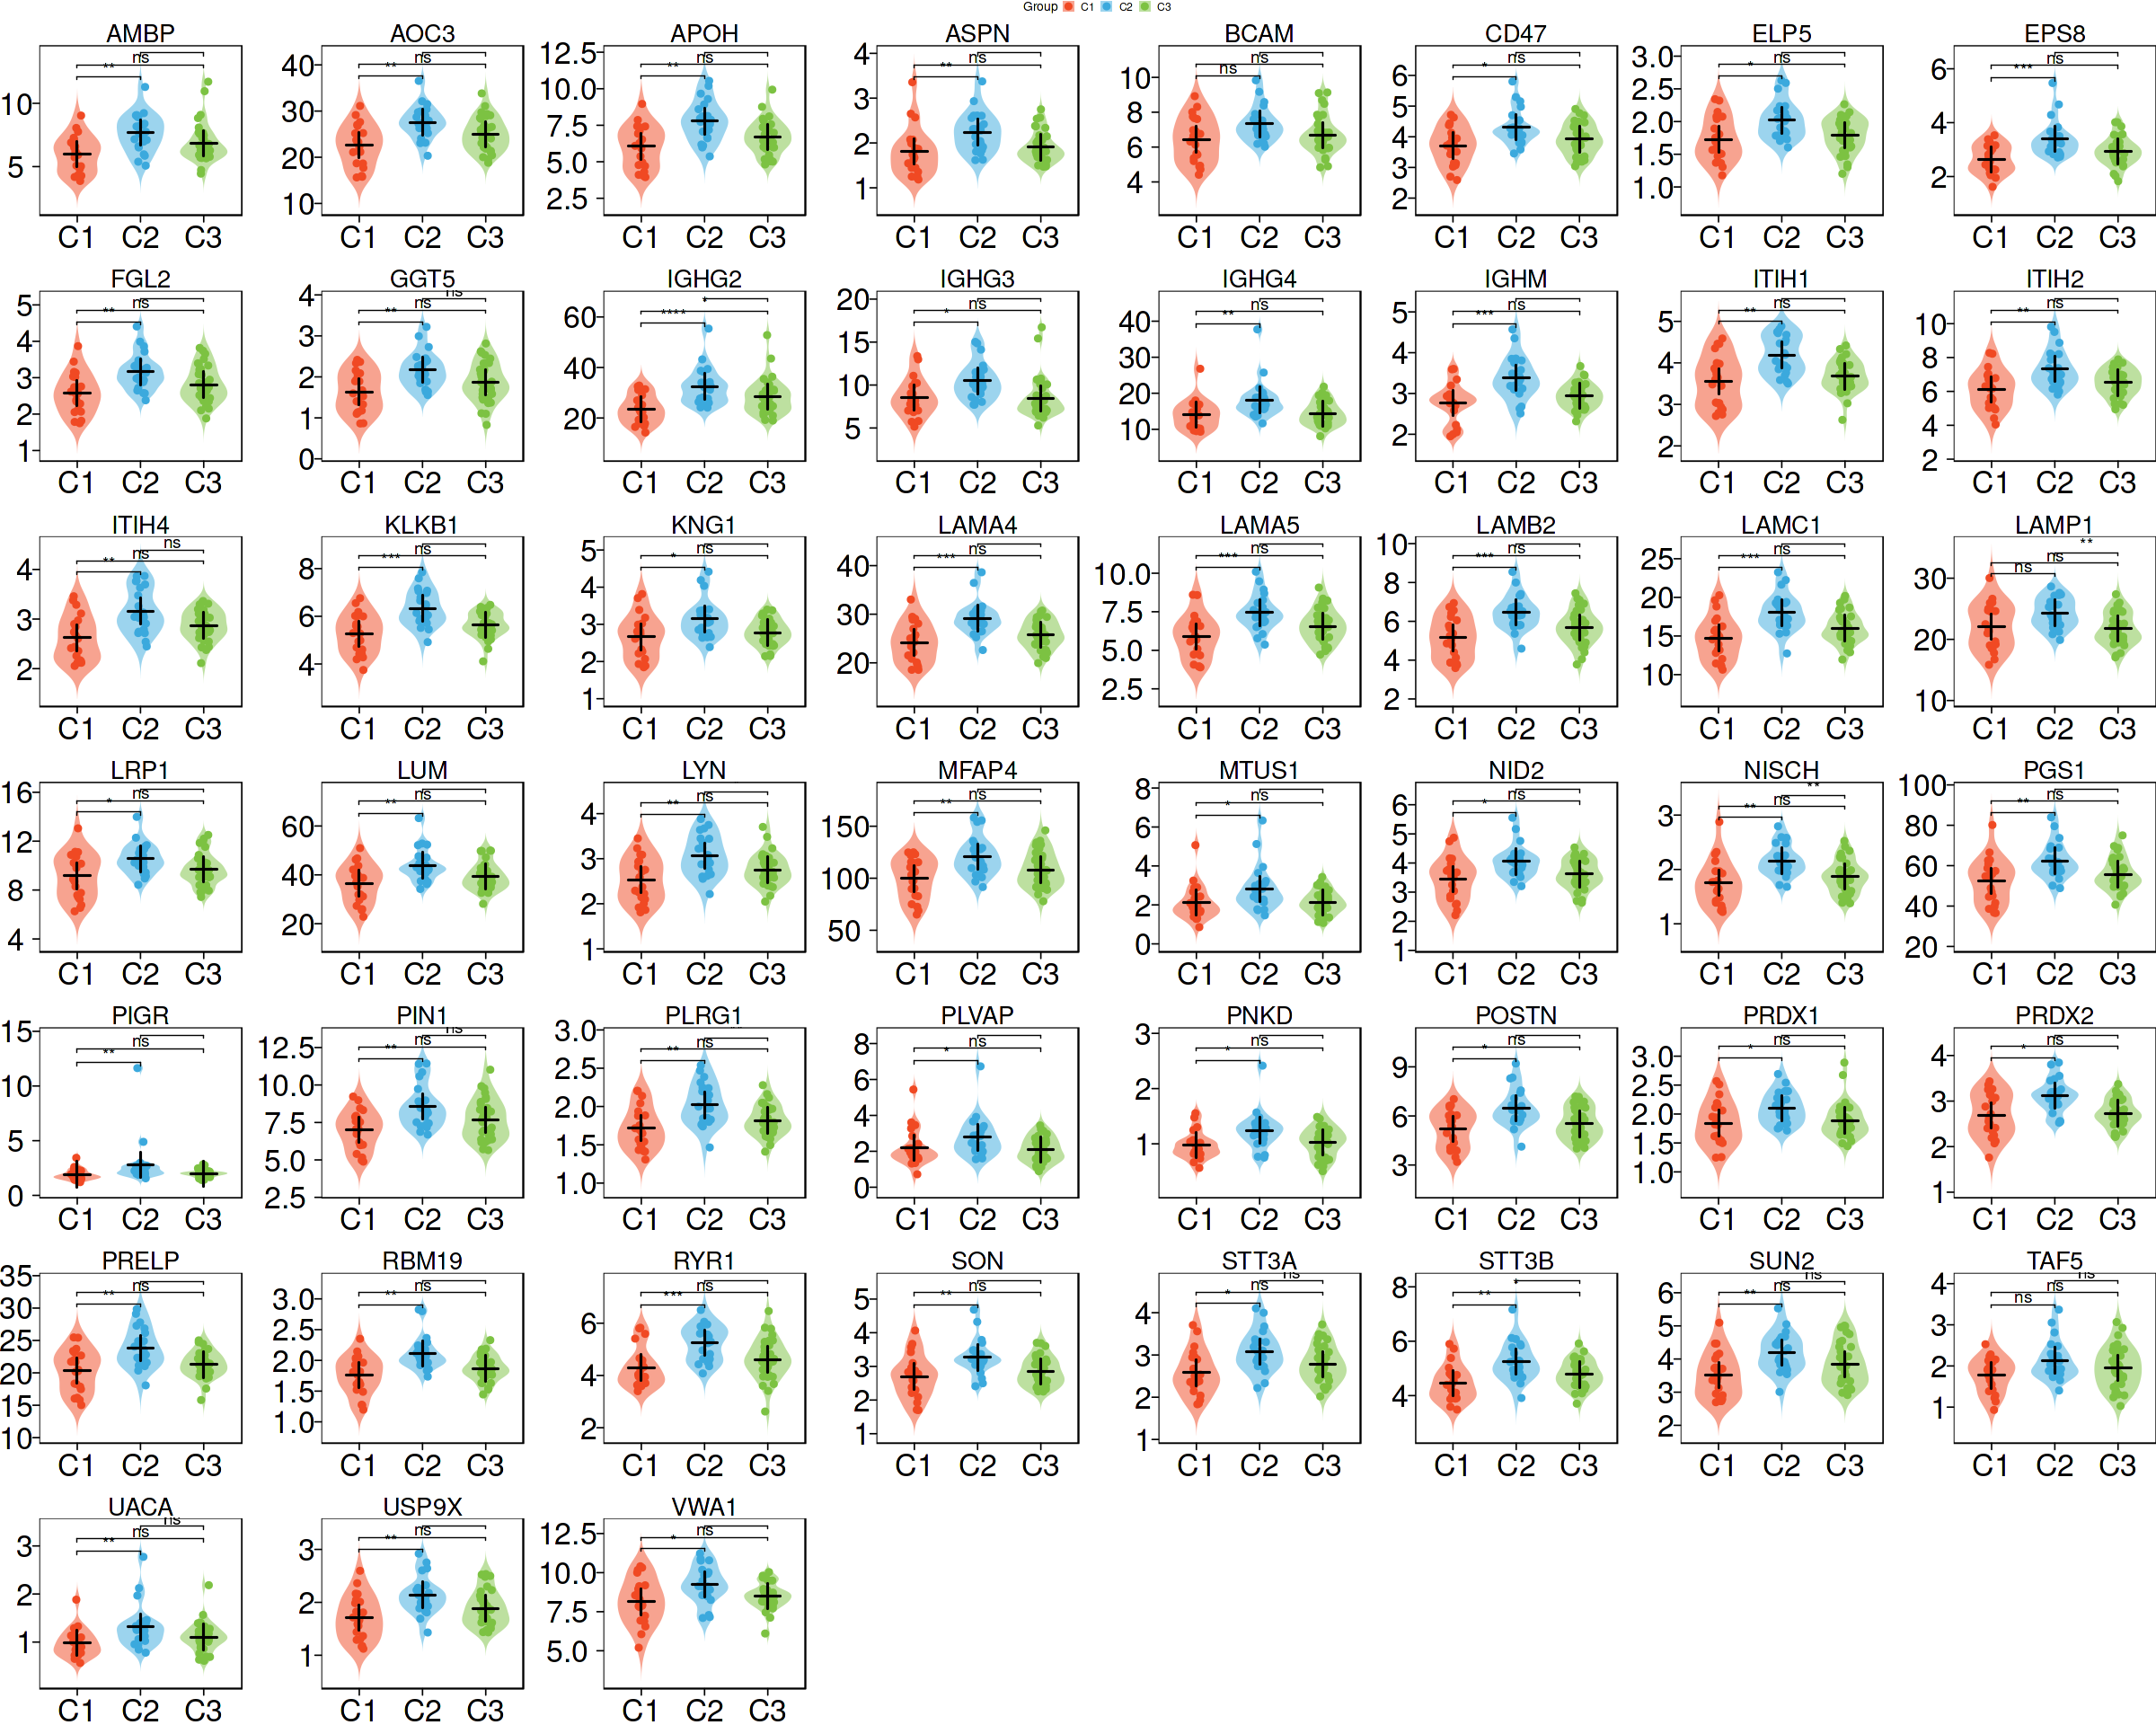

In [25]:
make.custom(20,16)
gg.rate.gly = sig.mat %>% dplyr::filter(omics=='glyco') %>% 
    ggplot(aes(x = Group, y = abundant, fill = Group)) +
    geom_violin(alpha=0.5, color=NA, trim = FALSE, width=0.75, scale = 'width')+
    geom_point(aes(color=Group)
               ,show.legend = TRUE
#            ,size=0.2
#            ,alpha = 0.5
           ,position=position_jitterdodge(jitter.width = 0.2
                                          ,dodge.width = 0.75)
          ) +
    facet_wrap(~symbol, scales = 'free') +
    stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1, show.legend = FALSE) +
    scale_color_manual(values = COL_ANNO$Group, breaks = names(COL_ANNO$Group)) +
    scale_fill_manual(values = COL_ANNO$Group, breaks = names(COL_ANNO$Group))+
    theme_pc() +
    ggpubr::stat_pwc(aes(label = ypvalue_add_asterisks(after_stat(p.adj))), hide.ns = FALSE)

gg.rate.gly


In [26]:
gg.rate.gly %>% ysave('fig.S5I.glyco_ios_stregth.violin.selected',outputdir = OUTPUTROOT)

[1] "[ 2026-09-12 14:18:24 ]  write 1 pdf at report_c3/fig.S5I.glyco_ios_stregth.violin.selected.pdf"


In [27]:
sig.mat

symbol,tsb,abundant,omics,Group
<chr>,<chr>,<dbl>,<chr>,<chr>
MFAP4,P72,-1.0776294,protein,C1
MFAP4,P10,-0.1480449,protein,C1
MFAP4,P14,-1.1792305,protein,C1
⋮,⋮,⋮,⋮,⋮
PRDX1,P01,1.912223,glyco,C3
PRDX1,P21,1.838940,glyco,C3
PRDX1,P48,1.687674,glyco,C3


In [33]:
sig.mat

symbol,tsb,abundant,omics,Group
<chr>,<chr>,<dbl>,<chr>,<chr>
MFAP4,P72,-1.0776294,protein,C1
MFAP4,P10,-0.1480449,protein,C1
MFAP4,P14,-1.1792305,protein,C1
⋮,⋮,⋮,⋮,⋮
PRDX1,P01,1.912223,glyco,C3
PRDX1,P21,1.838940,glyco,C3
PRDX1,P48,1.687674,glyco,C3


In [39]:
stat.sig.mat <- sig.mat %>%
#   filter(omics == "protein") %>%
  group_by(omics, symbol) %>%
  rstatix::pairwise_wilcox_test(
    abundant ~ Group,
    p.adjust.method = "holm"
  ) %>%
  ungroup() %>%
  rstatix::add_significance("p.adj") %>%
  mutate(
    label = ypvalue_add_asterisks(p.adj)
  )

stat.sig.mat

symbol,omics,.y.,group1,group2,n1,n2,statistic,p,p.adj,p.adj.signif,label
<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
AMBP,glyco,abundant,C1,C2,21,22,93,0.000551,0.002,**,**
AMBP,glyco,abundant,C1,C3,21,34,262,0.102000,0.102,ns,ns
AMBP,glyco,abundant,C2,C3,22,34,518,0.015000,0.030,*,*
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
VWA1,protein,abundant,C1,C2,21,22,97,0.000825,0.002000,**,**
VWA1,protein,abundant,C1,C3,21,34,143,0.000124,0.000372,***,***
VWA1,protein,abundant,C2,C3,22,34,360,0.822000,0.822000,ns,ns


In [41]:
pwc_results %>%filter(symbol=='MFAP4')

symbol,omics,.y.,group1,group2,n1,n2,statistic,p,p.adj,p.adj.signif,label
<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
MFAP4,glyco,abundant,C1,C2,21,22,110,0.003,0.008,**,**
MFAP4,glyco,abundant,C1,C3,21,34,281,0.193,0.193,ns,ns
MFAP4,glyco,abundant,C2,C3,22,34,517,0.016,0.032,*,*
MFAP4,protein,abundant,C1,C2,21,22,134,0.018,0.054,ns,ns
MFAP4,protein,abundant,C1,C3,21,34,237,0.038,0.075,ns,ns
MFAP4,protein,abundant,C2,C3,22,34,403,0.635,0.635,ns,ns


In [40]:
# stat.sig.mat =  ggpubr::compare_means(data = as.data.frame(sig.mat), abundant~Group, group.by = c('symbol','omics'))
# stat.sig.mat

In [42]:
list(raw_data=sig.mat, statistics=stat.sig.mat) %>% ysave('fig.S5I.glyco_prt_violin.selected.data',outputdir = OUTPUTROOT)


[1] "[ 2026-09-12 14:34:36 ]  write 1 xlsx at report_c3/fig.S5I.glyco_prt_violin.selected.data.xlsx"


## fig 3G
**Fig 3G — manually generated.** This panel was drawn manually with external tools; there is no plotting code in this repository. (bubble plot of pathway enrichment for glycoproteins upregulated in C2, input: `report_c3/fig.3F.glyco_protein_DE.xlsx`)

## fig 3H 3I 3J,  GSEA cor

### calc GSEA Correlation Data

In [432]:
glx = db.importing('glx_86',frm=INPUTROOT)
glx

[1] "[ 2026-08-24 00:45:02 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  export_c3"


tsb,Group,Response
<chr>,<chr>,<chr>
P72,C1,non.pCR
P10,C1,non.pCR
P14,C1,non.pCR
⋮,⋮,⋮
P78,pCR,pCR
P76,pCR,pCR
P79,pCR,pCR


In [433]:
grps = glx %>% filter(Response=='non.pCR') %>% 
    dplyr::select(tsb,Group)  
#     column_to_rownames("Protein_Cluster") 
#     unlist()
grps = split(grps$tsb, grps$Group)

grps

$C1
 [1] "P72" "P10" "P14" "P56" "P16" "P52" "P47" "P80" "P70" "P71" "P83" "P82"
[13] "P84" "P43" "P60" "P49" "P65" "P51" "P39" "P45" "P66"

$C2
 [1] "P34" "P05" "P29" "P69" "P53" "P28" "P86" "P85" "P06" "P42" "P18" "P57"
[13] "P63" "P17" "P62" "P41" "P25" "P27" "P46" "P11" "P20" "P30"

$C3
 [1] "P38" "P03" "P37" "P58" "P19" "P61" "P24" "P23" "P36" "P44" "P32" "P67"
[13] "P31" "P68" "P12" "P13" "P73" "P59" "P54" "P08" "P55" "P22" "P07" "P33"
[25] "P09" "P40" "P15" "P26" "P50" "P04" "P02" "P01" "P21" "P48"

In [434]:
tsb.pcr = glx %>% filter(Response=='pCR') %>% pull(tsb)
tsb.pcr

[1] "P77" "P35" "P81" "P74" "P75" "P64" "P78" "P76" "P79"

In [435]:
colData = glx %>% dplyr::filter(Response!='pCR') %>% dplyr::select(tsb, Group)
colData

tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P01,C3
P21,C3
P48,C3


In [436]:
hm = db.importing('export_by2_86_pCR_nonpCR/rna_ssGSEA_hm.dfx',row.names=1)
im = db.importing('export_by2_86_pCR_nonpCR/rna_ssGSEA_immune.dfx',row.names=1)
kegg = db.importing('export_by2_86_pCR_nonpCR/rna_ssGSEA_kegg.dfx',row.names=1) 



[1] "[ 2026-08-24 00:45:05 ]  read [ rna_ssGSEA_hm.dfx ] as ' rna_ssGSEA_hm ' from >  export_by2_86_pCR_nonpCR"
[1] "[ 2026-08-24 00:45:05 ]  read [ rna_ssGSEA_immune.dfx ] as ' rna_ssGSEA_immune ' from >  export_by2_86_pCR_nonpCR"
[1] "[ 2026-08-24 00:45:05 ]  read [ rna_ssGSEA_kegg.dfx ] as ' rna_ssGSEA_kegg ' from >  export_by2_86_pCR_nonpCR"


In [437]:
rna.ssgsea = list(hm,im,kegg) %>% purrr::reduce(rbind)
ssgsea = rna.ssgsea [,colData$tsb]
ssgsea

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HALLMARK_ADIPOGENESIS,0.5254624,0.5582152,0.51410397,0.5277769,0.5238761,0.5374403,0.5398148,0.5320755,0.5255784,0.5347530,0.5148786,0.5211257,0.5433077,0.4737648,0.4864648,⋯,0.5073797,0.5322616,0.5243602,0.5200553,0.5324172,0.5289627,0.5278847,0.5143569,0.5140229,0.5577727,0.5184800,0.5298981,0.5352774,0.5559286,0.5348220
HALLMARK_ALLOGRAFT_REJECTION,0.2204546,0.3181382,0.04778801,0.1442529,0.1812584,0.1918353,0.3323793,0.2336081,0.2154683,0.1693368,0.2871917,0.2177265,0.2306788,0.1301777,0.4383638,⋯,0.2296043,0.2464086,0.2422497,0.2747259,0.2309358,0.2328125,0.1907725,0.1427947,0.2916519,0.2481159,0.2825841,0.2503244,0.2326303,0.1753745,0.2410190
HALLMARK_ANDROGEN_RESPONSE,0.7484304,0.7073756,0.72334810,0.6651870,0.7092491,0.7091236,0.6573492,0.6321663,0.6428709,0.6824679,0.6847962,0.6735937,0.6602788,0.6237943,0.6834465,⋯,0.5979734,0.6734558,0.5727993,0.5944377,0.5749102,0.6070380,0.6038847,0.6111820,0.5546679,0.6187125,0.5700519,0.6126761,0.5890574,0.5348644,0.5585853
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
KEGG_VIBRIO_CHOLERAE_INFECTION,0.3102046,0.3116800,0.2945379,0.2719306,0.2795674,0.3071843,0.3110385,0.3142943,0.2967683,0.3116416,0.3065909,0.3100274,0.3203793,0.2742391,0.3017777,⋯,0.2871372,0.3155831,0.2833426,0.2767469,0.2891018,0.3017228,0.2879299,0.2903991,0.2907418,0.2881991,0.2895448,0.3018544,0.2907556,0.2807207,0.2977752
KEGG_VIRAL_MYOCARDITIS,0.1712971,0.2421228,0.1366637,0.1994564,0.2204104,0.2415005,0.2617539,0.2565967,0.2480122,0.2220874,0.2234991,0.2232100,0.2381416,0.1506417,0.2628846,⋯,0.2390784,0.2536031,0.2466049,0.2274802,0.2794861,0.2244257,0.2268952,0.1910232,0.2996320,0.3021959,0.3135035,0.2350027,0.2522833,0.2432891,0.2234247
KEGG_WNT_SIGNALING_PATHWAY,0.1388493,0.1662957,0.1496915,0.1649370,0.1706128,0.1703665,0.1862878,0.1830322,0.1950942,0.1814408,0.1833119,0.1890780,0.1939046,0.1676270,0.1746833,⋯,0.1879056,0.1796633,0.2032974,0.1898293,0.2039254,0.1959818,0.1864127,0.1793516,0.1853801,0.1831804,0.2003514,0.1947273,0.1881685,0.2058443,0.2022661


In [438]:
# also in Section 'Gen matp, matr, matg' of this notebook
## load matp, matr, matg
load('export_c3/fig3_4grps_mat_prt_rna_gly.Rdata')
matprt = matg[,colData$tsb] 
# matgid = db.importing('external_data/Glycosylation/merged/gly_mat_filled.dfx', row.names=1) 
matgid_na = db.importing('external_data/Glycosylation/merged/gly_mat_na.dfx', row.names=1) 
mask = matgid_na %>% is.na() %>% apply(1,sum)
matgid = matgid_na[mask < 0.25 *ncol(matgid),]
matgid = SeqKnn::SeqKNN(matgid, k = 12)
matgid = matgid[,colData$tsb]

matprt
matgid

[1] "[ 2026-08-24 00:45:07 ]  read [ gly_mat_na.dfx ] as ' gly_mat_na ' from >  external_data/Glycosylation/merged"
140


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5HT3B,0.6800192,0.8609391,1.103682,0.7989436,0.8496446,1.157869,0.7489033,0.9806683,1.178754,0.8177435,1.253134,0.9659444,1.044535,0.6078043,0.6656926,⋯,1.126252,1.023261,1.008604,0.8589365,0.8695051,0.8662668,0.6685754,0.8464158,0.7285846,0.8630644,0.7677328,1.072619,0.9427611,0.8562794,1.122211
A1AG1,21.6055238,31.4151766,37.026966,27.1538866,30.0342320,37.498031,27.1202954,35.4805262,29.877509,30.1440495,33.581278,37.1842613,36.505879,20.2196183,25.0046198,⋯,30.718145,34.236414,33.917209,30.5858317,35.4920550,29.3967511,23.5707422,30.1114187,26.6699369,29.9329381,27.7773513,37.815996,32.1182006,34.2689804,31.119217
A1AG2,9.9092720,14.0645197,17.715424,12.3331993,14.1477121,17.382956,12.9340381,15.6334488,13.993431,13.7008855,15.081188,15.6687504,16.204608,9.8329829,10.9255748,⋯,13.786840,15.388891,15.476961,13.7870224,16.8788262,13.8669409,10.5382934,13.7370927,12.0762167,13.4094740,12.7337357,16.997550,14.6806259,15.2850231,13.665271
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZN677,3.1549203,3.1989874,1.7415288,8.9689423,3.5291071,3.683197,6.7249428,5.181029,4.598767,7.961691,3.703647,6.227921,13.102328,9.9534430,4.8096444,⋯,2.957363,3.390776,5.0939627,3.4431322,5.296856,2.8196126,2.6435011,3.3925220,3.6087119,3.9191080,5.9026223,18.135736,7.371112,12.220713,3.696728
ZN768,0.6589647,0.9789671,0.9970733,0.9349689,0.9725227,1.078202,0.9251601,1.103133,1.068989,1.004734,1.174824,1.175231,1.102704,0.7756531,0.8042072,⋯,1.247302,1.038606,0.8749566,0.9423018,1.043686,0.8736714,0.7352201,0.8905375,0.8115379,0.9483531,0.8585066,1.056391,1.016427,1.067325,1.083223
ZN840,1.2547889,1.9587775,2.1447169,1.5221731,1.8278247,2.348529,1.6597893,2.242097,2.028654,1.713792,1.951180,1.877623,1.921761,1.3562719,1.3659767,⋯,1.891689,2.323567,2.0426563,1.9803035,2.311871,1.7735531,1.4105595,1.6523031,1.5825769,1.8108918,1.5467558,1.834592,2.216223,1.847289,1.817208


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3",0.8844487,0.9668734,0.9297804,1.5426979,0.8994221,0.9469167,1.2737026,1.0964152,0.9799028,1.0922303,0.8542254,2.229304,1.648684,1.2248524,1.3407305,⋯,1.124454,1.1010525,0.8377644,0.8792059,1.0109514,0.8877609,0.7000566,0.8458497,0.8380562,0.9610505,0.8056955,1.3356379,1.1628626,1.4252809,1.0345222
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.7416150,0.9301664,0.9982707,0.7364358,0.8754432,0.8402945,0.9818019,0.8235018,0.8967439,1.0305557,1.0111937,1.108802,1.042167,0.6661975,0.5694887,⋯,0.820758,0.9436186,0.7202157,0.8602364,0.9562128,0.7121531,0.7097590,0.8303153,0.5843529,0.7599915,0.7119822,0.9654246,0.9670231,0.8165704,0.7710988
"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.5938828,1.0220529,1.1064124,0.4615741,0.7722435,1.1527148,0.5858995,1.3860626,2.0217419,0.7067607,1.3661278,1.116398,1.003852,0.5672195,0.5939730,⋯,1.809486,2.3312732,1.7831272,0.7800911,2.8973451,0.9254861,0.6797292,0.8076986,0.7508252,0.8531945,0.9846632,0.6028193,0.9749436,1.0277950,0.9697214
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3",0.7142945,0.7706844,0.5716029,1.8102765,0.8808978,0.9646172,0.7291651,0.7207249,1.3039601,0.8552446,0.6045743,1.6893537,1.2551419,0.8941096,0.3805846,⋯,0.8114181,0.4925468,0.9800066,0.7601227,0.6164083,0.6794576,0.5361708,0.6055243,0.8356181,0.7006545,0.9390154,1.2497499,0.4837078,0.9928106,0.8676502
"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3",0.5693599,0.8398208,1.3090049,0.6579588,0.8880643,1.1341391,0.8229610,1.2075938,0.9901977,0.8103985,0.9335640,0.7018239,0.9660221,0.5499508,0.6397928,⋯,0.9322612,1.0635704,1.2208525,1.1492509,1.3344998,1.0152331,0.7071767,0.8148717,0.8385428,0.9622603,0.7109723,0.8374775,1.1031240,0.8602175,0.8925323
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.0000000,0.2018486,0.5540574,0.2980638,0.5834520,0.9571654,0.8802699,0.6007130,0.6511130,0.7891644,0.5618384,2.6791631,4.4520307,0.5073087,1.5371418,⋯,0.0000000,0.0000000,0.0000000,0.1070833,0.6864817,0.4867781,0.0000000,2.5126370,0.0000000,1.1932259,0.2280250,1.9191705,0.8625268,0.4181092,1.0656300


In [439]:
## Flt mean original NA percentage accross samples < 25% which shows more confidence in comparing op
des = db.importing('external_data/Glycosylation/merged/gly_mat_id_des_ori.dfx') %>% column_to_rownames('GID')
des2 =  des[rownames(matgid),]

matgid %>% ydumpto('matFltGlycopiptides4', outputdir = 'export_big')
des2 %>% ydumpto('desFltGlycopiptides4', outputdir = 'export_big')


[1] "[ 2026-08-24 00:45:08 ]  read [ gly_mat_id_des_ori.dfx ] as ' gly_mat_id_des_ori ' from >  external_data/Glycosylation/merged"
[1] "[ 2026-08-24 00:45:08 ]  write 1 < dfx > at export_big/matFltGlycopiptides4.dfx"


[1] "export_big/matFltGlycopiptides4.dfx"

[1] "[ 2026-08-24 00:45:08 ]  write 1 < dfx > at export_big/desFltGlycopiptides4.dfx"


[1] "export_big/desFltGlycopiptides4.dfx"

In [440]:
gly_levels = c(
    c('gid','Glycopiptides4',0.2,9),
    c('prt','Glycoprotein1',1,9)
  )

res_raw = list()
DEY_raw = list()

for (i in seq(1,length(gly_levels),by = 4)){
    vname = gly_levels[i+1]
    varname = paste0('mat',gly_levels[i])
    t_fc = gly_levels[i+2]
    
    mat_raw = get(varname, .GlobalEnv)
    
    res_raw[[vname]] = list()
    DEY_raw[[vname]] = list()
    
    View(vname)
    # View(mat_raw)
    
    # matr = ssgsea
    # matr = matr[matr %>% is.na() %>% apply(1, sum) == 0,,drop=FALSE]
    # matr = matr[matr %>% apply(2,sum)!=0,,drop=FALSE] 
    # matg = mat_raw[,colnames(matr)]
    # stopifnot(all(colnames(matr)==colnames(matg)))
    # r = cor(t(matg),t(matr),method = "spearman")
    # res_raw[[vname]][['all']] = r
    
    # Calc Glyco level DEY
    stopifnot(all(colnames(mat_raw)==colData$tsb))
    
    for (g in names(grps)){
        # Calc Spearman's correlation
        grp = grps[[g]]
        matr = ssgsea[,grp]
        matr = matr[matr %>% is.na() %>% apply(1, sum) == 0,]
        matr = matr[matr %>% apply(2,sum)!=0,]
        matg = mat_raw[,colnames(matr)]
        
        stopifnot(all(colnames(matr)==colnames(matg)))
    
        r = cor(t(matg),t(matr),method = "spearman")
#         r = r[,r %>% is.na %>% apply(2,all) %>% not]
        res_raw[[vname]][[g]] = r 
        
        # Calc Glyco level DEY
        colData_used = data.frame(tsb=colData$tsb, Group=colData$Group)
        colData_used[colData_used$Group!=g,'Group'] = 'Others'
        deg = ydo_numeric_DEG_limma(numeric.sorted = mat_raw, 
                colData.sorted = colData_used, 
                col.id = 'tsb', 
                col.group = 'Group', 
                level_order = c('Others',g)
            ) %>%
            dplyr::mutate(significant= abs_log2FC > t_fc & padj < 0.05) %>%
            dplyr:: arrange(desc(significant))%>% 
            rename(Delta_IonStrength=log2FoldChange, abs_Delta_IonS=abs_log2FC, Delta_Ins=FC_Ins)
        DEY_raw[[vname]][[g]] = deg
    }
}
names(res_raw)

res = list()
DEY = list()
for (g in c(names(grps))){
    res[[g]] = list()
    DEY[[g]] = list()
    for (i in seq(1,length(gly_levels),by = 4)){
        vname = gly_levels[i+1]
        
        res[[g]][[vname]] = res_raw[[vname]][[g]]
        DEY[[g]][[vname]] = DEY_raw[[vname]][[g]]
        if (g!='all'){
            sig_symbols = DEY[[g]][[vname]] %>% dplyr::filter(significant) %>% pull(symbol)
            res[[g]][[paste('Sig',vname,sep='_')]] = res[[g]][[vname]][rownames(res[[g]][[vname]])%in%sig_symbols,]
            cat(g,vname,nrow(res[[g]][[paste('Sig',vname,sep='_')]]),'\n')
        }
    }
}
rm(res_raw)
res %>% names

[1] "Glycopiptides4"

[1] "Glycoprotein1"

-------------------------------------------------------------
Comparing >  unpaired  <  C1 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
-------------------------------------------------------------
Comparing >  unpaired  <  C2 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
-------------------------------------------------------------
Comparing >  unpaired  <  C3 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
-------------------------------------------------------------
Comparing >  unpaired  <  C1 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
-------------------------------------------------------------
Comparing >  unpaired  <  C2 - Others , REF_GROUP =  Others 
-------------------------------------------------------------
-------------------------------------------------------------
Comparing >  

[1] "Glycopiptides4" "Glycoprotein1"

C1 Glycopiptides4 14 
C1 Glycoprotein1 37 
C2 Glycopiptides4 62 
C2 Glycoprotein1 51 
C3 Glycopiptides4 0 
C3 Glycoprotein1 0 


[1] "C1" "C2" "C3"

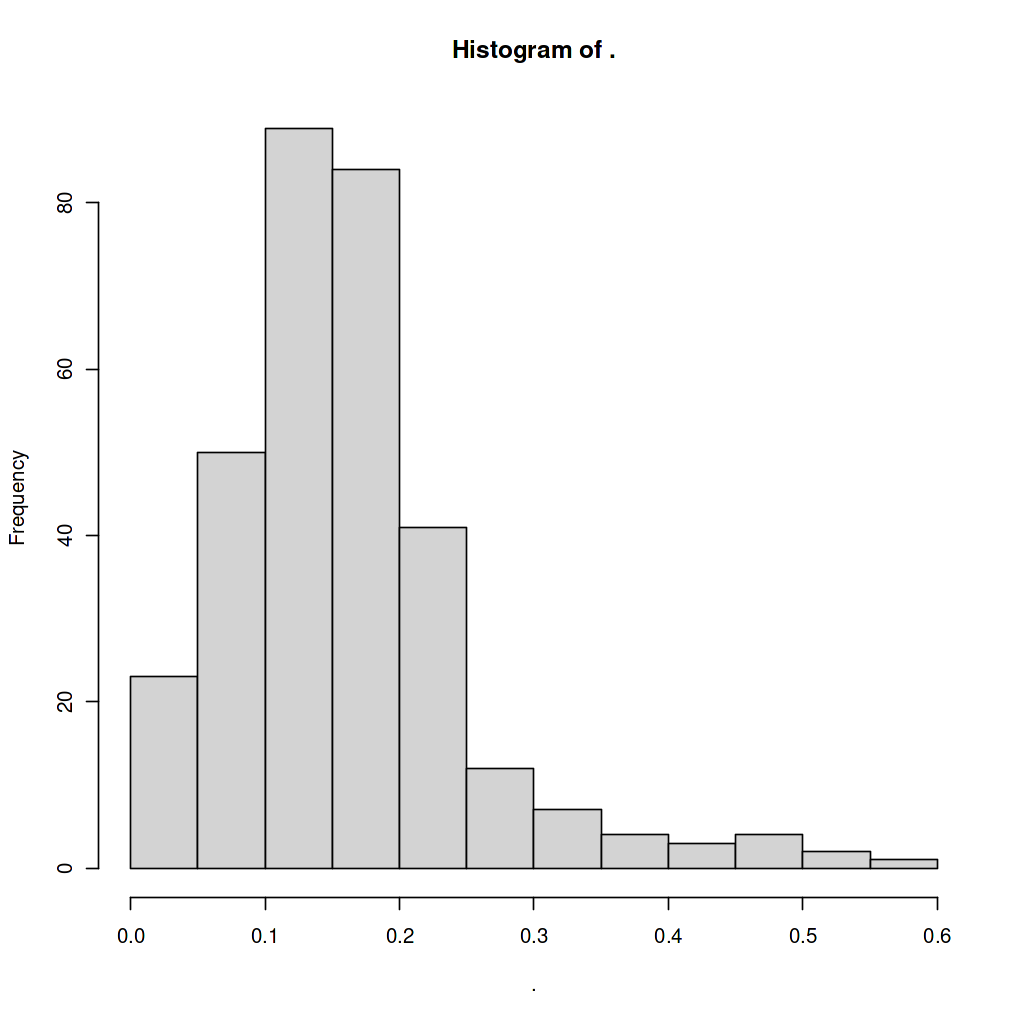

In [442]:
DEY$C2$Glycopiptides4$abs_Delta_IonS %>% hist

In [443]:
res$C2 %>% names

[1] "Glycopiptides4"     "Sig_Glycopiptides4" "Glycoprotein1"     
[4] "Sig_Glycoprotein1"

In [444]:
for (i in names(res)){
#     for (j in names(res[[i]])){
#         outfname = paste('fig.3H.3I.3J',i,j,'GSEA_correlation',sep='_')
#         res[[i]][[j]] %>% as.data.frame() %>% ysave(outfname, outputdir = file.path(OUTPUTROOT,'fig.3H.3I.3J'))
#     }
    outfname = paste('fig.3H.3I.3J.',i,'GSEA_correlation',sep='_')
    res[[i]] %>% ysave(outfname, outputdir = file.path(OUTPUTROOT,'fig.3H.3I.3J'))
}
for (i in names(DEY)){
#     for (j in names(res[[i]])){
#         outfname = paste('fig.3H.3I.3J',i,j,'GSEA_correlation',sep='_')
#         res[[i]][[j]] %>% as.data.frame() %>% ysave(outfname, outputdir = file.path(OUTPUTROOT,'fig.3H.3I.3J'))
#     }
    outfname = paste('fig.3H.3I.3J.',i,'Diff_Ion_intensity_stat',sep='_')
    DEY[[i]] %>% ysave(outfname, outputdir = file.path(OUTPUTROOT,'fig.3H.3I.3J'))
}


[1] "[ 2026-08-24 00:45:31 ]  write 1 xlsx at report_c3/fig.3H.3I.3J/fig.3H.3I.3J._C1_GSEA_correlation.xlsx"
[1] "[ 2026-08-24 00:45:31 ]  write 1 xlsx at report_c3/fig.3H.3I.3J/fig.3H.3I.3J._C2_GSEA_correlation.xlsx"
[1] "[ 2026-08-24 00:45:32 ]  write 1 xlsx at report_c3/fig.3H.3I.3J/fig.3H.3I.3J._C3_GSEA_correlation.xlsx"
[1] "[ 2026-08-24 00:45:33 ]  write 1 xlsx at report_c3/fig.3H.3I.3J/fig.3H.3I.3J._C1_Diff_Ion_intensity_stat.xlsx"
[1] "[ 2026-08-24 00:45:33 ]  write 1 xlsx at report_c3/fig.3H.3I.3J/fig.3H.3I.3J._C2_Diff_Ion_intensity_stat.xlsx"
[1] "[ 2026-08-24 00:45:33 ]  write 1 xlsx at report_c3/fig.3H.3I.3J/fig.3H.3I.3J._C3_Diff_Ion_intensity_stat.xlsx"


### fig 3H 3I 3J
This notebook writes the correlation / differential-intensity data to `report_c3/fig.3H.3I.3J/`; **Fig 3H, 3I and 3J are plotted manually** from these data.

In [211]:
res$C2$Glycoprotein1

,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,HALLMARK_COMPLEMENT,HALLMARK_DNA_REPAIR,HALLMARK_E2F_TARGETS,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,HALLMARK_ESTROGEN_RESPONSE_EARLY,⋯,KEGG_TIGHT_JUNCTION,KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY,KEGG_TRYPTOPHAN_METABOLISM,KEGG_TYPE_I_DIABETES_MELLITUS,KEGG_TYPE_II_DIABETES_MELLITUS,KEGG_TYROSINE_METABOLISM,KEGG_UBIQUITIN_MEDIATED_PROTEOLYSIS,KEGG_VALINE_LEUCINE_AND_ISOLEUCINE_BIOSYNTHESIS,KEGG_VALINE_LEUCINE_AND_ISOLEUCINE_DEGRADATION,KEGG_VASCULAR_SMOOTH_MUSCLE_CONTRACTION,KEGG_VASOPRESSIN_REGULATED_WATER_REABSORPTION,KEGG_VEGF_SIGNALING_PATHWAY,KEGG_VIBRIO_CHOLERAE_INFECTION,KEGG_VIRAL_MYOCARDITIS,KEGG_WNT_SIGNALING_PATHWAY
5HT3B,0.1699605,-0.01863354,0.2444946,0.2027103,0.01750423,0.001693958,0.18238283,0.2817617,0.2332016,0.18012422,0.0513834,0.06606437,0.33822699,0.3404856,0.1168831,⋯,-0.15527950,0.02653868,0.1710898,-0.0931677,-0.08977979,-0.0525127,0.1665726,0.02653868,0.1835121,-0.21174478,0.2806324,-0.18125353,0.033314512,-0.1981931,0.2117448
A1AG1,0.1394692,-0.38904574,0.2490119,0.1597967,0.21513269,0.050254094,-0.06154715,0.4105025,0.2715980,-0.04234896,-0.3370977,0.13269339,0.04121965,0.2580463,0.3438735,⋯,0.08526256,-0.30886505,0.1722191,-0.2659514,0.15979673,0.1880294,-0.1518916,-0.18802936,0.2060982,0.06154715,0.3811406,-0.14285714,0.031055901,-0.2230378,0.2874082
A1AG2,0.1315641,-0.25804630,0.2862789,0.1857708,0.17334839,-0.022021457,0.05702993,0.3788820,0.2388481,0.01411632,-0.2286844,0.10446076,0.09994353,0.2851496,0.2727273,⋯,0.02766798,-0.19141728,0.2106155,-0.1857708,0.17447770,0.1168831,-0.1473744,-0.14737436,0.2422360,0.02879729,0.2941841,-0.06380576,0.002823264,-0.1823828,0.2264257
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZN677,0.072840203,0.04912479,0.13043478,-0.09429701,0.009599097,-0.016374929,0.06154715,0.39808018,0.11462451,-0.08639187,-0.03105590,-0.11123659,0.01411632,-0.1338227,0.01524562,⋯,0.07961604,0.12027103,0.21626200,-0.14624506,0.2332015810,-0.1101073,-0.1552795,0.09316770,0.02428007,0.09768492,-0.10107284,0.24675325,-0.0107284020,0.13495200,0.04121965
ZN768,-0.008469791,-0.11010728,0.04234896,0.21626200,0.217391304,-0.007340486,0.18915867,0.03896104,0.06493506,0.19480519,0.01524562,0.08977979,0.02992660,0.3867871,0.16770186,⋯,0.04121965,-0.04686618,-0.05590062,0.02428007,0.2693393563,-0.1349520,-0.2060982,-0.11801242,0.12704687,-0.04460757,0.07735743,-0.00621118,-0.0570299266,-0.04234896,0.08074534
ZN840,0.169960474,-0.15527950,0.40937324,0.14511575,0.079616036,-0.066064370,0.19254658,0.27611519,0.45793337,-0.03331451,-0.15640881,0.04799548,0.17447770,0.2795031,0.21739130,⋯,0.04009034,-0.13946923,0.11236589,-0.01411632,0.0005646527,0.2173913,0.1552795,-0.01411632,0.14850367,-0.01185771,0.42970073,-0.03896104,-0.0005646527,-0.02766798,0.28740824


In [208]:
c2 = DEY_raw$Glycoprotein1$C2
c2

symbol,log2FoldChange,baseMean,t,pvalue,padj,B,stat,abs_log2FC,FC_Ins,median_C2,median_Others,significant
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<lgl>
THRB,1.120170,6.66087,4.992915,3.688257e-06,0.0001310712,4.085545,4.992915,1.120170,TRUE,7.373533,6.46116,TRUE
LIN54,1.909846,10.69839,4.966978,4.080037e-06,0.0001310712,3.989189,4.966978,1.909846,TRUE,11.820454,10.00729,TRUE
FIBG,4.447499,24.36788,4.697449,1.148353e-05,0.0001737232,3.003211,4.697449,4.447499,TRUE,26.971242,22.76754,TRUE
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ARLY,-0.01947755,1.106752,-0.2532467,0.8007617,0.8070422,-6.581251,-0.2532467,0.01947755,FALSE,1.044643,1.0275630,FALSE
IGA2,0.03349633,1.029834,0.2227354,0.8243393,0.8275594,-6.588472,0.2227354,0.03349633,TRUE,1.020459,0.9631582,FALSE
SEMG2,0.03380186,1.006258,0.1526873,0.8790498,0.8790498,-6.601552,0.1526873,0.03380186,TRUE,1.046702,0.9168096,FALSE


## fig 3K

In [271]:
gly = db.importing('external_data/Glycosylation/merged/gly_mat_filled.dfx',row.names=1)
gly

[1] "[ 2026-08-08 14:52:34 ]  read [ gly_mat_filled.dfx ] as ' gly_mat_filled ' from >  external_data/Glycosylation/merged"


,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,⋯,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",1.4604336,0.8752324,1.140283,1.113961,0.6897214,0.9178214,0.9531142,0.9567009,1.1607213,1.1031263,0.8386507,1.346298,0.9629256,1.198657,1.182978,⋯,1.0113577,0.7503375,1.0126682,0.9112473,1.159548,1.384214,1.1249294,1.230361,1.0776342,1.137196,0.9538154,1.224469,0.8291804,1.1597196,1.056966
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",0.9803645,0.8839520,1.018809,1.033549,0.7293284,0.8949293,1.0263995,1.0846603,1.0229187,0.9762586,0.8001056,1.115954,1.0934455,1.148254,1.132967,⋯,0.9560659,0.7247063,1.0311286,0.8359769,1.268521,1.226571,0.9299881,1.121186,0.9296188,1.010970,0.9431176,1.189545,0.8627233,1.1061263,1.045284
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",1.0265413,0.8610104,1.106466,1.026120,0.9560404,0.8173394,1.1538808,1.0747509,0.8822343,1.1711675,1.1090968,1.281588,0.9707129,1.028832,1.164441,⋯,0.8759252,0.7857961,0.9197497,0.8213505,1.108068,1.367655,1.0117504,1.127344,1.1607086,1.082432,0.9553803,1.111752,0.9633391,0.9722804,1.191983
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.2018486,0.5834520,0.202225,0.7518399,0.8144400,0.4856933,1.4173133,0.9571654,0.0000000,0.4427535,0.0000000,0.7598527,0.000000,1.7562356,0.000000,⋯,0.8625268,0.228025,0.1070833,0.5925123,0.5540574,1.291385,0.6694104,0.4111268,0.7976667,0.2947446,0.7238596,0.9334188,0.6173886,0.6007130,0.5486446
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",0.9035773,0.8827086,1.298107,1.5360447,1.1242232,1.0675743,1.1231554,1.1931559,0.9871492,0.8545404,1.4662708,1.2363903,1.610913,1.7168949,1.347381,⋯,1.1826217,1.526242,1.0118120,0.9263965,0.6161890,1.094275,0.9036573,1.1880330,0.8224514,1.1449867,1.2422153,0.9611747,1.1335952,1.2821091,1.5031110
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",0.8138225,1.0745428,1.054827,0.9739086,0.9289793,0.7182039,0.9303606,1.3480608,1.5212397,1.1757096,0.8636228,1.1480373,1.887907,0.8751825,1.109611,⋯,1.1841947,0.000000,0.4980346,0.6623515,0.7522412,0.000000,0.0000000,0.0000000,0.0000000,0.7420099,0.0000000,1.0082480,0.0000000,0.8265547,0.0000000


In [272]:
des = db.importing('external_data/Glycosylation/merged/gly_mat_id_des_x.dfx')
des

[1] "[ 2026-08-08 14:52:34 ]  read [ gly_mat_id_des_x.dfx ] as ' gly_mat_id_des_x ' from >  external_data/Glycosylation/merged"


V1,GID,Protein_Name,Protein_ID,sPeptide,sProPos,sGlycan,sMod,sCharge,Spectrum_ID,batch,Rank,Peptide,Proteins,Charge,"Glycan(H,N,A,F)",Empty_Separator,GlyMass,Glytoucan_search,GlycanComposition,Supp_Info,repeat,tool
<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<int>,<int>,<chr>,<chr>,<int>,<chr>,<lgl>,<dbl>,<chr>,<chr>,<lgl>,<chr>,<chr>
0,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",CD47,Q08722,DIYTFDGALNK,73,5 2 0 0,"1,IBT16[N-term];11,IBT16[K]",3,27788.28,1,1,DIYTFDGALJK,sp|Q08722|CD47_HUMAN;sp|Q08722-2|CD47_HUMAN;sp|Q08722-3|CD47_HUMAN;sp|Q08722-4|CD47_HUMAN,3,5 2 0 0,NA,1216.4229,"5 hex, 2 hexnac, 0 neu5ac, 0 dhex",H(5)N(2),NA,E,pGlyco
1,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",APMAP,Q9HDC9,AGPNGTLFVADAYK,160,3 3 0 1,"1,IBT16[N-term];14,IBT16[K]",3,26727.27,1,1,AGPJGTLFVADAYK,sp|Q9HDC9|APMAP_HUMAN;sp|Q9HDC9-2|APMAP_HUMAN,3,3 3 0 1,NA,1241.4545,"3 hex, 3 hexnac, 0 neu5ac, 1 dhex",H(3)N(3)F(1),NA,E,pGlyco
2,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",MFAP4,P55083,FNGSVSFFR,111;87,3 2 0 0,"1,IBT16[N-term]",3,25538.26,1,1,FJGSVSFFR,sp|P55083|MFAP4_HUMAN;sp|P55083-2|MFAP4_HUMAN,3,3 2 0 0,NA,892.3172,"3 hex, 2 hexnac, 0 neu5ac, 0 dhex",H(3)N(2),NA,E,pGlyco
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
2021,"P01009:A1AT:107:ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR:1,IBT16[N-term]:4 5 1 0:4",A1AT,P01009,ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR,107,4 5 1 0,"1,IBT16[N-term]",4,42233.42,6,2,K.[+277.18814].ADTHDEILEGLNFN[+2261.79390]LTEIPEAQIHEGFQELLR.T,>sp|P01009|A1AT_HUMAN Alpha-1-antitrypsin OS=Homo sapiens OX=9606 GN=SERPINA1 PE=1 SV=3,4,4 5 1 0,NA,2261.794,"4 hex, 5 hexnac, 1 neu5ac, 0 dhex",H(4)N(5)A(1),NA,5,byonic
2022,"P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR:1,IBT16[N-term];19,Oxidation[M]:6 5 0 1:4",CO6A1,P12109,ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,6 5 0 1,"1,IBT16[N-term];19,Oxidation[M]",4,42394.42,6,3,R.[+277.18814].ASLQFLQN[+2133.77171]YTALASAVDAM[+15.99492]DFINDATDVNDALGYVTR.F,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) chain OS=Homo sapiens OX=9606 GN=COL6A1 PE=1 SV=3,4,6 5 0 1,NA,2133.772,"6 hex, 5 hexnac, 0 neu5ac, 1 dhex",H(6)N(5)F(1),NA,5,byonic
2023,"P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR:1,IBT16[N-term];19,Oxidation[M]:5 4 2 1:4",CO6A1,P12109,ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,5 4 2 1,"1,IBT16[N-term];19,Oxidation[M]",4,42923.43,6,3,R.[+277.18814].ASLQFLQN[+2350.83035]YTALASAVDAM[+15.99492]DFINDATDVNDALGYVTR.F,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) chain OS=Homo sapiens OX=9606 GN=COL6A1 PE=1 SV=3,4,5 4 2 1,NA,2350.830,"5 hex, 4 hexnac, 2 neu5ac, 1 dhex",H(5)N(4)A(2)F(1),NA,5,byonic


In [273]:
vname = 'Glycopiptides4'
colname = 'GID'
mat = db.importing(paste0('matFlt',vname),frm = 'export_big') %>% 
    column_to_rownames(colname) %>% as.matrix
des = db.importing(paste0('desFlt',vname),frm = 'export_big') %>% 
    column_to_rownames(colname) %>%
    dplyr::rename(HM = HighMannose,Fu = Fucose, SA=`Sialic Acid`,Bs = Bisect) %>%
    dplyr::select(HM,Fu,SA,Bs, everything())

[1] "[ 2026-08-08 14:52:35 ]  read [ matFltGlycopiptides4.dfx ] as ' matFltGlycopiptides4 ' from >  export_big"
[1] "[ 2026-08-08 14:52:35 ]  read [ desFltGlycopiptides4.dfx ] as ' desFltGlycopiptides4 ' from >  export_big"


In [274]:
des

,HM,Fu,SA,Bs,H,N,A,F,sPeptide,GlycanComposition,sGlycan,Protein_Name,sProPos,Protein_ID,sCharge,sProteinNameID,Glycosite
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3",HighMan,NA,NA,NA,4,2,0,0,FNGSVSFFR,H(4)N(2),4 2 0 0,MFAP4,111;87,P55083,3,P55083_MFAP4,P55083_MFAP4:111;87
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",HighMan,NA,NA,NA,5,2,0,0,FNGSVSFFR,H(5)N(2),5 2 0 0,MFAP4,111;87,P55083,3,P55083_MFAP4,P55083_MFAP4:111;87
"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",HighMan,NA,NA,NA,5,2,0,0,RFNGSVSFFR,H(5)N(2),5 2 0 0,MFAP4,111;87,P55083,3,P55083_MFAP4,P55083_MFAP4:111;87
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
"Q07954:LRP1:2117:THANGSIK:1,IBT16[N-term];8,IBT16[K]:5 4 0 1:3",NA,CoreFUC,NA,NA,5,4,0,1,THANGSIK,H(5)N(4)F(1),5 4 0 1,LRP1,2117,Q07954,3,Q07954_LRP1,Q07954_LRP1:2117
"P12110:CO6A2:327:NGTDGQK:1,IBT16[N-term];7,IBT16[K]:7 2 0 0:3",HighMan,NA,NA,NA,7,2,0,0,NGTDGQK,H(7)N(2),7 2 0 0,CO6A2,327,P12110,3,P12110_CO6A2,P12110_CO6A2:327
"P51884:LUM:88:AFENVTDLQWLILDHNLLENSK:1,IBT16[N-term];22,IBT16[K]:5 4 1 1:4",NA,CoreFUC,SIA,NA,5,4,1,1,AFENVTDLQWLILDHNLLENSK,H(5)N(4)A(1)F(1),5 4 1 1,LUM,88,P51884,4,P51884_LUM,P51884_LUM:88


In [275]:
SEL_GENE = 'MFAP4'
sel = des %>% filter(Protein_Name==!!SEL_GENE) %>% 
    filter(sPeptide == 'VDLEDFENNTAYAK') %>%
    filter(`sGlycan`=='5 4 1 1') %>% rownames()
sel

[1] "P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:4"
[2] "P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:3"
[3] "P55083:MFAP4:137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:3"

In [276]:
glx = db.importing('glx_86',frm=INPUTROOT)
glx

[1] "[ 2026-08-08 14:52:35 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  export_c3"


tsb,Group,Response
<chr>,<chr>,<chr>
P72,C1,non.pCR
P10,C1,non.pCR
P14,C1,non.pCR
⋮,⋮,⋮
P78,pCR,pCR
P76,pCR,pCR
P79,pCR,pCR


In [277]:
mat[sel,] %>% rownames %>% unique

[1] "P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:4"
[2] "P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:3"
[3] "P55083:MFAP4:137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:3"

In [278]:
df_gly =  mat[sel,] %>% as.data.frame() %>%
    rownames_to_column("GID") %>% 
    mutate(GID= GID %>% str_split(':', simplify = TRUE) %>% .[,c(3,7)] %>% 
            apply(1, FUN = partial(str_flatten, collapse = ':'))
          ) %>% 
    pivot_longer(-GID,names_to = 'tsb', values_to = 'value') %>%
    left_join(glx) %>% filter(Group !='pCR')
df_gly

Joining with `by = join_by(tsb)`


GID,tsb,value,Group,Response
<chr>,<chr>,<dbl>,<chr>,<chr>
161;137:4,P01,0.9080194,C3,non.pCR
161;137:4,P02,0.8675709,C3,non.pCR
161;137:4,P03,1.0332909,C3,non.pCR
⋮,⋮,⋮,⋮,⋮
137:3,P84,0.9648597,C1,non.pCR
137:3,P85,0.9508333,C2,non.pCR
137:3,P86,1.0847430,C2,non.pCR


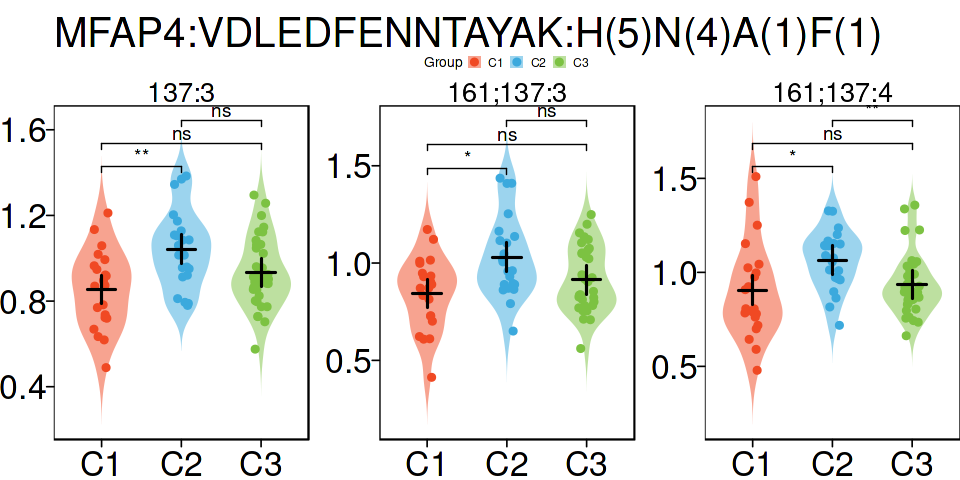

In [279]:
make.custom(8,4)
gg.gly = df_gly %>% ggplot(aes(x = Group, y = value, fill = Group)) +
    geom_violin(alpha=0.5, color=NA, trim = FALSE, width=0.75, scale = 'width')+
    geom_point(aes(color=Group)
               ,show.legend = TRUE
#            ,size=0.2
#            ,alpha = 0.5
           ,position=position_jitterdodge(jitter.width = 0.2
                                          ,dodge.width = 0.75)
          ) +
    facet_wrap(~GID, scales = 'free') +
    stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1, show.legend = FALSE) +
    scale_color_manual(values = COL_ANNO$Group, breaks = names(COL_ANNO$Group)) +
    scale_fill_manual(values = COL_ANNO$Group, breaks = names(COL_ANNO$Group))+
    theme_pc() +
    ggpubr::stat_pwc(aes(label = ypvalue_add_asterisks(after_stat(p.adj))), hide.ns = FALSE) +
    ggtitle('MFAP4:VDLEDFENNTAYAK:H(5)N(4)A(1)F(1)')

gg.gly

In [280]:
# used in paper is the 3rd violin plot, GID = 
# 'P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:3'

In [430]:
make.custom(8,4)
gg.gly %>% ysave('fig.3K.MFAP4.violin', outputdir = OUTPUTROOT)
df_gly %>% ysave('fig.3K.MFAP4.violin', outputdir = OUTPUTROOT)

[1] "[ 2026-08-09 03:39:47 ]  write 1 pdf at report_c3/fig.3K.MFAP4.violin.pdf"
[1] "[ 2026-08-09 03:39:47 ]  write 1 xlsx at report_c3/fig.3K.MFAP4.violin.xlsx"


## fig S5A S5B

In [12]:
glx = db.importing('export_c3/wes_glx.dfx') %>% dplyr::rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification)
non.pcr = glx %>% filter(Group!='pCR') %>% pull(tsb)
non.pcr


[1] "[ 2026-09-12 14:16:09 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


[1] "P72" "P10" "P14" "P56" "P16" "P52" "P47" "P80" "P70" "P71" "P83" "P82"
[13] "P84" "P43" "P60" "P49" "P65" "P51" "P39" "P45" "P66" "P34" "P05" "P29"
[25] "P69" "P53" "P28" "P86" "P85" "P06" "P42" "P18" "P57" "P63" "P17" "P62"
[37] "P41" "P25" "P27" "P46" "P11" "P20" "P30" "P38" "P03" "P37" "P58" "P19"
[49] "P61" "P24" "P23" "P36" "P44" "P32" "P67" "P31" "P68" "P12" "P13" "P73"
[61] "P59" "P54" "P08" "P55" "P22" "P07" "P33" "P09" "P40" "P15" "P26" "P50"
[73] "P04" "P02" "P01" "P21" "P48"

In [13]:
res.deg  = readRDS('export_c3/fig2_deg_dap.RDS')
anno_data = db.importing('export_c3/fig2_volcano_select_symbols.dfx')
anno_data

[1] "[ 2026-09-12 14:16:10 ]  read [ fig2_volcano_select_symbols.dfx ] as ' fig2_volcano_select_symbols ' from >  export_c3"


omic,Group,symbol
<chr>,<chr>,<chr>
RNAseq,C1,RAB3B
RNAseq,C1,AMACR
RNAseq,C1,KLK3
⋮,⋮,⋮
Protein,C3,GSTM3
Protein,C3,RAB34
Protein,C3,ACTG1


In [14]:
matp = db.importing('export_by2_86_pCR_nonpCR/prt_x_7346.dfx',row.names=1) %>% as.matrix
matr = db.importing('export_by2_86_pCR_nonpCR/rna_count.dfx',row.names=1)%>% as.matrix

matp = matp[,non.pcr]
matr = matr[,non.pcr]
matp
matr

[1] "[ 2026-09-12 14:16:10 ]  read [ prt_x_7346.dfx ] as ' prt_x_7346 ' from >  export_by2_86_pCR_nonpCR"
[1] "[ 2026-09-12 14:16:12 ]  read [ rna_count.dfx ] as ' rna_count ' from >  export_by2_86_pCR_nonpCR"


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
A1BG,-0.4503532,-0.1763565,-0.1674641,-0.09821636,-0.3900006,-0.02107001,-0.07319702,0.28097609,-0.2360201,-0.06241848,-0.06081656,0.254332178,0.19313675,-0.3165919,-0.08832465,⋯,0.09307132,-0.04438771,0.03916176,-0.2096906,0.003290244,-0.18867919,-0.21520441,0.10716068,0.06233078,0.1631934,0.002907455,0.2939069,0.287177300,0.46021669,0.1273033
A2M,-0.7344648,-0.3843764,-0.7912119,-0.85022267,-0.6991169,-0.44057899,0.19519318,0.47887702,0.2106339,-0.29646970,-0.26987836,-0.006584813,0.08291092,-0.6313362,-0.59934765,⋯,-0.29084987,-0.05774938,-0.37298434,-0.3369603,0.120576223,-0.25064389,-0.41658912,0.07218912,0.01744755,0.2449074,0.030336738,0.4094927,0.002229604,-0.16008838,0.3765419
NAT1,-0.4062785,0.9339046,0.1643513,0.80686294,-0.0804949,-0.23864566,0.54111059,-0.08672934,0.1205570,-0.10921825,0.14163022,-0.003910516,0.11802263,0.1567885,0.61641066,⋯,0.09370171,-0.11199446,-0.18808298,-0.3611383,-0.359137264,0.04050201,-0.07723629,0.17016346,-0.02011665,-0.1441538,0.290496090,0.1430298,-0.026871998,-0.03992174,-0.0830341
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
MMP24OS,0.01028101,-0.09939606,0.35936385,0.03099385,0.07781559,0.20887917,-0.05694813,-0.10943026,-0.03650823,-0.08644839,-0.006554967,0.07455987,0.04642637,-0.26783294,-0.3295093,⋯,0.0229764,0.05462692,-0.09081492,0.21506206,0.05979276,-0.09789900,-0.1122083,-0.39227925,-0.1583624,0.10856727,-0.76502545,-0.04444896,-0.621264397,-0.1526152,0.05014078
PIGBOS1,-0.10079324,0.08074380,0.02440433,-0.29328664,-0.19565603,0.15865734,0.08563127,1.11805949,-0.13716092,0.04422397,0.050621964,0.27900442,0.25783404,-0.73473431,-1.0147595,⋯,-0.0586082,0.17179920,-0.08974961,-0.09163530,0.20034071,0.23340032,-0.2667565,-0.06805847,0.1179062,0.64407899,0.12671735,-0.11042890,-0.049884599,-0.1064675,-0.06735307
C11orf98,0.48660996,0.32200949,0.18103901,-0.00950158,0.30577734,0.09663794,-0.01201577,0.04104325,0.09258186,0.27483949,0.150302465,0.07265562,0.26595657,-0.01194148,0.1482243,⋯,0.3175692,0.12676766,0.03862909,0.08974135,0.13361230,-0.02536341,-0.1628972,-0.05487164,-0.1363125,0.05306228,0.05945041,0.17542232,0.004816554,0.1327139,-0.00052700


,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,⋯,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
A1BG,3,2,8,7,4,7,8,0,17,4,3,4,5,4,13,⋯,11,14,17,22,10,15,10,8,11,8,10,12,7,13,13
A1CF,2,1,56,10,1027,32,22,0,2,2,15,1,0,4,6,⋯,27,10,685,1,3,0,4,16,7,21,6,8,17,5,9
A2M,31149,132159,14766,40855,103957,318602,153836,147314,384947,79687,44561,222087,125096,35851,78911,⋯,271831,216297,137560,119693,263121,138792,87035,106188,122937,236040,439178,217996,94068,276198,176080
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZYX,875,3733,2092,2311,2895,4270,2477,1122,4932,2178,2230,3670,2898,2977,2488,⋯,5620,4090,3458,4276,3364,5027,5482,2047,4467,4078,4387,3522,2364,3911,3635
ZZEF1,4281,7679,5691,7901,5864,10511,6443,5276,8844,6815,7512,10099,9762,9526,9236,⋯,15466,10757,10070,10649,7774,12599,9806,7261,10179,7987,9687,9942,8083,8271,8308
ZZZ3,3433,1713,2886,2461,3603,4453,2680,3469,5190,4911,4234,5574,4107,3874,2811,⋯,6360,4370,2821,3134,2398,4338,3878,3477,3577,3401,2962,3065,3029,2646,2669


In [450]:
res.deg$RNAseq$C2$deg

symbol,baseMean,log2FoldChange,abs_log2FC,lfcSE,stat,pvalue,padj
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FCGR2B,568.0294,1.7120464,1.7120464,0.2182042,7.846074,4.292646e-15,7.619018e-11
SIRPA,1736.6384,0.9217225,0.9217225,0.1194301,7.717674,1.184715e-14,8.375128e-11
FTL,44445.9753,1.3969234,1.3969234,0.1815379,7.694941,1.415594e-14,8.375128e-11
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ZNF577,0,NA,NA,NA,NA,NA,NA
ZNF727,0,NA,NA,NA,NA,NA,NA
ZNF883,0,NA,NA,NA,NA,NA,NA


In [451]:
res.deg$Protein$C2$deg

symbol,Delta_Prt_Abundance,baseMean,t,pvalue,padj,B,stat,abs_Delta_PrtA,Delta_Ins,median_C2,median_Others
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>
APOE,0.7023319,-0.03264133,9.321200,2.546754e-14,1.893767e-10,21.95305,9.321200,0.7023319,TRUE,0.4610751,-0.2447339
CCDC40,0.5290192,-0.02350588,8.360242,1.869007e-12,6.867518e-09,17.89821,8.360242,0.5290192,TRUE,0.3640098,-0.2081355
C1QC,0.4496587,0.01699335,8.242229,3.167675e-12,6.867518e-09,17.39930,8.242229,0.4496587,TRUE,0.3084470,-0.1473935
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
FAM102B,6.503010e-05,0.02470455,0.0020118436,0.9983999,0.9986685,-6.363403,0.0020118436,6.503010e-05,TRUE,0.026288226,0.01345910
MPP7,5.786758e-05,-0.07211085,0.0010865770,0.9991358,0.9992702,-6.363404,0.0010865770,5.786758e-05,TRUE,-0.067141959,-0.05573943
ATIC,6.356355e-06,0.01121479,0.0002436654,0.9998062,0.9998062,-6.363405,0.0002436654,6.356355e-06,TRUE,0.004372797,0.02290795


In [456]:
make.custom(10,9)

grps = c("C2")
omics = list(RNAseq=matr
            ,Protein=matp
            )

for (grp in grps){
    # do DEG
    for (omic in names(omics)){
        if (omic == 'RNAseq'){
            t_logFC = 1
            title = 'DEG' # different Expressed Genes
            xlimits = 5
            
            straw_len = xlimits / 10
            sel_genes = anno_data %>% filter(omic == !!omic, Group == !!grp) %>% pull("symbol")

            deg = res.deg[[omic]][[grp]]$deg %>% 
                filter(!is.na(log2FoldChange)) %>% 
                mutate(class = ifelse(abs_log2FC > !!t_logFC & padj < 0.05, 
                                      ifelse(log2FoldChange>0, 'Up', 'Down'), 'Not Sig.')
                      , `-log10(FDR)` = -log10(padj)
                      , `-log10(FDR)` = ifelse(is.na(`-log10(FDR)`),Inf,`-log10(FDR)`)
                      , focused_gene = symbol %in% !!sel_genes
                  ) 
            df_anno = deg %>% filter(symbol %in% !!sel_genes)

            gg  = deg %>% ggplot(aes(x = log2FoldChange, `-log10(FDR)`)) +
                geom_point(aes(color = class, size = class), alpha = 0.4) +
                geom_vline(xintercept = t_logFC, linetype= 5, color = 'gray50') +
                geom_vline(xintercept = -t_logFC, linetype= 5, color = 'gray50') +    
                geom_hline(yintercept = -log10(0.05), linetype= 5, color = 'gray50') +
                scale_x_continuous(limits = c(-xlimits,xlimits)) +
                ggrepel::geom_text_repel(data  = df_anno, aes(label = symbol),max.iter = 10, nudge_x = straw_len, nudge_y = straw_len ) + 
    #             geom_segment(data = df_anno, aes(xend = log2FoldChange + straw_len, yend = `-log10(FDR)` + straw_len)) +
                scale_color_manual(values =  c('red','gray50','blue'), breaks = c('Up', 'Not Sig.','Down')) +
                scale_size_manual(values = c(3,1.5,3), breaks = c('Up', 'Not Sig.','Down')) +
                theme_bw(base_size = 18) +
                ggtitle(paste(grp, omic, title, "FDR < 0.05",'abs(log2FC) >',t_logFC))
            res.deg[[omic]][[grp]]$vol_deg = deg  
            res.deg[[omic]][[grp]]$gg.vol = gg
            res.deg[[omic]][[grp]]$selected = sel_genes
            
        }else{
            t_logFC = 0.5
            title = 'DAP' # different Abundance Proteins
            xlimits = 1
            
            straw_len = xlimits / 10
            sel_genes = anno_data %>% filter(omic == !!omic, Group == !!grp) %>% pull("symbol")

            deg = res.deg[[omic]][[grp]]$deg %>% 
                filter(!is.na(Delta_Prt_Abundance)) %>% 
                mutate(class = ifelse(abs_Delta_PrtA > !!t_logFC & padj < 0.05, 
                                      ifelse(Delta_Prt_Abundance>0, 'Up', 'Down'), 'Not Sig.')
                      , `-log10(FDR)` = -log10(padj)
                      , `-log10(FDR)` = ifelse(is.na(`-log10(FDR)`),Inf,`-log10(FDR)`)
                      , focused_gene = symbol %in% !!sel_genes
                  ) 
            df_anno = deg %>% filter(symbol %in% !!sel_genes)

            gg  = deg %>% ggplot(aes(x = Delta_Prt_Abundance, `-log10(FDR)`)) +
                geom_point(aes(color = class, size = class), alpha = 0.4) +
                geom_vline(xintercept = t_logFC, linetype= 5, color = 'gray50') +
                geom_vline(xintercept = -t_logFC, linetype= 5, color = 'gray50') +    
                geom_hline(yintercept = -log10(0.05), linetype= 5, color = 'gray50') +
                scale_x_continuous(limits = c(-xlimits,xlimits)) +
                ggrepel::geom_text_repel(data  = df_anno, aes(label = symbol),max.iter = 10, nudge_x = straw_len, nudge_y = straw_len ) + 
    #             geom_segment(data = df_anno, aes(xend = Delta_Prt_Abundance + straw_len, yend = `-log10(FDR)` + straw_len)) +
                scale_color_manual(values =  c('red','gray50','blue'), breaks = c('Up', 'Not Sig.','Down')) +
                scale_size_manual(values = c(3,1.5,3), breaks = c('Up', 'Not Sig.','Down')) +
                theme_bw(base_size = 18) +
                ggtitle(paste(grp, omic, title, "FDR < 0.05",'abs(ΔPrtAbundance) >',t_logFC)) +
                xlab('ΔPrtAbundance')
            res.deg[[omic]][[grp]]$vol_deg = deg  
            res.deg[[omic]][[grp]]$gg.vol = gg
            res.deg[[omic]][[grp]]$selected = sel_genes
        }
    }
}

Warning message:
“Removed 124 rows containing missing values (`geom_point()`).”


[1] "[ 2026-08-24 01:06:47 ]  write 1 pdf at report_c3/fig.S5A.rna_C2_deg_vol.pdf"


Warning message:
“Removed 124 rows containing missing values (`geom_point()`).”


[1] "[ 2026-08-24 01:06:48 ]  write 1 xlsx at report_c3/fig.S5A.rna_C2_deg_vol.xlsx"


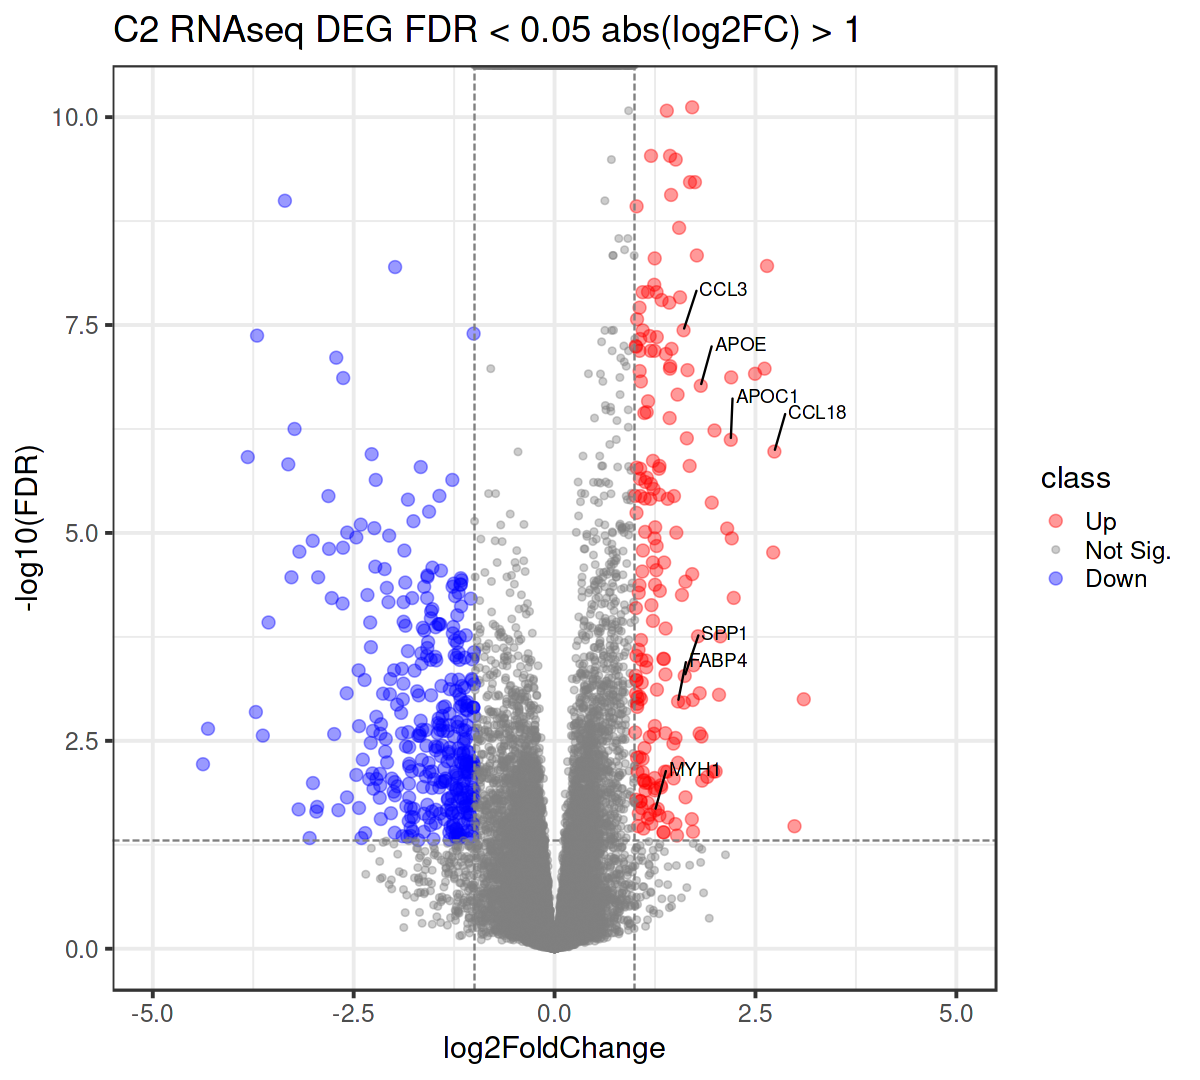

In [453]:
# different Expressed Genes
res.deg$RNA$C2$gg.vol %T>% ysave('fig.S5A.rna_C2_deg_vol')
res.deg$RNA$C2$vol_deg %>% ysave('fig.S5A.rna_C2_deg_vol')

[1] "[ 2026-08-24 01:08:12 ]  write 1 pdf at report_c3/fig.S5B.prt_C2_dap_vol.pdf"
[1] "[ 2026-08-24 01:08:13 ]  write 1 xlsx at report_c3/fig.S5B.prt_C2_dap_vol.xlsx"


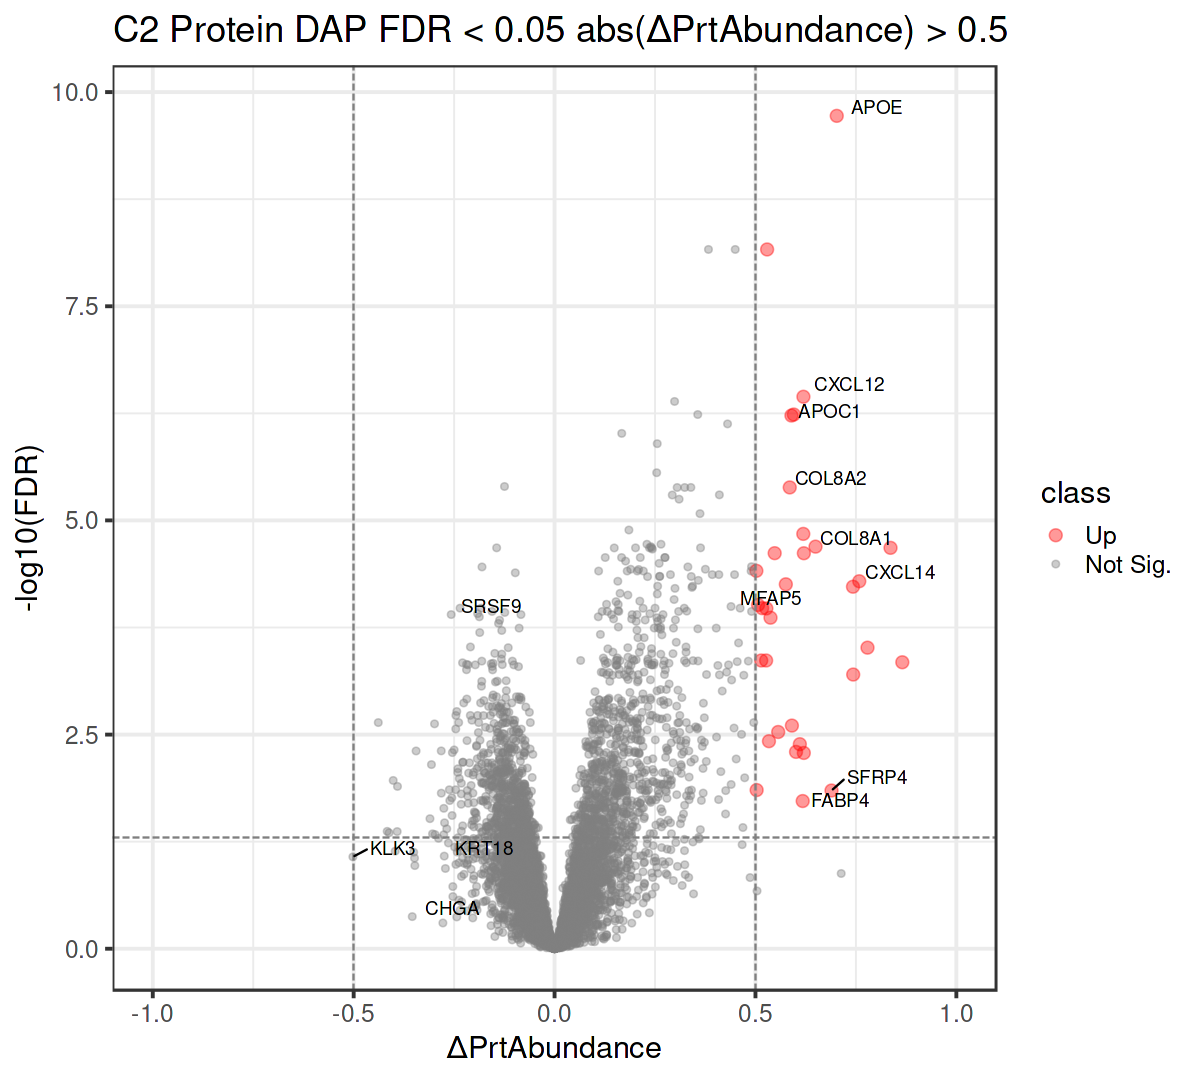

In [457]:
# different Abundance Proteins
res.deg$Protein$C2$gg.vol %T>% ysave('fig.S5B.prt_C2_dap_vol')
res.deg$Protein$C2$vol_deg %>% ysave('fig.S5B.prt_C2_dap_vol')

## fig S5C
**Fig S5C — manually generated.** This panel was drawn manually with external tools; there is no plotting code in this repository. (EnrichmentMap network of GO terms enriched in C2)

## fig S5D

In [287]:
p.hm = db.importing('export_c3/data_prt_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
r.hm = db.importing('export_c3/data_rna_hm_ssgsea.dfx', row.names = 1) %>% as.matrix
rownames(p.hm) = rownames(p.hm) %>% str_sub(10)
rownames(r.hm) = rownames(r.hm) %>% str_sub(10)
p.hm = p.hm[rownames(r.hm), ]
r.hm

[1] "[ 2026-08-08 14:52:43 ]  read [ data_prt_hm_ssgsea.dfx ] as ' data_prt_hm_ssgsea ' from >  export_c3"
[1] "[ 2026-08-08 14:52:43 ]  read [ data_rna_hm_ssgsea.dfx ] as ' data_rna_hm_ssgsea ' from >  export_c3"


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,⋯,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
ADIPOGENESIS,0.5352774,0.5298981,0.5090610,0.5184800,0.5354779,0.5211951,0.5200553,0.5073797,0.5289627,0.5582152,0.5324584,0.5302997,0.5183914,0.51410397,0.5143569,⋯,0.5254624,0.5130609,0.4998273,0.4625052,0.5193511,0.5206493,0.4965634,0.4308143,0.5320755,0.5081452,0.5211257,0.5148786,0.5433077,0.5405400,0.5261268
ALLOGRAFT_REJECTION,0.2326303,0.2503244,0.2384866,0.2825841,0.3168723,0.2822995,0.2747259,0.2296043,0.2328125,0.3181382,0.2601588,0.2502184,0.2727498,0.04778801,0.1427947,⋯,0.2204546,0.2065525,0.2156567,0.2980156,0.2005738,0.1740938,0.2306263,0.2949878,0.2336081,0.2375681,0.2177265,0.2871917,0.2306788,0.2579551,0.2704492
ANDROGEN_RESPONSE,0.5890574,0.6126761,0.5148489,0.5700519,0.5536163,0.5677683,0.5944377,0.5979734,0.6070380,0.7073756,0.5689844,0.6164334,0.6692758,0.72334810,0.6111820,⋯,0.7484304,0.6312496,0.5363920,0.5940777,0.5749998,0.6039792,0.5328191,0.6213465,0.6321663,0.5836034,0.6735937,0.6847962,0.6602788,0.5895512,0.6068284
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
UV_RESPONSE_UP,0.3889393,0.3875211,0.3605759,0.3843370,0.4172113,0.3863432,0.3747113,0.3459818,0.3616664,0.4222272,0.3638295,0.3642286,0.3379974,0.3571061,0.3458448,⋯,0.3622854,0.3380766,0.3625837,0.3361088,0.3381536,0.3487323,0.3285762,0.3265504,0.3494795,0.3660530,0.3562501,0.3646824,0.3879374,0.4221292,0.3636105
WNT_BETA_CATENIN_SIGNALING,0.3893363,0.3750230,0.3840608,0.3899763,0.3702702,0.3878891,0.3967736,0.3442367,0.3888042,0.3496347,0.3902817,0.3824606,0.3632964,0.3645220,0.3480831,⋯,0.2465279,0.3680431,0.3721914,0.3372922,0.3465350,0.3492327,0.3059446,0.3326672,0.3170848,0.3717694,0.3257180,0.3370086,0.3585513,0.4001003,0.3304575
XENOBIOTIC_METABOLISM,0.3169911,0.3224968,0.3086505,0.3143726,0.3269857,0.3266780,0.2872466,0.3062376,0.3075108,0.3404812,0.3146023,0.3164913,0.3126442,0.2739694,0.2948532,⋯,0.2980902,0.2935568,0.2857357,0.2476658,0.2976162,0.2888410,0.2839699,0.2574565,0.3014670,0.3214422,0.3084378,0.2882905,0.3213407,0.3321165,0.3316892


In [288]:
glx = db.importing('export_c3/wes_glx.dfx') %>% dplyr::rename(tsb = Tumor_Sample_Barcode, Group = Clin_classification)
glx

[1] "[ 2026-08-08 14:52:43 ]  read [ wes_glx.dfx ] as ' wes_glx ' from >  export_c3"


tsb,Group
<chr>,<chr>
P72,C1
P10,C1
P14,C1
⋮,⋮
P78,pCR
P76,pCR
P79,pCR


In [289]:
todo = list(Protein=p.hm %>% as.data.frame, RNAseq=r.hm %>% as.data.frame)


In [290]:
res = list()
# PLOT all
for (omic in names(todo)){
    res[[omic]] = list()
    mat =  todo[[omic]] %>% rownames_to_column('Pathway') 
    df = mat %>% 
        pivot_longer(-Pathway, names_to = 'tsb', values_to = "Activity") %>% 
        left_join(glx, by = 'tsb') %>%
        filter(Group != 'pCR')
    res[[omic]]$df = df
    stat = df %>% group_by(Pathway) %>% 
                            rstatix::t_test(Activity ~ Group) %>% 
                            rstatix::add_significance(p.col = 'p') %>% 
                            rstatix::p_format(p.fmt = p)
    res[[omic]]$stat = stat
    make.custom(18,30)
    gg = df %>% ggplot(aes(x = Group, y = Activity)) +
        geom_violin(aes(fill = Group),color=NA, alpha = 0.5) +
        ggbeeswarm::geom_beeswarm(aes(color = Group)) +
        facet_wrap(~Pathway, scales = 'free', ncol=6) +
        stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1) +
        ggpubr::stat_pwc(method = 't.test') +
        theme_pc() + 
        scale_fill_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
        scale_color_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
        ggtitle(omic) +
        ylab("Activity")
    res[[omic]]$gg.all = gg
    
    stat
        
}

In [291]:
p.hm %>% rownames()

[1] "ADIPOGENESIS"                      "ALLOGRAFT_REJECTION"              
 [3] "ANDROGEN_RESPONSE"                 "ANGIOGENESIS"                     
 [5] "APICAL_JUNCTION"                   "APICAL_SURFACE"                   
 [7] "APOPTOSIS"                         "BILE_ACID_METABOLISM"             
 [9] "CHOLESTEROL_HOMEOSTASIS"           "COAGULATION"                      
[11] "COMPLEMENT"                        "DNA_REPAIR"                       
[13] "E2F_TARGETS"                       "EPITHELIAL_MESENCHYMAL_TRANSITION"
[15] "ESTROGEN_RESPONSE_EARLY"           "ESTROGEN_RESPONSE_LATE"           
[17] "FATTY_ACID_METABOLISM"             "G2M_CHECKPOINT"                   
[19] "GLYCOLYSIS"                        "HEDGEHOG_SIGNALING"               
[21] "HEME_METABOLISM"                   "HYPOXIA"                          
[23] "IL2_STAT5_SIGNALING"               "IL6_JAK_STAT3_SIGNALING"          
[25] "INFLAMMATORY_RESPONSE"             "INTERFERON_ALPHA_RESPONSE"        
[27] "INTERFERON_GAMMA_RESPONSE"         "KRAS_SIGNALING_DN"                
[29] "KRAS_SIGNALING_UP"                 "MITOTIC_SPINDLE"                  
[31] "MTORC1_SIGNALING"                  "MYC_TARGETS_V1"                   
[33] "MYC_TARGETS_V2"                    "MYOGENESIS"                       
[35] "NOTCH_SIGNALING"                   "OXIDATIVE_PHOSPHORYLATION"        
[37] "P53_PATHWAY"                       "PANCREAS_BETA_CELLS"              
[39] "PEROXISOME"                        "PI3K_AKT_MTOR_SIGNALING"          
[41] "PROTEIN_SECRETION"                 "REACTIVE_OXYGEN_SPECIES_PATHWAY"  
[43] "SPERMATOGENESIS"                   "TGF_BETA_SIGNALING"               
[45] "TNFA_SIGNALING_VIA_NFKB"           "UNFOLDED_PROTEIN_RESPONSE"        
[47] "UV_RESPONSE_DN"                    "UV_RESPONSE_UP"                   
[49] "WNT_BETA_CATENIN_SIGNALING"        "XENOBIOTIC_METABOLISM"

In [292]:
## PLOT significant
sel = c('ANGIOGENESIS',
'INFLAMMATORY_RESPONSE',
'EPITHELIAL_MESENCHYMAL_TRANSITION',
'IL6_JAK_STAT3_SIGNALING')
for (omic in names(todo)){
    df = res[[omic]]$df
    p = res[[omic]]$stat %>% filter(p < 0.05) %>% group_by(Pathway) %>% summarise(n = n()) %>% filter(n > 1) %>% pull(Pathway)
    p = intersect(sel, p)
    gg2 = df %>%filter(Pathway %in% !!p) %>% 
        ggplot(aes(x = Group, y = Activity)) +
            geom_violin(aes(fill = Group),color=NA, alpha = 0.5, trim = FALSE) +
            geom_jitter(aes(color = Group), width = 0.25) +
            facet_wrap(~Pathway, scales = 'free', ncol=6) +
            stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1) +
            ggpubr::stat_pwc(method = 't.test', hide.ns=TRUE) +
            theme_pc() + 
            scale_fill_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
            scale_color_manual(values =  COL_GROUP3, breaks = names(COL_GROUP3)) +
            ggtitle(paste(omic, '2sig')) +
            ylab("Activity")
    res[[omic]]$gg.2sig = gg2
    res[[omic]]$df.2sig = df %>% filter(Pathway %in% !!p)
    res[[omic]]$cnt.2sig = length(p)
}



[1] "[ 2026-08-08 14:52:50 ]  write 1 pdf at report_c3/fig.S5D.cluster_C2_hm_violin.pdf"
[1] "[ 2026-08-08 14:52:51 ]  write 1 xlsx at report_c3/fig.S5D.cluster_C2_hm_violin.xlsx"


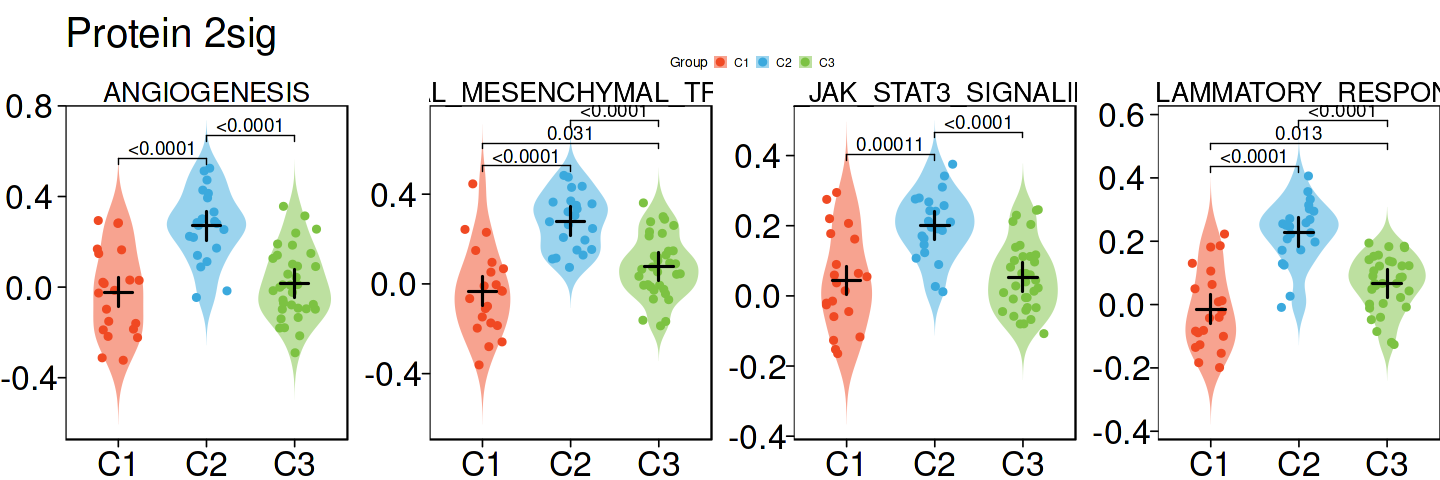

In [293]:
make.custom(12,4)
res$Protein$gg.2sig %T>% ysave('fig.S5D.cluster_C2_hm_violin',outputdir = OUTPUTROOT)
res$Protein$df.2sig %>% ysave('fig.S5D.cluster_C2_hm_violin',outputdir = OUTPUTROOT)

## fig S5E S5F

In [294]:
glx = db.importing('glx_86',frm=INPUTROOT)
tsb.pcr = glx %>% filter(Response=='pCR') %>% pull("tsb")
tsb.pcr %>% length

[1] "[ 2026-08-08 14:52:52 ]  read [ glx_86.dfx ] as ' glx_86 ' from >  export_c3"


[1] 9

In [295]:
timer2 = db.importing('export_big/estimation_matrix_frm_TPM.txt', frm='./') %>% 
    dplyr::select(!one_of(tsb.pcr))
# x = timer2$cell_type %>% str_split('_',simplify = TRUE)
# timer2 = timer2 %>% mutate(tool = x[,2],immune_cell=x[,1],.before = cell_type) %>% dplyr::select(!cell_type)
# timer2 %>% ydumpto('rna_timer2' ,outputdir = INPUTROOT)
timer2

[1] "[ 2026-08-08 14:52:52 ]  read [ estimation_matrix_frm_TPM.txt ] as ' estimation_matrix_frm_TPM ' from >  export_big"


tool,immune_cell,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,⋯,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TIMER,B cell,0.10047860,0.09452794,0.08935399,0.1137931,0.05830023,0.09182132,0.07142832,0.09951407,0.0750446,0.2005443,0.1077915,0.1233396,0.1242133,⋯,0.09141576,0.0812164,0.06598971,0.08126283,0.09612022,0.07962756,0.08803024,0.09200314,0.07301631,0.11874405,0.07816713,0.07890038,0.0908293,0.07992747,0.1144055
TIMER,T cell CD4+,0.09468192,0.13153552,0.15323243,0.1475723,0.11926657,0.11783247,0.12604510,0.12011638,0.1244208,0.1259290,0.1320701,0.1350576,0.1258830,⋯,0.09615568,0.1008351,0.10820859,0.07697116,0.13226824,0.08644969,0.07497028,0.09391142,0.11507615,0.07575681,0.12042994,0.14392527,0.1080741,0.13128030,0.1025655
TIMER,T cell CD8+,0.18707528,0.18348984,0.22543158,0.1853269,0.23975510,0.18647934,0.22237560,0.18424134,0.1828494,0.2085093,0.2101872,0.1816904,0.2055200,⋯,0.15526883,0.1921480,0.21960698,0.19164916,0.21909821,0.23215449,0.19299887,0.16164541,0.20239016,0.19437483,0.20329013,0.27000596,0.2160652,0.17479474,0.2004734
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋱,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
ESTIMATE,immune score,1028.4165227,938.9236447,1036.1081467,1370.7872210,1630.9006928,1357.9479886,1221.8253437,889.3941420,965.3387450,1494.1774617,1084.0270926,1200.0204604,1314.493823,⋯,820.2181467,603.6068052,1244.3320771,488.5286728,2489.2164997,710.2914751,418.5464823,558.9447762,681.2545845,928.4049456,765.0579915,1312.7114237,900.3874494,1120.7720452,1263.3238379
ESTIMATE,tumor purity score,1856.5179859,1901.6296153,2114.9546774,2759.1638129,3082.2478470,2823.7589214,2145.1544829,1735.4410193,1974.7100986,2417.1564835,2065.9265941,2003.9510422,2091.382218,⋯,1897.8378099,1118.3136474,2285.4714151,1400.2634266,3989.1050659,1969.9761405,1075.6067868,672.7704753,1354.5389698,1696.1017830,1703.0315448,1933.5103056,1913.0671606,2187.2569822,2430.7780567
ESTIMATE,tumor purity fraction,0.6390741,0.6339669,0.6094434,0.5318603,0.4911164,0.5238071,0.6059228,0.6526422,0.6256345,0.5736857,0.6151333,0.6222803,0.612183,⋯,0.6343973,0.7185072,0.5894101,0.6891147,0.3711571,0.6261764,0.7228532,0.7624261,0.6939629,0.6570065,0.6562393,0.6303409,0.6326676,0.6009948,0.5720468


In [296]:
col='Group'

timer_longer = timer2 %>%
    pivot_longer(-c(tool,immune_cell)
                 , names_to = 'tsb'
                 , values_to = 'value') %>% 
    left_join(glx, by='tsb') 

timer_longer

tool,immune_cell,tsb,value,Group,Response
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
TIMER,B cell,P01,0.10047860,C3,non.pCR
TIMER,B cell,P02,0.09452794,C3,non.pCR
TIMER,B cell,P03,0.08935399,C3,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮
ESTIMATE,tumor purity fraction,P84,0.6326676,C1,non.pCR
ESTIMATE,tumor purity fraction,P85,0.6009948,C2,non.pCR
ESTIMATE,tumor purity fraction,P86,0.5720468,C2,non.pCR


In [297]:
tool = 'ESTIMATE'
cur = timer_longer %>% dplyr::filter(tool==!!tool) %>% as.data.frame
cur

tool,immune_cell,tsb,value,Group,Response
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
ESTIMATE,stroma score,P01,828.1015,C3,non.pCR
ESTIMATE,stroma score,P02,962.7060,C3,non.pCR
ESTIMATE,stroma score,P03,1078.8465,C3,non.pCR
⋮,⋮,⋮,⋮,⋮,⋮
ESTIMATE,tumor purity fraction,P84,0.6326676,C1,non.pCR
ESTIMATE,tumor purity fraction,P85,0.6009948,C2,non.pCR
ESTIMATE,tumor purity fraction,P86,0.5720468,C2,non.pCR


In [298]:
stat = cur %>% ggpubr::compare_means(formula = value~Group, group.by = 'immune_cell')
stat = stat %>% group_by(immune_cell) %>% group_map(.keep = TRUE,function(df, g){
    df %>% mutate(p.adj = rstatix::adjust_pvalue(p))
}) %>% bind_rows()

stat

immune_cell,.y.,group1,group2,p,p.adj,p.format,p.signif,method
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
immune score,value,C3,C2,5.197466e-05,5.197466e-05,5.2e-05,****,Wilcoxon
immune score,value,C3,C1,3.306477e-01,3.306477e-01,0.33065,ns,Wilcoxon
immune score,value,C2,C1,5.511816e-04,5.511816e-04,0.00055,***,Wilcoxon
⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮,⋮
tumor purity score,value,C3,C2,2.981202e-06,2.981202e-06,3.0e-06,****,Wilcoxon
tumor purity score,value,C3,C1,1.491435e-01,1.491435e-01,0.14914,ns,Wilcoxon
tumor purity score,value,C2,C1,3.413091e-05,3.413091e-05,3.4e-05,****,Wilcoxon


In [299]:
cur$immune_cell %>% unique

[1] "stroma score"          "immune score"          "tumor purity score"   
[4] "tumor purity fraction"

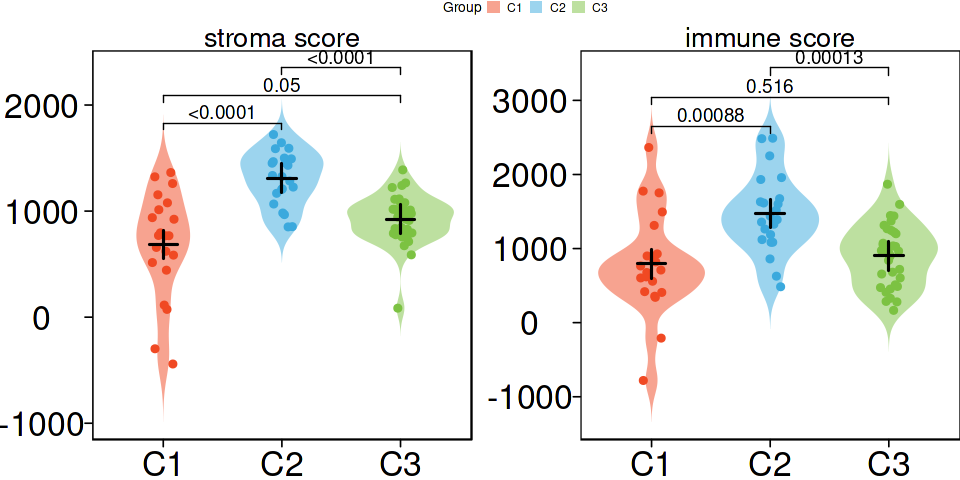

In [300]:
make.custom(8,4)
sel.cells = c('stroma score','immune score')
gg.s4e.s4f = cur %>% 
    filter(immune_cell %in% sel.cells) %>%
    mutate(immune_cell = factor(immune_cell, levels = !!sel.cells)) %>%
    ggplot(aes(x=Group,y=value)) + 
    geom_violin(aes(fill=Group),color=NA, trim = FALSE, alpha = 0.5) +

    geom_point(aes(color=Group)
               ,show.legend = FALSE
#            ,size=0.2
#            ,alpha = 0.5
           ,position=position_jitterdodge(jitter.width = 0.2
                                          ,dodge.width = 0.8)
          ) +
    stat_summary(fun = mean, geom = "point", color= 'black', shape = 3, size = 5, stroke = 1) +
    theme_pc() +

    facet_wrap(~immune_cell,scales = 'free',ncol=4) +
#     labs(title = paste(tool,'Compare between Groups')) +
    xlab(NULL) +
    ylab(NULL) +
    scale_color_manual(breaks = names(COL_ANNO$Group), values = COL_ANNO$Group) +
    scale_fill_manual(breaks = names(COL_ANNO$Group), values = COL_ANNO$Group) +

    ggpubr::stat_pwc(method = 't.test') 

gg.s4e.s4f



In [301]:
gg.s4e.s4f %>% ysave('fig.S5E.S5F.estimate_imm_score_violin',outputdir = OUTPUTROOT)
cur %>% filter(immune_cell %in% sel.cells) %>% mutate(immune_cell = factor(immune_cell, levels = !!sel.cells)) %>% ysave('fig.S5E.S5F.estimate_imm_score_violin',outputdir = OUTPUTROOT)

[1] "[ 2026-08-08 14:52:53 ]  write 1 pdf at report_c3/fig.S5E.S5F.estimate_imm_score_violin.pdf"
[1] "[ 2026-08-08 14:52:53 ]  write 1 xlsx at report_c3/fig.S5E.S5F.estimate_imm_score_violin.xlsx"
